## INTRO

In [1]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt 
from scipy.stats import pearsonr, spearmanr, kendalltau

In [2]:
path_wd = Path.cwd()
path_dir = path_wd.parent

## Functions

In [3]:
def lagged_corr(group, max_lag=4):
    """
    max_lag in number of rows (e.g. 4 = 4 intervals).
    Positive lag k: price shifted earlier, i.e. price_{t-k} vs flex_t.
    """
    out = {}
    for lag in range(0, max_lag + 1):
        shifted_price = group['price'].shift(lag)
        out[f'lag_{lag}'] = group['flex_volume'].corr(shifted_price)
    return pd.Series(out)

# lagged_by_market = df.groupby('market').apply(lagged_corr, max_lag=4)
# print(lagged_by_market)


In [ ]:
def clean_xy(df, xcol, ycol, lag=0):
    # coerce to numeric just in case
    x = pd.to_numeric(df[xcol], errors='coerce').shift(lag)
    y = pd.to_numeric(df[ycol], errors='coerce')
    m = x.notna() & y.notna()
    x, y = x[m].values, y[m].values
    # guard against tiny/constant samples that make tests return nan
    if x.size < 2 or y.size < 2:
        return None, None
    if np.allclose(x, x[0]) or np.allclose(y, y[0]):
        return None, None
    return x, y


: 

## DFS graphes

In [29]:
pricesDFS_past = pd.read_csv(path_dir / 'data/dfs-utilisation-report-past.csv', parse_dates=['Delivery Date'])
pricesDFS_past.set_index('Delivery Date', inplace=True)

pricesDFS = pd.read_csv(path_dir / 'data/dfs-utilisation-report (1).csv') ##the past report only has live events till 2023-12-01
pricesDFS['date'] = pd.to_datetime(pricesDFS['Delivery Date'] + ' ' + pricesDFS['From'], dayfirst = True)
pricesDFS.set_index('date', inplace=True)
#volumes residential vs c&i
pricesDFS.sort_index(inplace =True)

DFS_data = pd.concat([pricesDFS_past,pricesDFS])
# DFS_data = DFS_data[(DFS_data['Status'] != 'Rejected')]
# DFS_data = DFS_data[(DFS_data['Service Requirement Type'] == 'Live')]

DFS_data.drop_duplicates(inplace=True)

DFS_data

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_27212\2488472674.py:1: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  pricesDFS_past = pd.read_csv(path_dir / 'data/dfs-utilisation-report-past.csv', parse_dates=['Delivery Date'])


,Registered DFS Participant,DFS Unit ID,DFS Volume MW,From,To,Service Requirement Type,Despatch Time,Utilisation Price GBP per MWh,Status,North Scotland,...,East England,South East England,South West England,Southern England,"North Wales, Merseyside and Cheshire",South Wales,Other,Total,Delivery Date,North Wales Merseyside and Cheshire
2024-03-21 00:00:00,AXLE ENERGY LIMITED,Axle-01,10.0,17:30,18:00,Test,within-day 2,698.0,Accepted,0.0,...,0.00000,0.0,0.000,0.0000,0.00000,0.0,10.0,10.0,NaN,NaN
2024-03-21 00:00:00,CONRAD ENERGY (TRADING) LIMITED,CONRAD-02,3.0,17:30,18:00,Test,within-day 2,497.0,Accepted,0.0,...,0.00000,0.0,3.000,0.0000,0.00000,0.0,0.0,3.0,NaN,NaN
2024-03-21 00:00:00,CONRAD ENERGY (TRADING) LIMITED,CONRAD-02,3.0,18:30,19:00,Test,within-day 2,497.0,Accepted,0.0,...,0.00000,0.0,3.000,0.0000,0.00000,0.0,0.0,3.0,NaN,NaN
2024-03-21 00:00:00,CUB (UK) LTD,CUB-01,2.0,18:30,19:00,Test,within-day 2,748.0,Accepted,0.0,...,0.39675,0.0,0.012,0.0675,0.13725,0.0,0.0,2.0,NaN,NaN
2024-03-21 00:00:00,DRAX ENERGY SOLUTIONS LIMITED,DRAX-02,4.0,17:30,18:00,Test,within-day 2,725.0,Accepted,0.0,...,0.80000,0.8,0.000,1.6000,0.00000,0.0,0.0,4.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-09-08 21:00:00,INFINIS LIMITED,INFINS-01,29.0,21:00,21:30,Live,NaN,100.0,Accepted,0.0,...,0.00000,0.0,0.000,0.0000,NaN,0.0,29.0,29.0,08/09/2025,0.0
2025-09-08 21:30:00,HILDEBRAND TECHNOLOGY LIMITED,HLDBRD-01,1.0,21:30,22:00,Live,NaN,116.0,Accepted,0.0,...,0.00000,0.0,0.000,0.0000,NaN,0.0,1.0,1.0,08/09/2025,0.0
2025-09-08 21:30:00,INFINIS LIMITED,INFINS-01,27.6,21:30,22:00,Live,NaN,100.0,Accepted,0.0,...,0.00000,0.0,0.000,0.0000,NaN,0.0,27.6,27.6,08/09/2025,0.0
2025-09-08 22:00:00,HILDEBRAND TECHNOLOGY LIMITED,HLDBRD-01,1.0,22:00,22:30,Live,NaN,113.0,Rejected,0.0,...,0.00000,0.0,0.000,0.0000,NaN,0.0,1.0,1.0,08/09/2025,0.0


In [32]:
DFS_data['Registered DFS Participant'].value_counts()

Registered DFS Participant
INFINIS LIMITED                                2470
GRIDBEYOND LIMITED                             2106
OAKTREE POWER LIMITED                           885
HILDEBRAND TECHNOLOGY LIMITED                   532
GRIDIMP LTD                                     433
OCTOPUS ENERGY LIMITED                          349
EQUIWATT LIMITED                                273
CUB (UK) LTD                                    245
AXLE ENERGY LIMITED                             244
GALLAGHER AGGREGATES LIMITED                    242
UTILITA ENERGY LIMITED                          190
DRAX ENERGY SOLUTIONS LIMITED                   172
SOLO ENERGY LIMITED                             146
ENGIE POWER LIMITED                              85
SSE DIGITAL SERVICES LIMITED                     69
PERSE TECHNOLOGY LIMITED                         67
E.ON NEXT ENERGY LIMITED                         55
EDF ENERGY CUSTOMERS LIMITED                     49
OVO ELECTRICITY LTD                  

### Correlations

In [49]:
DFS_data['vol_wz']   = DFS_data.groupby('Registered DFS Participant')['DFS Volume MW'].transform(lambda s: (s - s.mean())/s.std(ddof=0))
DFS_data['price_wz'] = DFS_data.groupby('Registered DFS Participant')['Utilisation Price GBP per MWh'].transform(lambda s: (s - s.mean())/s.std(ddof=0))

In [54]:
DFS_data.shape[0] *0.1

876.8000000000001

In [ ]:
for provider in DFS_data['Registered DFS Participant'].unique():
    
    for status in ['Rejected', 'Accepted']:
        for event in ['Live', 'Test', 0]:

            for corr, pval in zip(['pearson', 'spearman', 'kendall'], [pearsonr, spearmanr, kendalltau]):
            
                panel = DFS_data[(DFS_data['Status'] == status) & (DFS_data['Service Requirement Type'] != event) & (DFS_data['Registered DFS Participant']==provider)]
                
                if panel.shape[0] < 20:
                    continue
                
                x, y = clean_xy(
                panel,
                xcol='price_wz',
                ycol='vol_wz',
                lag=0
            )
                if x is None:
                    continue
                
                print(provider)
                
                coef, pval = pval(x, y)
                if event == 0:
                    print(f"with both live and test events, {round(coef,3)} for {corr} with pval {round(pval,3)}")
                                
                else:
                    print(f"{status}, removed {event}: {round(coef,3)} for {corr} with pval {round(pval,3)}")
        
## INTERPRETATION: 
# Accepted sets: weak positive correlation (seems higher prices more flex for test events) and Rejected sets: near-zero or slight negative --> directionally sensible 
# Still, coef are too small --> no evidence that price is a leading factor or that providers are price-responsive.

# Per provider

AXLE ENERGY LIMITED
Rejected, removed Test: 0.086 for pearson with pval 0.232
AXLE ENERGY LIMITED
Rejected, removed Test: 0.069 for spearman with pval 0.338
AXLE ENERGY LIMITED
Rejected, removed Test: 0.063 for kendall with pval 0.331
AXLE ENERGY LIMITED
with both live and test events, 0.387 for pearson with pval 0.0
AXLE ENERGY LIMITED
with both live and test events, 0.199 for spearman with pval 0.005
AXLE ENERGY LIMITED
with both live and test events, 0.178 for kendall with pval 0.005
AXLE ENERGY LIMITED
Accepted, removed Test: 0.331 for pearson with pval 0.099
AXLE ENERGY LIMITED
Accepted, removed Test: 0.219 for spearman with pval 0.282
AXLE ENERGY LIMITED
Accepted, removed Test: 0.2 for kendall with pval 0.227
AXLE ENERGY LIMITED
with both live and test events, 0.268 for pearson with pval 0.082
AXLE ENERGY LIMITED
with both live and test events, 0.275 for spearman with pval 0.075
AXLE ENERGY LIMITED
with both live and test events, 0.223 for kendall with pval 0.073
CUB (UK) LTD
Rej

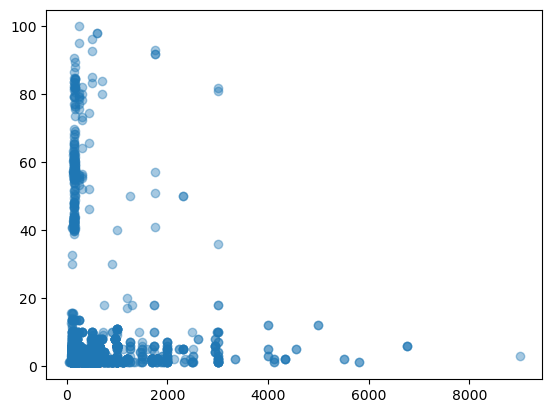

In [107]:
plt.scatter(DFS_data[DFS_data['Status'] == 'Rejected']['Utilisation Price GBP per MWh'], DFS_data[DFS_data['Status'] == 'Rejected']['DFS Volume MW'], alpha= 0.4)

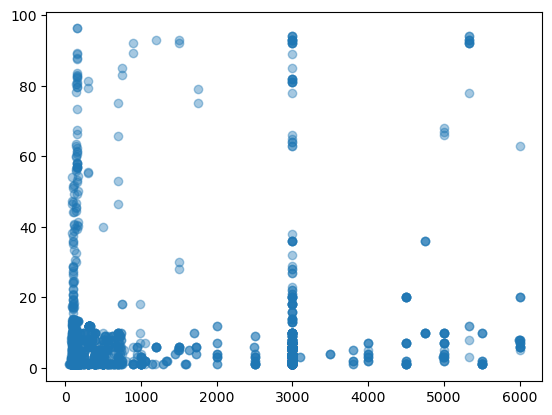

In [106]:
plt.scatter(DFS_data[DFS_data['Status'] == 'Accepted']['Utilisation Price GBP per MWh'], DFS_data[DFS_data['Status'] == 'Accepted']['DFS Volume MW'], alpha= 0.4)

### Season graphes

In [7]:
DFS_data["season"] = np.where(
    DFS_data.index.month.isin([12, 1, 2]), "Winter",
    np.where(DFS_data.index.month.isin([3,4,5]), "Spring",
             np.where(DFS_data.index.month.isin([6,7,8]), "Summer",
                      "Autumn"))
)

DFS_data["Year"] = DFS_data.index.year

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_16892\3617134619.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


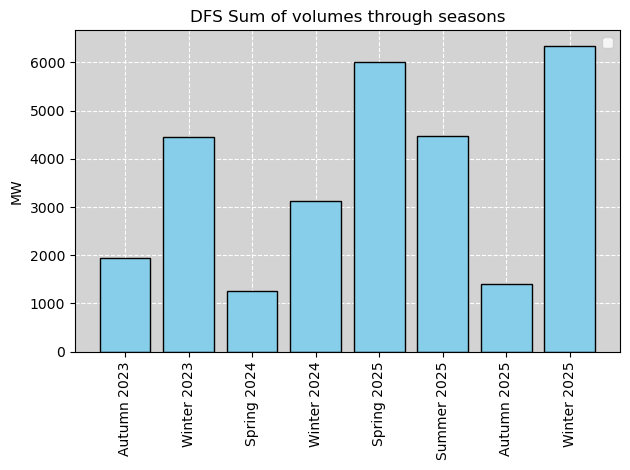

In [ ]:
# group
panel = DFS_data.groupby(['season', 'Year'])['DFS Volume MW'].agg(["sum"]).reset_index()

# ✅ set your custom chronological order
season_order = ["Spring", "Summer", "Autumn", "Winter"]
panel["season"] = pd.Categorical(panel["season"], categories=season_order, ordered=True)

# ✅ sort by year first, then by season (in the order above)
panel = panel.sort_values(["Year", "season"]).reset_index(drop=True)

# labels AFTER sorting
panel["label"] = panel["season"].astype(str) + " " + panel["Year"].astype(str)

# plot
plt.bar(panel["label"], panel["sum"], color="skyblue", edgecolor="black")

plt.xticks(rotation=90)
plt.gca().set_facecolor('lightgrey')
plt.grid(color='white', linestyle='--', linewidth=0.8)
plt.gca().set_axisbelow(True)
plt.ylabel("MW")
plt.title("DFS Sum of volumes through seasons")
plt.legend()
plt.tight_layout()
plt.show()


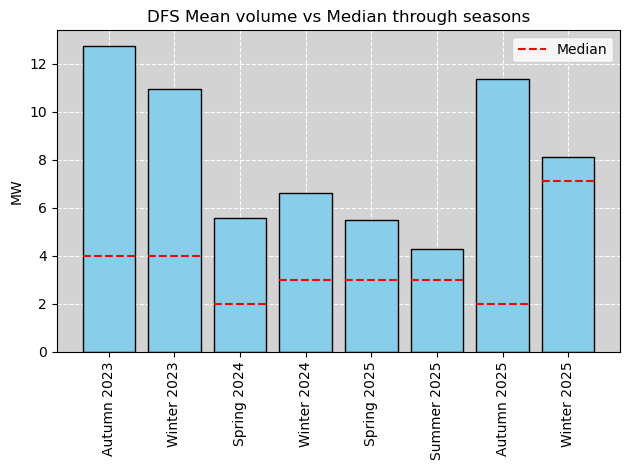

In [ ]:
# group
panel = DFS_data.groupby(['season', 'Year'])['DFS Volume MW'].agg(["mean", "median", 'min', 'max']).reset_index()

# ✅ set your custom chronological order
season_order = ["Spring", "Summer", "Autumn", "Winter"]
panel["season"] = pd.Categorical(panel["season"], categories=season_order, ordered=True)

# ✅ sort by year first, then by season (in the order above)
panel = panel.sort_values(["Year", "season"]).reset_index(drop=True)

# labels AFTER sorting
panel["label"] = panel["season"].astype(str) + " " + panel["Year"].astype(str)

# plot
plt.bar(panel["label"], panel["mean"], color="skyblue", edgecolor="black")
plt.hlines(panel["median"],
           xmin=[i - 0.4 for i in range(len(panel))],
           xmax=[i + 0.4 for i in range(len(panel))],
           colors="red", linestyles="--", label="Median")

plt.xticks(rotation=90)
plt.gca().set_facecolor('lightgrey')
plt.grid(color='white', linestyle='--', linewidth=0.8)
plt.gca().set_axisbelow(True)
plt.ylabel("MW")
plt.title("DFS Mean volume vs Median through seasons")
plt.legend()
plt.tight_layout()
plt.show()


### for volumes

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_17604\3290205275.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


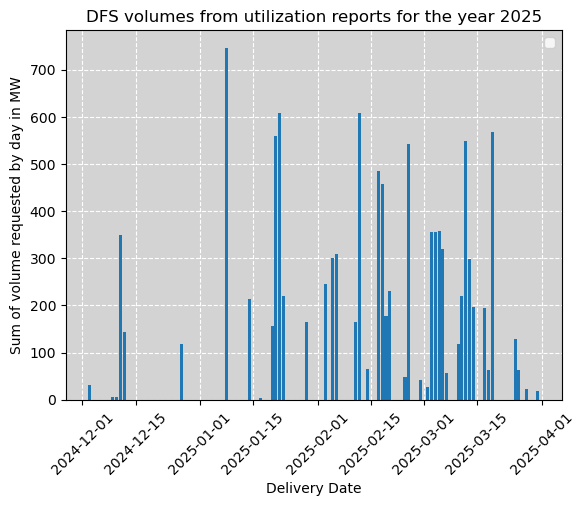

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_17604\3290205275.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


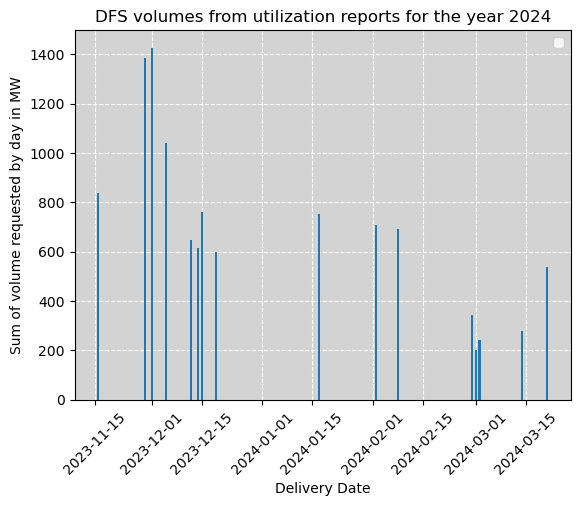

In [ ]:
panel = pricesDFS.loc[:'2025-03']
agg = panel['DFS Volume MW'].groupby(panel.index.date).sum()


plt.bar(agg.index, agg, width=0.8)
plt.xticks(rotation=45)
plt.gca().set_facecolor('lightgrey')
plt.grid(color='white', linestyle='--', linewidth=0.8)
plt.gca().set_axisbelow(True) 

plt.ylabel('Sum of volume requested by day in MW')
plt.xlabel('Delivery Date')
plt.title('DFS volumes from utilization reports for the year 2025')
plt.legend()
plt.show()

agg = pricesDFS_past['DFS Volume MW'].groupby(pricesDFS_past.index.date).sum()


plt.bar(agg.index, agg, width=0.6)
plt.xticks(rotation=45)
plt.gca().set_facecolor('lightgrey')
plt.grid(color='white', linestyle='--', linewidth=0.8)
plt.gca().set_axisbelow(True) 

plt.ylabel('Sum of volume requested by day in MW')
plt.xlabel('Delivery Date')
plt.title('DFS volumes from utilization reports for the year 2024')
plt.legend()
plt.show()


### for prices

In [ ]:
panel = pricesDFS.loc[:'2025-03']

agg_price = panel['Utilisation Price GBP per MWh'].resample('H').mean()
agg_price_past = pricesDFS_past['Utilisation Price GBP per MWh'].resample('H').mean()

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_17604\1315582630.py:3: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  agg_price = df['Utilisation Price GBP per MWh'].resample('H').mean()
C:\Users\Duval1e\AppData\Local\Temp\ipykernel_17604\1315582630.py:4: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  agg_price_past = pricesDFS_past['Utilisation Price GBP per MWh'].resample('H').mean()


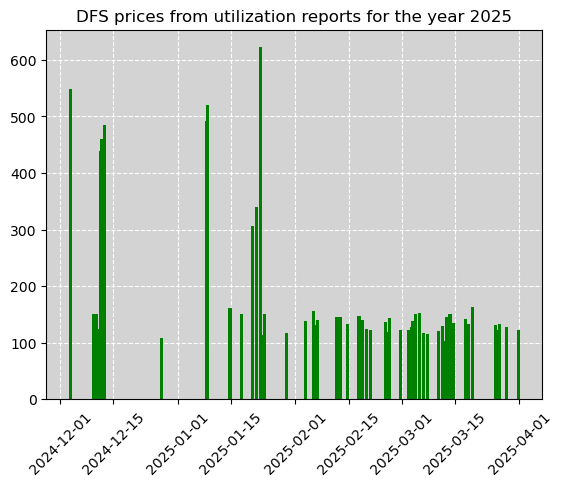

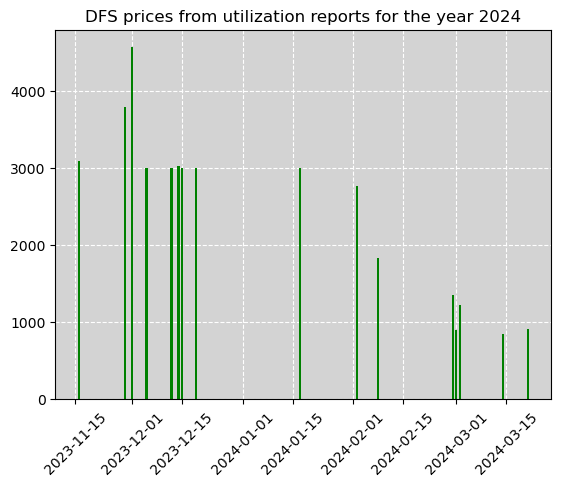

In [ ]:

plt.bar(agg_price.index, agg_price, width=0.8, color = 'green')
plt.title('DFS prices from utilization reports for the year 2025')

plt.xticks(rotation=45)
plt.gca().set_facecolor('lightgrey')
plt.grid(color='white', linestyle='--', linewidth=0.8)
plt.gca().set_axisbelow(True) 

plt.xticks(rotation=45)

plt.show() 

plt.bar(agg_price_past.index, agg_price_past, width=0.6, color = 'green')
plt.title('DFS prices from utilization reports for the year 2024')

plt.xticks(rotation=45)
plt.gca().set_facecolor('lightgrey')
plt.grid(color='white', linestyle='--', linewidth=0.8)
plt.gca().set_axisbelow(True) 

plt.xticks(rotation=45)

plt.show() 


## ENAPSYS graphes


In [9]:
pricesENAPSYS = pd.read_csv(
    path_dir / "data/prices-ancillary-elec_ENAPSYS.csv", index_col=0, header=[0, 1]
)
pricesENAPSYS.index = pd.to_datetime(
    pricesENAPSYS.index.str.replace(r"[\[\]\(\)\{\}]", "", regex=True), dayfirst=True
)
pricesENAPSYS = pricesENAPSYS[[
    ("Dynamic Containment High", "GBP/MW/h"),
    ("Dynamic Containment Low", "GBP/MW/h"),
    ("Dynamic Moderation High", "GBP/MW/h"),
    ("Dynamic Moderation Low", "GBP/MW/h"),
    ("Dynamic Regulation High", "GBP/MW/h"),
    ("Dynamic Regulation Low", "GBP/MW/h"),
    ("Static FFR", "GBP/MW/h"),
    ("STOR (DAY AHEAD)", "GBP/MW/h")]
]
pricesENAPSYS

Date (WET),Dynamic Containment High,Dynamic Containment Low,Dynamic Moderation High,Dynamic Moderation Low,Dynamic Regulation High,Dynamic Regulation Low,Static FFR,STOR (DAY AHEAD)
,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h
2020-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,2.50,NaN
2020-01-01 00:30:00,NaN,NaN,NaN,NaN,NaN,NaN,2.50,NaN
2020-01-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,2.50,NaN
2020-01-01 01:30:00,NaN,NaN,NaN,NaN,NaN,NaN,2.50,NaN
2020-01-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,2.50,NaN
...,...,...,...,...,...,...,...,...
2025-06-30 21:30:00,0.79,6.70,-0.32,11.54,-10.45,27.47,7.00,1.49
2025-06-30 22:00:00,1.60,2.12,0.43,6.17,-8.22,17.89,7.00,NaN
2025-06-30 22:30:00,1.60,2.12,0.43,6.17,-8.22,17.89,7.00,NaN


In [10]:
volumesENAPSYS = pd.read_csv(path_dir / 'data/volumes-ancillary-elec_ENAPSYS.csv', index_col=0, header=[0, 1])
volumesENAPSYS.index = pd.to_datetime(volumesENAPSYS.index.str.replace(r'[\[\]\(\)\{\}]', '', regex=True),
                              dayfirst = True)

volumesENAPSYS = volumesENAPSYS[[
    ("Dynamic Containment High", "MW"),
    ("Dynamic Containment Low", "MW"),
    ("Dynamic Moderation High", "MW"),
    ("Dynamic Moderation Low", "MW"),
    ("Dynamic Regulation High", "MW"),
    ("Dynamic Regulation Low", "MW"),
    ("Static FFR", "MW"),
    ("STOR (DAY AHEAD)", "MW")]
]
volumesENAPSYS
    

Date (WET),Dynamic Containment High,Dynamic Containment Low,Dynamic Moderation High,Dynamic Moderation Low,Dynamic Regulation High,Dynamic Regulation Low,Static FFR,STOR (DAY AHEAD)
,MW,MW,MW,MW,MW,MW,MW,MW
2020-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
2020-01-01 00:30:00,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
2020-01-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
2020-01-01 01:30:00,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
2020-01-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
...,...,...,...,...,...,...,...,...
2025-06-30 21:30:00,848.0,2235.0,-617.0,586.0,-916.0,800.0,250.0,1584.0
2025-06-30 22:00:00,839.0,2219.0,-570.0,599.0,-904.0,774.0,250.0,0.0
2025-06-30 22:30:00,839.0,2219.0,-570.0,599.0,-904.0,774.0,250.0,0.0


In [22]:
volumesENAPSYS.columns

MultiIndex([('Dynamic Containment High', 'MW'),
            ( 'Dynamic Containment Low', 'MW'),
            ( 'Dynamic Moderation High', 'MW'),
            (  'Dynamic Moderation Low', 'MW'),
            ( 'Dynamic Regulation High', 'MW'),
            (  'Dynamic Regulation Low', 'MW'),
            (              'Static FFR', 'MW'),
            (        'STOR (DAY AHEAD)', 'MW'),
            (                  'season',   ''),
            (                    'Year',   '')],
           names=['Date (WET)', None])

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_9340\4275564798.py:20: PerformanceWarning: indexing past lexsort depth may impact performance.
  .sort_values([('Year', '')]))


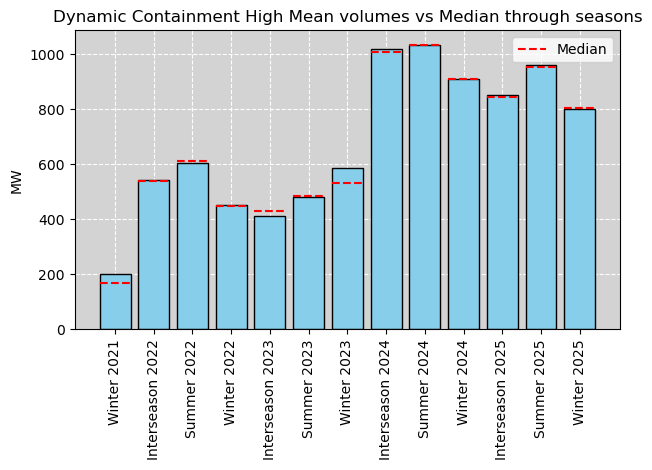

Date (WET)       season  Year Dynamic Containment High       
                                                    MW       
                                                   max    min
8                Winter  2021                    528.0    8.0
0           Interseason  2022                    916.0  141.0
4                Summer  2022                    927.0  288.0
9                Winter  2022                    983.0    8.0
1           Interseason  2023                    645.0   71.0
5                Summer  2023                    667.0  323.0
10               Winter  2023                   1178.0   88.0
2           Interseason  2024                   1401.0  787.0
6                Summer  2024                   1401.0  828.0
11               Winter  2024                   1184.0  346.0
3           Interseason  2025                   1035.0  679.0
7                Summer  2025                   1163.0  800.0
12               Winter  2025                    990.0  402.0


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_9340\4275564798.py:20: PerformanceWarning: indexing past lexsort depth may impact performance.
  .sort_values([('Year', '')]))


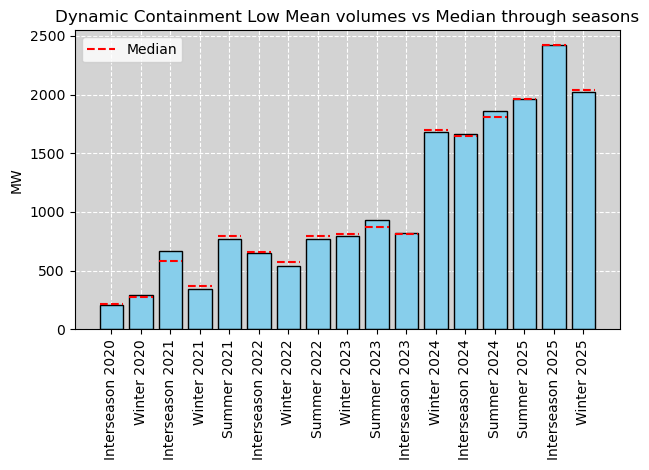

Date (WET)       season  Year Dynamic Containment Low        
                                                   MW        
                                                  max     min
0           Interseason  2020                   275.0    90.0
11               Winter  2020                   369.0   208.0
1           Interseason  2021                   981.0    80.0
12               Winter  2021                   747.0     1.0
6                Summer  2021                   929.0   584.0
2           Interseason  2022                  1148.0   158.0
13               Winter  2022                   947.0     5.0
7                Summer  2022                  1058.0   258.0
14               Winter  2023                  1105.0   318.0
8                Summer  2023                  1536.0   607.0
3           Interseason  2023                  1254.0   386.0
15               Winter  2024                  2248.0  1213.0
4           Interseason  2024                  2237.0  1294.0
9       

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_9340\4275564798.py:20: PerformanceWarning: indexing past lexsort depth may impact performance.
  .sort_values([('Year', '')]))


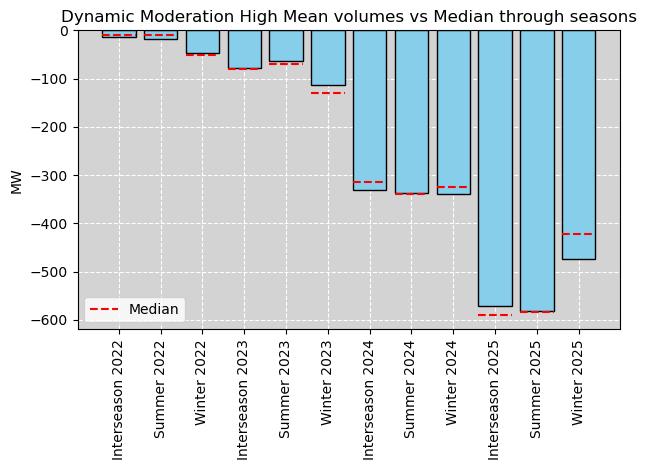

Date (WET)       season  Year Dynamic Moderation High       
                                                   MW       
                                                  max    min
0           Interseason  2022                    -1.0  -50.0
4                Summer  2022                    -1.0  -69.0
8                Winter  2022                    -2.0  -93.0
1           Interseason  2023                    -1.0 -170.0
5                Summer  2023                    -2.0 -100.0
9                Winter  2023                    -4.0 -170.0
2           Interseason  2024                  -102.0 -955.0
6                Summer  2024                   -74.0 -902.0
10               Winter  2024                   -44.0 -976.0
3           Interseason  2025                   -94.0 -640.0
7                Summer  2025                  -278.0 -636.0
11               Winter  2025                     0.0 -640.0


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_9340\4275564798.py:20: PerformanceWarning: indexing past lexsort depth may impact performance.
  .sort_values([('Year', '')]))


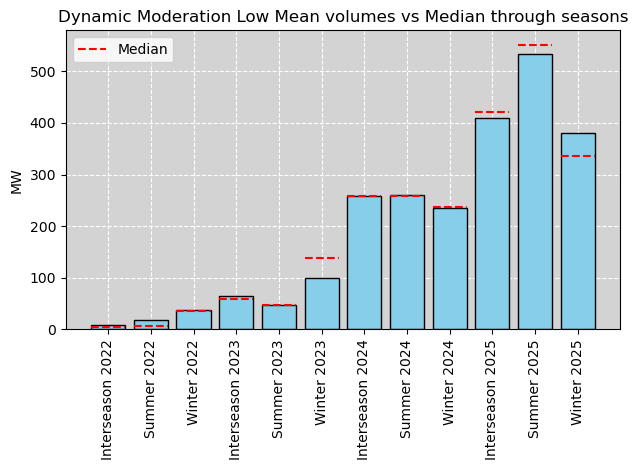

Date (WET)       season  Year Dynamic Moderation Low       
                                                  MW       
                                                 max    min
0           Interseason  2022                   32.0    1.0
4                Summer  2022                   70.0    1.0
8                Winter  2022                   91.0    1.0
1           Interseason  2023                  166.0    1.0
5                Summer  2023                   88.0    2.0
9                Winter  2023                  158.0    0.0
2           Interseason  2024                  559.0   78.0
6                Summer  2024                  637.0   56.0
10               Winter  2024                  648.0    0.0
3           Interseason  2025                  600.0   48.0
7                Summer  2025                  601.0  233.0
11               Winter  2025                  600.0    0.0


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_9340\4275564798.py:20: PerformanceWarning: indexing past lexsort depth may impact performance.
  .sort_values([('Year', '')]))


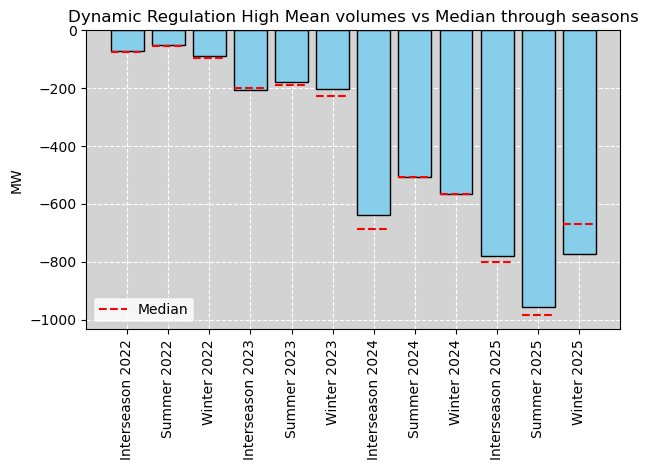

Date (WET)       season  Year Dynamic Regulation High        
                                                   MW        
                                                  max     min
0           Interseason  2022                    -4.0  -100.0
4                Summer  2022                    -3.0  -100.0
8                Winter  2022                   -19.0  -100.0
1           Interseason  2023                   -73.0  -274.0
5                Summer  2023                   -48.0  -200.0
9                Winter  2023                   -24.0  -350.0
2           Interseason  2024                  -179.0  -716.0
6                Summer  2024                  -205.0  -700.0
10               Winter  2024                  -185.0  -700.0
3           Interseason  2025                  -271.0  -991.0
7                Summer  2025                  -304.0 -1000.0
11               Winter  2025                  -449.0 -1000.0


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_9340\4275564798.py:20: PerformanceWarning: indexing past lexsort depth may impact performance.
  .sort_values([('Year', '')]))


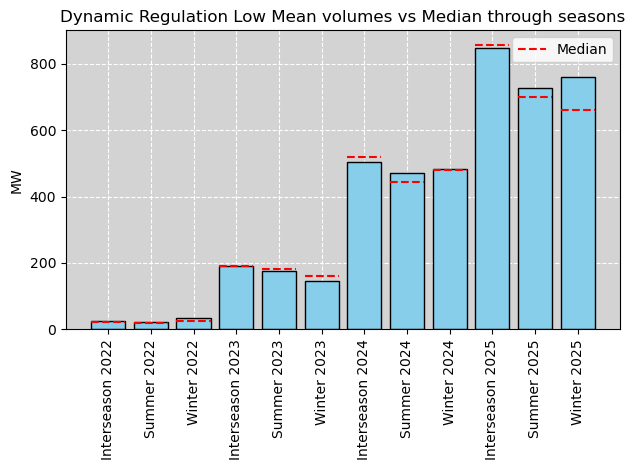

Date (WET)       season  Year Dynamic Regulation Low       
                                                  MW       
                                                 max    min
0           Interseason  2022                   65.0    1.0
4                Summer  2022                   65.0    2.0
8                Winter  2022                   86.0    1.0
1           Interseason  2023                  254.0   61.0
5                Summer  2023                  200.0   77.0
9                Winter  2023                  330.0    1.0
2           Interseason  2024                  660.0  263.0
6                Summer  2024                  660.0  276.0
10               Winter  2024                  660.0  204.0
3           Interseason  2025                  964.0  538.0
7                Summer  2025                  960.0  427.0
11               Winter  2025                  960.0  286.0


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_9340\4275564798.py:20: PerformanceWarning: indexing past lexsort depth may impact performance.
  .sort_values([('Year', '')]))


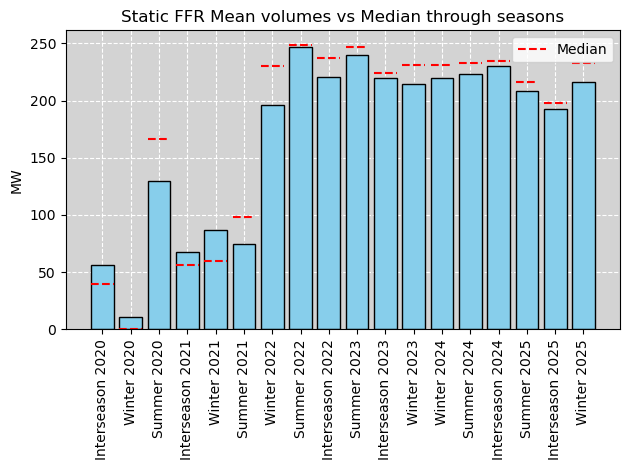

Date (WET)       season  Year Static FFR       
                                      MW       
                                     max    min
0           Interseason  2020      176.0    0.0
12               Winter  2020       63.0    0.0
6                Summer  2020      227.0    0.0
1           Interseason  2021      195.0    0.0
13               Winter  2021      257.0    0.0
7                Summer  2021      136.0    0.0
14               Winter  2022      371.0  100.0
8                Summer  2022      361.0  187.0
2           Interseason  2022      377.0  108.0
9                Summer  2023      279.0  164.0
3           Interseason  2023      355.0  100.0
15               Winter  2023      371.0   93.0
16               Winter  2024      263.0   72.0
10               Summer  2024      265.0   80.0
4           Interseason  2024      264.0   94.0
11               Summer  2025      253.0   54.0
5           Interseason  2025      250.0  102.0
17               Winter  2025      259.0

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_9340\4275564798.py:20: PerformanceWarning: indexing past lexsort depth may impact performance.
  .sort_values([('Year', '')]))


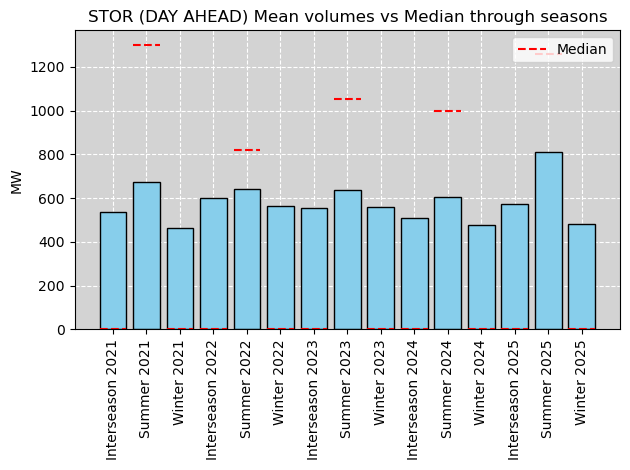

Date (WET)       season  Year STOR (DAY AHEAD)     
                                            MW     
                                           max  min
0           Interseason  2021           1331.0  0.0
5                Summer  2021           1313.0  0.0
10               Winter  2021           1596.0  0.0
1           Interseason  2022           1742.0  0.0
6                Summer  2022           1538.0  0.0
11               Winter  2022           1586.0  0.0
2           Interseason  2023           1977.0  0.0
7                Summer  2023           2102.0  0.0
12               Winter  2023           1770.0  0.0
3           Interseason  2024           1387.0  0.0
8                Summer  2024           1429.0  0.0
13               Winter  2024           1374.0  0.0
4           Interseason  2025           1779.0  0.0
9                Summer  2025           1792.0  0.0
14               Winter  2025           1324.0  0.0


ValueError: Grouper for '('season', '')' not 1-dimensional

In [ ]:
volumesENAPSYS["season"] = np.where(
    volumesENAPSYS.index.month.isin([11, 12, 1, 2]), "Winter",
    np.where(volumesENAPSYS.index.month.isin([5,6,7,8]), "Summer", "Interseason")
)

volumesENAPSYS["Year"] = volumesENAPSYS.index.year

for service in volumesENAPSYS.columns.get_level_values(0):
    cols = [service, 'season', 'Year']
    filter_service = volumesENAPSYS.loc[:, cols].dropna()
    
    panel = (
    filter_service
    .groupby([('season', ''), ('Year', '')])
    [[
        (f'{service}', 'MW'),
    ]]
    .agg(['mean', 'median', 'min', 'max'])
    .reset_index()
    .sort_values([('Year', '')]))

    # Make combined label for x-axis (e.g. "Spring-2023")
    panel["label"] = panel["season"] + " " + panel["Year"].astype(str)
    
    # Bar plot of means
    plt.bar(panel["label"], panel[(f'{service}', 'MW',   'mean')], color="skyblue", edgecolor="black")

    
    # Add median line across each bar
    
    plt.hlines(panel[(f'{service}', 'MW',   'median')], xmin=[i - 0.4 for i in range(len(panel))],
                xmax=[i + 0.4 for i in range(len(panel))],
                colors="red", linestyles="--", label="Median")


    plt.xticks(rotation=90)
    plt.gca().set_facecolor('lightgrey')
    plt.grid(color='white', linestyle='--', linewidth=0.8)
    plt.gca().set_axisbelow(True) 
        
    plt.ylabel("MW")
    plt.title(f"{service} Mean volumes vs Median through seasons")
    plt.legend()
    plt.tight_layout()
    plt.show()
    print(panel.iloc[:, [0, 1, -2, -3]]
)


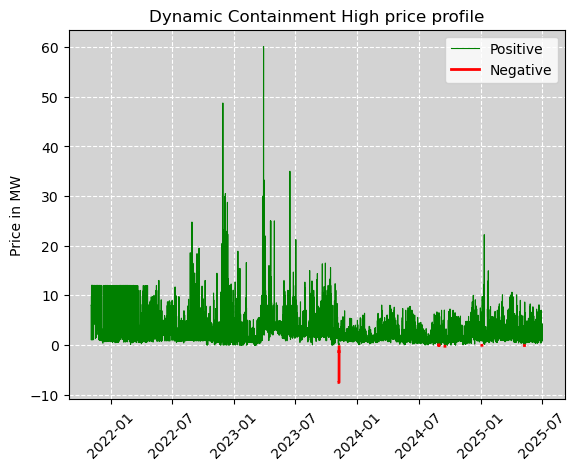

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_17604\3070967694.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


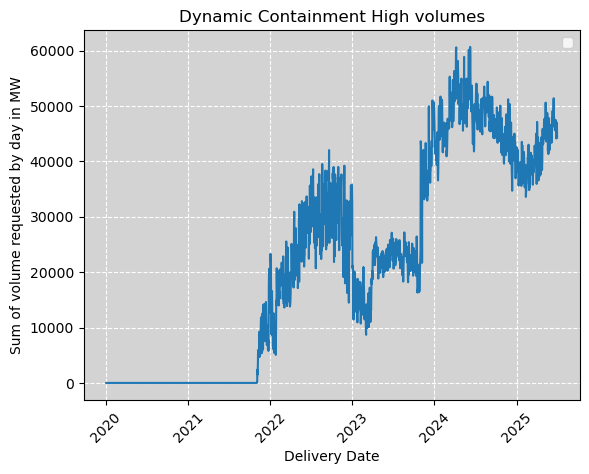

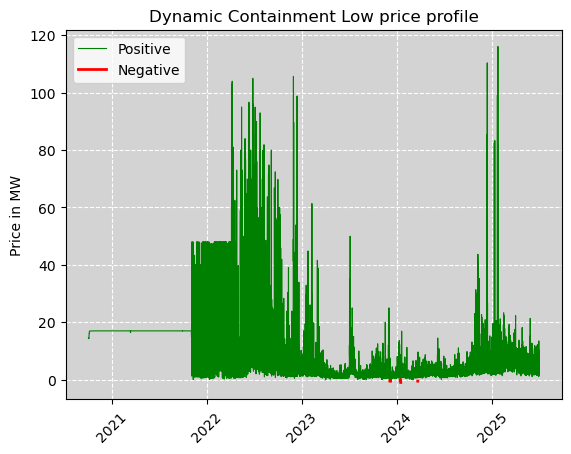

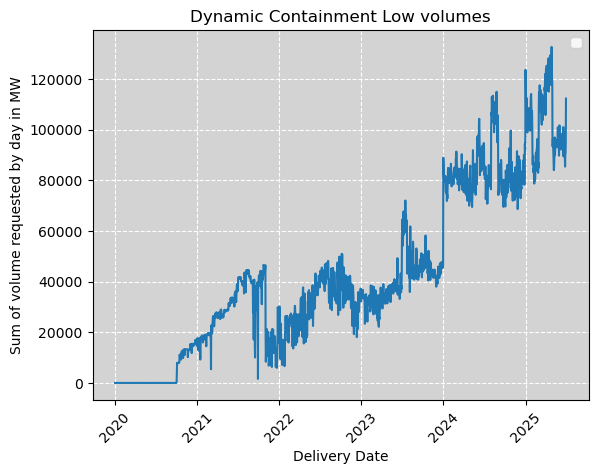

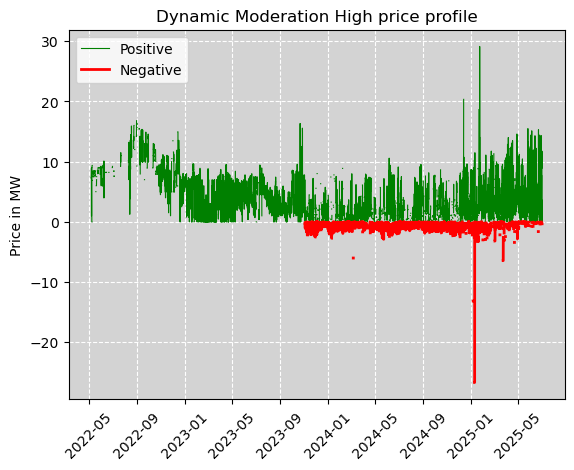

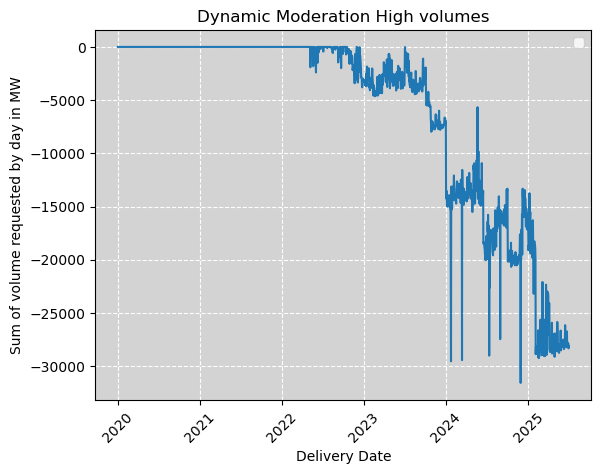

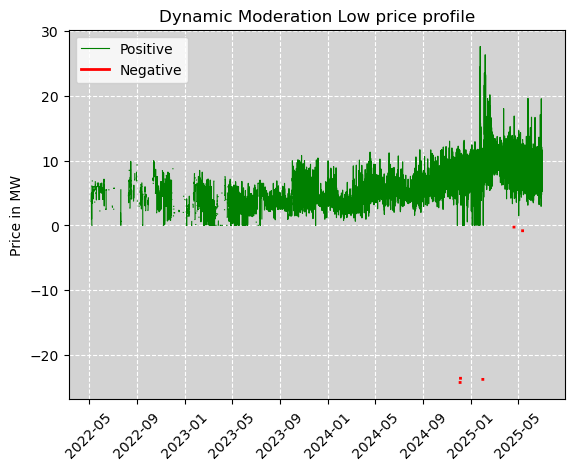

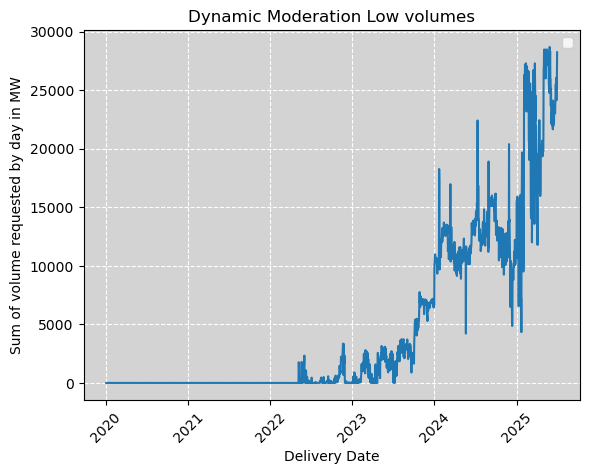

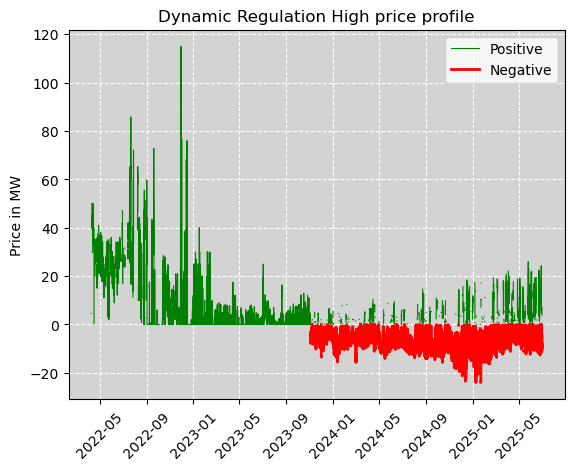

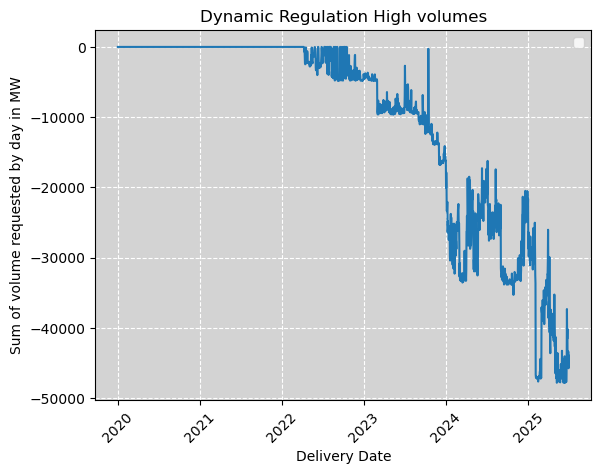

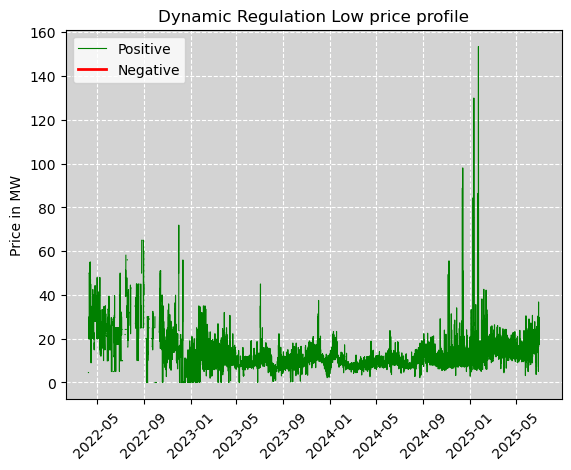

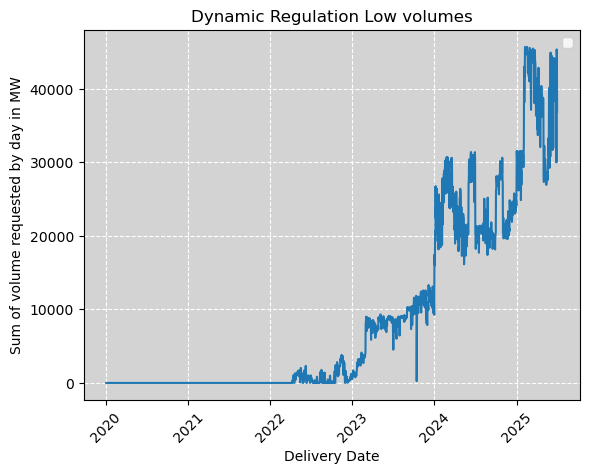

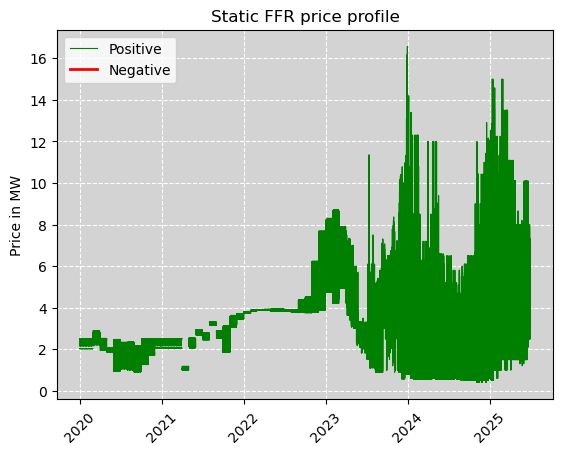

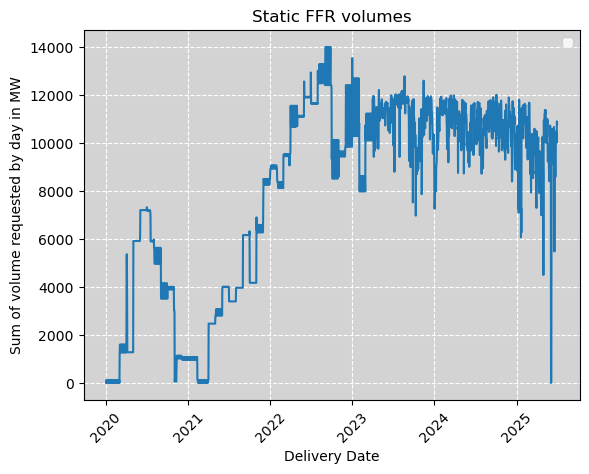

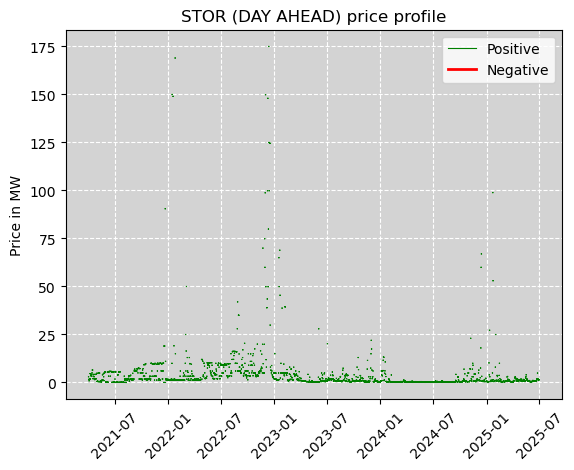

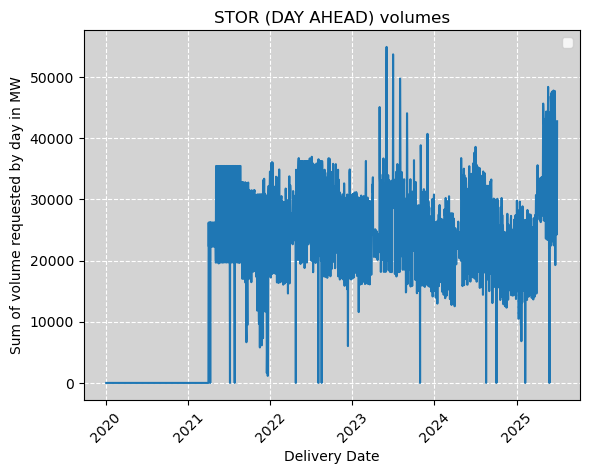

In [ ]:
for service in list(pricesENAPSYS.columns.get_level_values(0)):

    filter_service = pricesENAPSYS[service]
    values = filter_service['GBP/MW/h'].values
    days = filter_service.index  # assuming the index is datetime or categorical

    # Separate positive and negative
    pos = [v if v >= 0 else np.nan for v in values]
    neg = [v if v < 0 else np.nan for v in values]

    # Plot
    plt.plot(days, pos, label='Positive', color = 'green', linewidth=.8)
    plt.plot(days, neg, color='red', label='Negative', linewidth=2)
    
    plt.xticks(rotation=45) 
    
    plt.gca().set_facecolor('lightgrey')
    plt.grid(color='white', linestyle='--', linewidth=0.8)
    plt.gca().set_axisbelow(True) 
    plt.ylabel('Price in MW')
    plt.title(f'{service} price profile')
    plt.legend()
    plt.show()
    
    plt.plot(volumesENAPSYS[service].resample('D').sum())
    
    plt.xticks(rotation=45) 
    plt.gca().set_facecolor('lightgrey')
    plt.ylabel('Sum of volume requested by day in MW')
    plt.xlabel('Delivery Date')
    plt.grid(color='white', linestyle='--', linewidth=0.8)
    plt.gca().set_axisbelow(True) 
    plt.title(f'{service} volumes')
    plt.legend()
    plt.show()

## NESO graphes


### from 2021-09 to 2023-11 with tech

In [ ]:
pricesNESO_tech = pd.read_csv(path_dir / 'data/prices_and_volumes_NESO-ancillary-2021.csv', parse_dates= ['Delivery Start', 'Delivery End'])

# EFA stands for Electricity Forward Agreement (or Auction) periods.
# Its a way of dividing the trading day in UK electricity markets into six 4-hour blocks, which are used for trading, balancing, and sometimes for defining delivery windows in flexibility or ancillary services.

print(pricesNESO_tech['Delivery Start'].min(), pricesNESO_tech['Delivery End'].max())
pricesNESO_tech.loc[~(pricesNESO_tech['Technology Type'].isna() | (pricesNESO_tech['Technology Type'] == 'BM (SVA/VLP/Battery)')),'Technology Type'] = 'batteries'
pricesNESO_tech

2021-09-15 23:00:00 2023-11-02 23:00:00


,Company,Unit Name,EFA Date,Delivery Start,Delivery End,EFA,Service,Cleared Volume,Clearing Price,Technology Type,Location,Cancelled
0,ANCALA ENERGY STORAGE LIMITED,ANSC-001,2021-09-16,2021-09-15 23:00:00,2021-09-16 03:00:00,1,DCL,1,17.00,NaN,NaN,NaN
1,ANCALA ENERGY STORAGE LIMITED,ANSC-001,2021-09-16,2021-09-16 03:00:00,2021-09-16 07:00:00,2,DCL,1,17.00,NaN,NaN,NaN
2,ANCALA ENERGY STORAGE LIMITED,ANSC-001,2021-09-16,2021-09-16 07:00:00,2021-09-16 11:00:00,3,DCL,1,17.00,NaN,NaN,NaN
3,ANCALA ENERGY STORAGE LIMITED,ANSC-001,2021-09-16,2021-09-16 11:00:00,2021-09-16 15:00:00,4,DCL,1,17.00,NaN,NaN,NaN
4,ANCALA ENERGY STORAGE LIMITED,ANSC-001,2021-09-16,2021-09-16 15:00:00,2021-09-16 19:00:00,5,DCL,1,17.00,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
397657,ZENOBE ENERGY LIMITED,DBESSH-33,2023-11-02,2023-11-02 19:00:00,2023-11-02 23:00:00,6,DCL,7,1.50,batteries,BN44,NaN
397658,ZENOBE ENERGY LIMITED,ZEN02A,2023-11-02,2023-11-02 07:00:00,2023-11-02 11:00:00,3,DRL,16,10.60,batteries,CO10,NaN
397659,ZENOBE ENERGY LIMITED,ZEN02A,2023-11-02,2023-11-02 11:00:00,2023-11-02 15:00:00,4,DRL,17,10.77,batteries,CO10,NaN
397660,ZENOBE ENERGY LIMITED,ZEN02A,2023-11-02,2023-11-02 15:00:00,2023-11-02 19:00:00,5,DRL,14,11.50,batteries,CO10,NaN


#### graphes filtered by tech

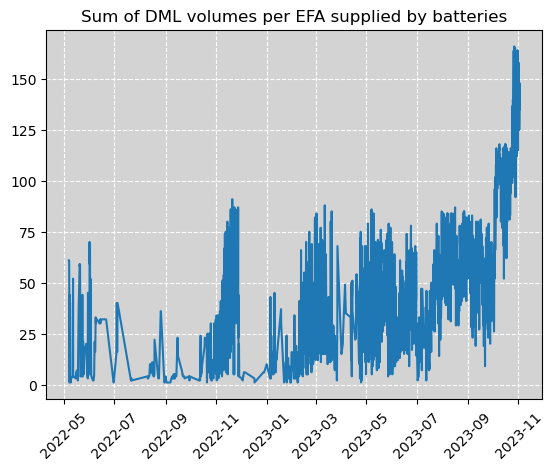

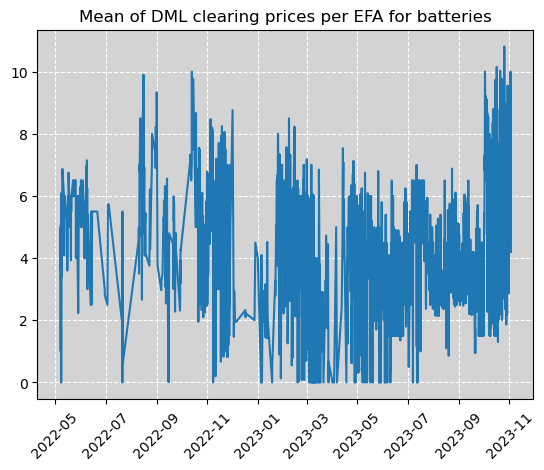

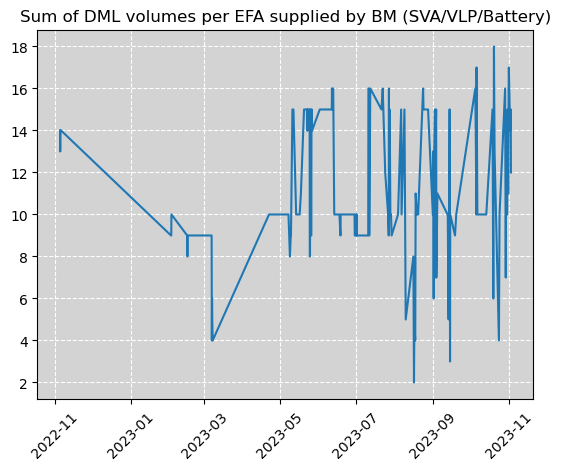

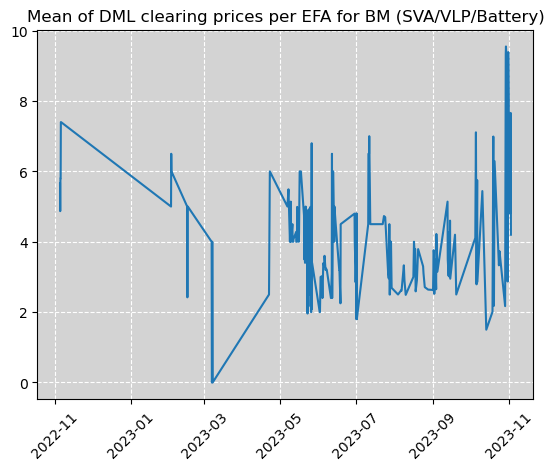

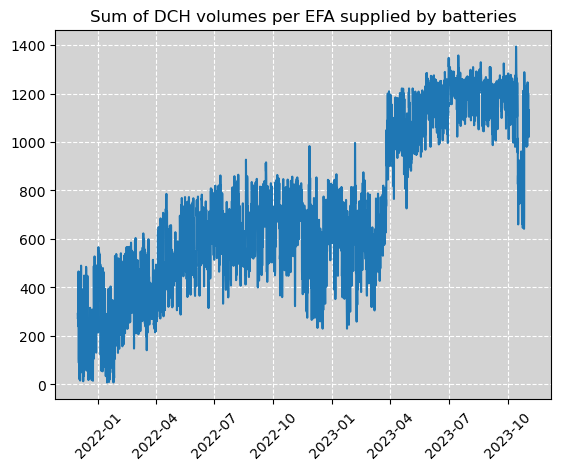

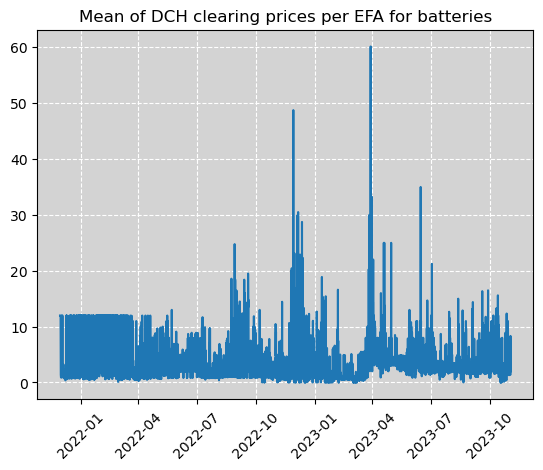

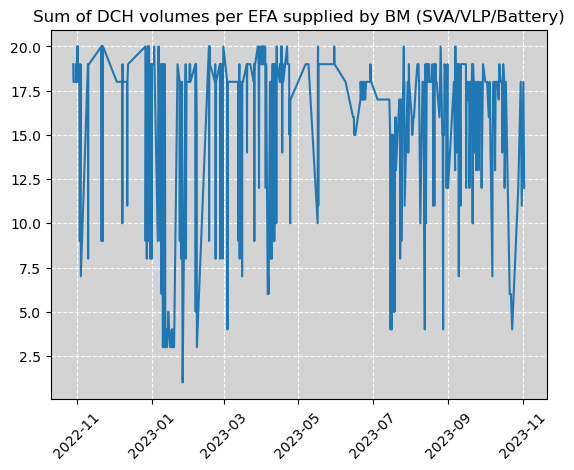

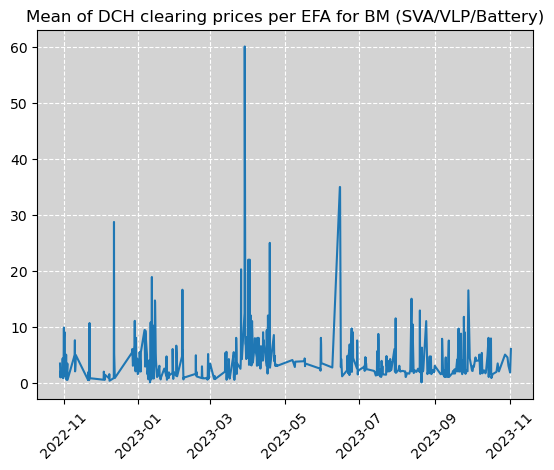

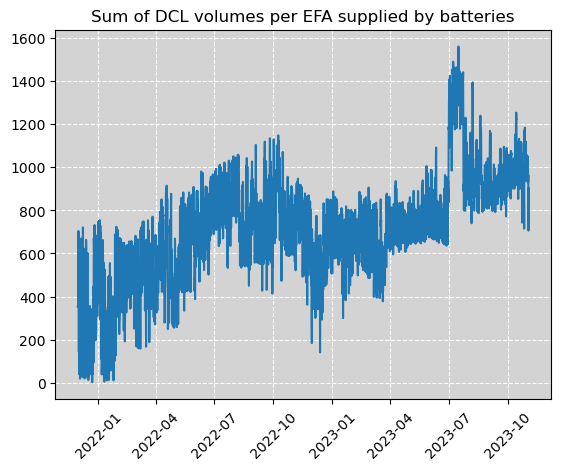

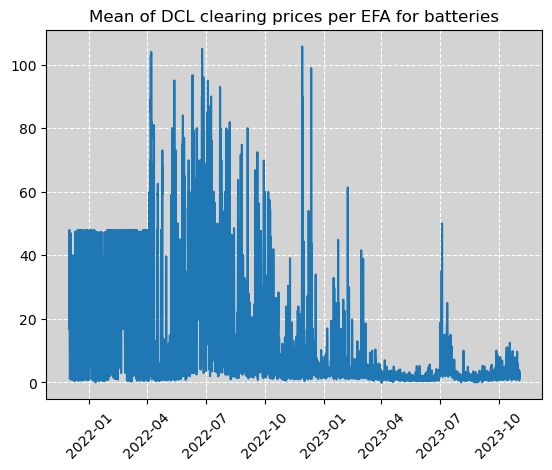

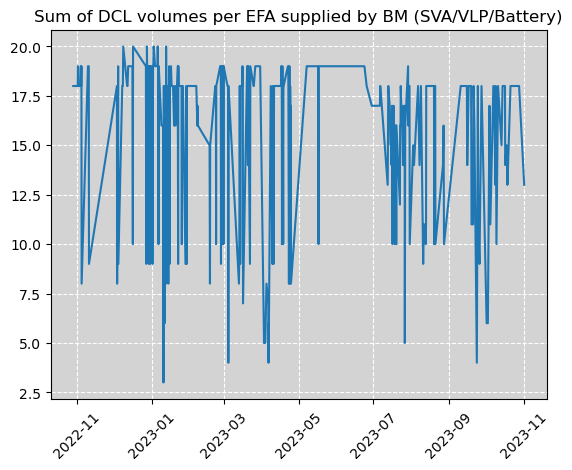

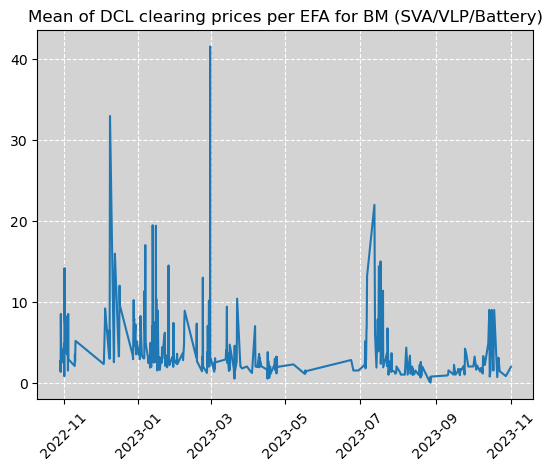

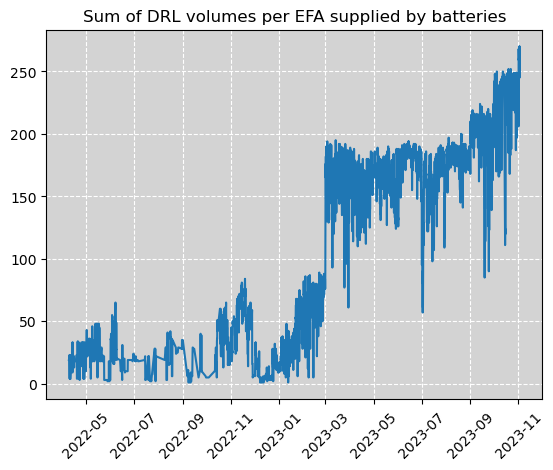

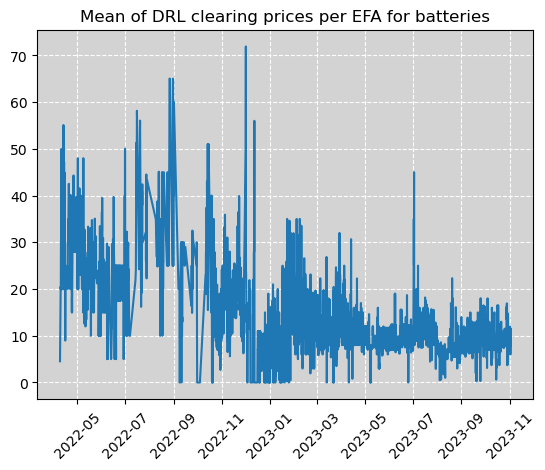

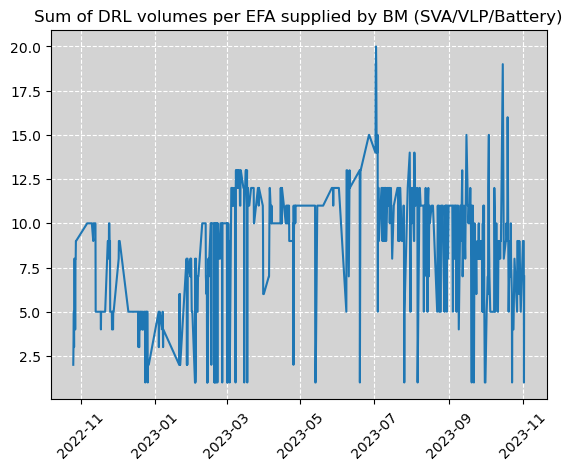

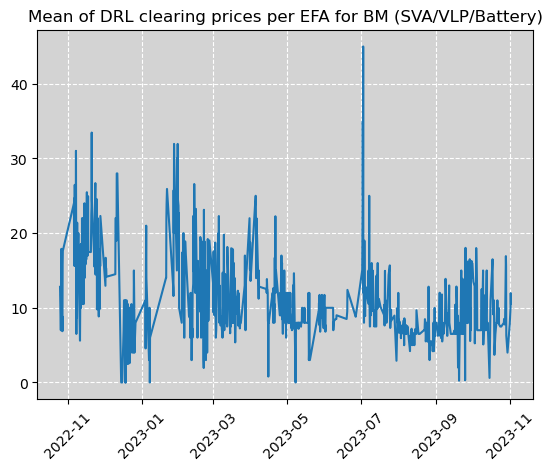

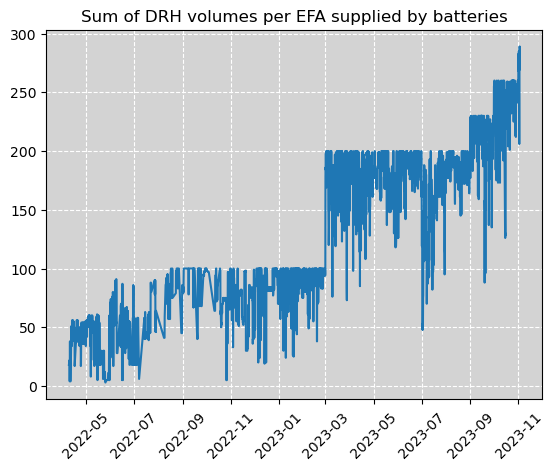

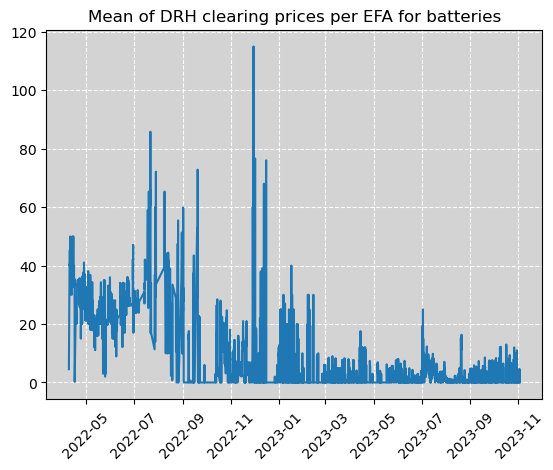

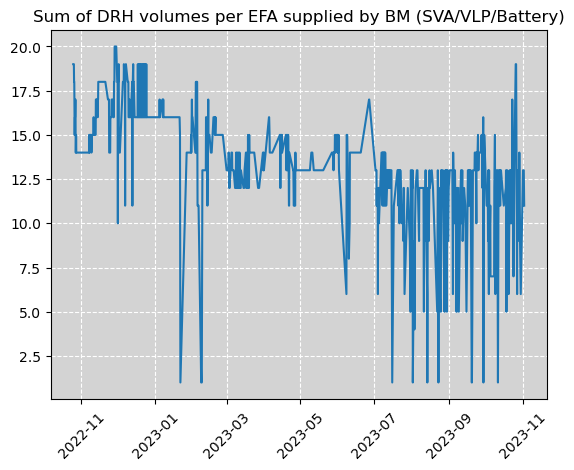

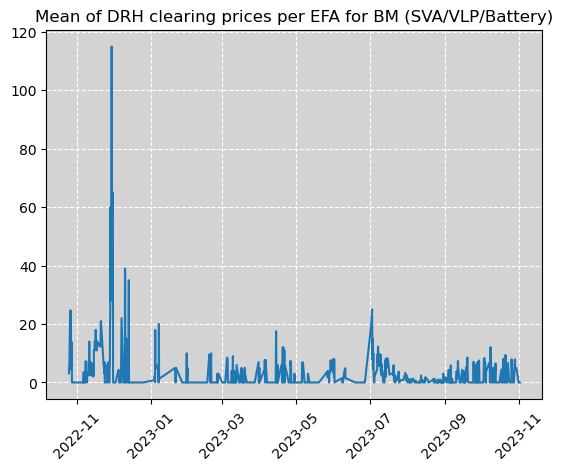

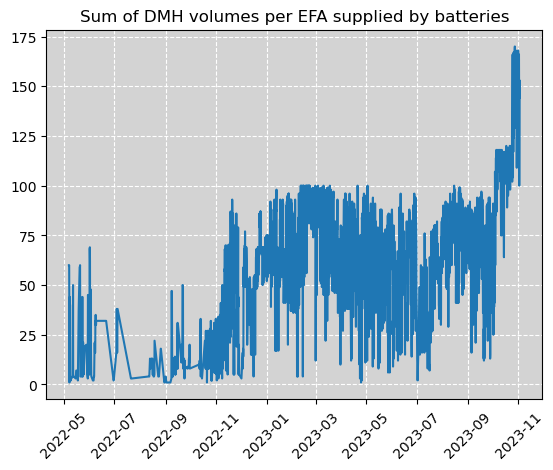

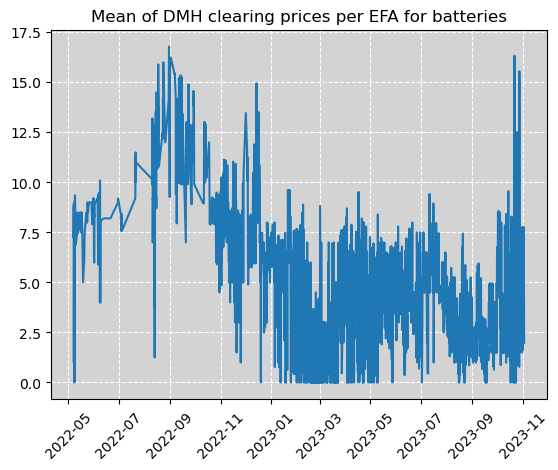

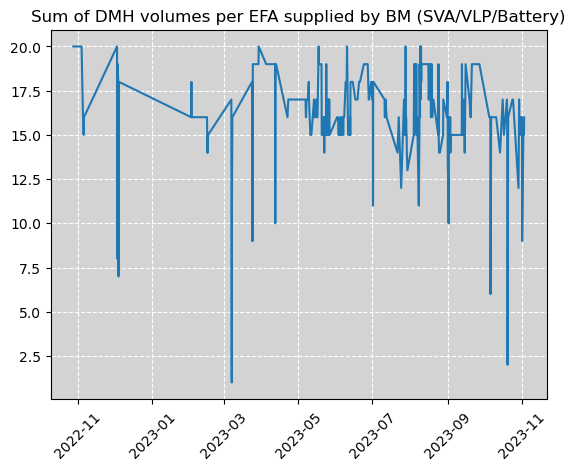

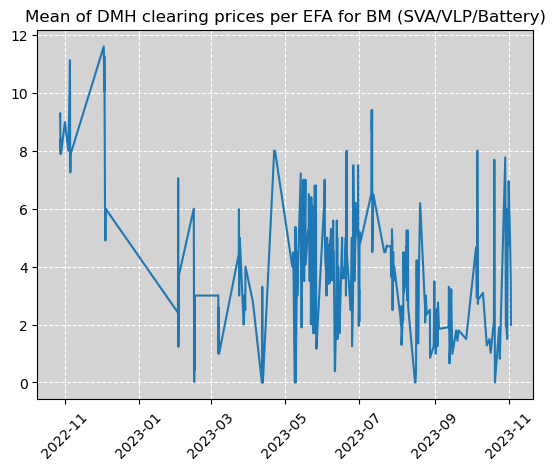

In [ ]:
for service in set(pricesNESO_tech['Service']):

    filter_service = pricesNESO_tech[pricesNESO_tech['Service'] == service]
    
    for tech in pricesNESO_tech['Technology Type'].unique():
        panel = filter_service[filter_service['Technology Type'] == tech]
        
        if panel.empty:
            continue
        # dates = pd.date_range(filter_service['Delivery Start'].min(), filter_service['Delivery End'].max(),freq='4H')
        # dates = dates[:-1]
        
        y = panel['Cleared Volume'].groupby(panel['Delivery Start']).sum()
        x = panel['Cleared Volume'].groupby(panel['Delivery Start']).sum().index

        plt.plot(x, y)
        plt.xticks(rotation=45) 
        plt.gca().set_facecolor('lightgrey')
        plt.grid(color='white', linestyle='--', linewidth=0.8)
        plt.gca().set_axisbelow(True) 
        plt.title(f'Sum of {service} volumes per EFA supplied by {tech}')
        plt.show()
        
        y =  panel['Clearing Price'].groupby(panel['Delivery Start']).mean()

        plt.plot(x,y)
        plt.title(f'Mean of {service} clearing prices per EFA for {tech}')
        plt.xticks(rotation=45) 
        plt.gca().set_facecolor('lightgrey')
        plt.grid(color='white', linestyle='--', linewidth=0.8)
        plt.gca().set_axisbelow(True) 
        plt.show()

#### bar graphes not filtered by tech

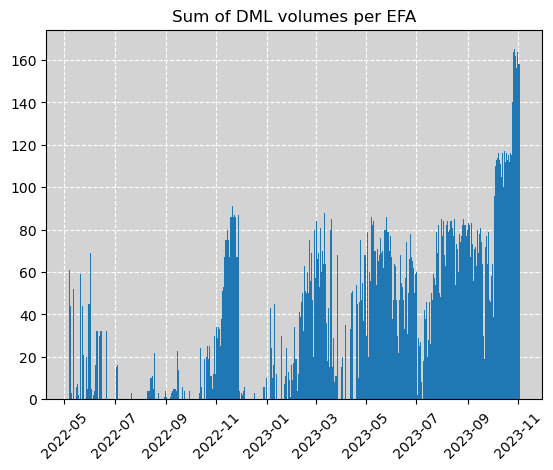

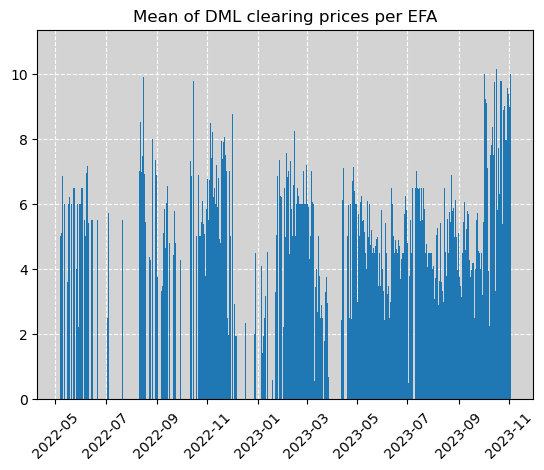

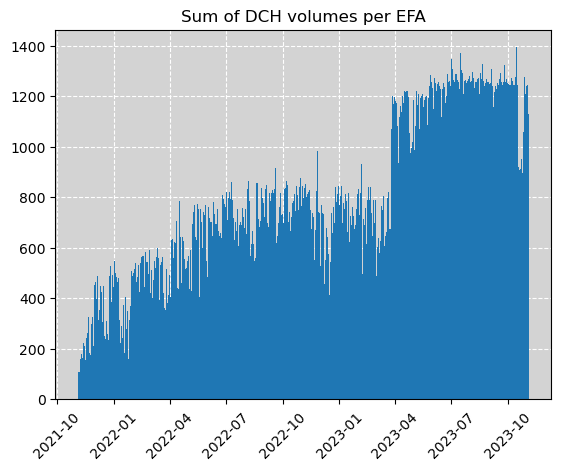

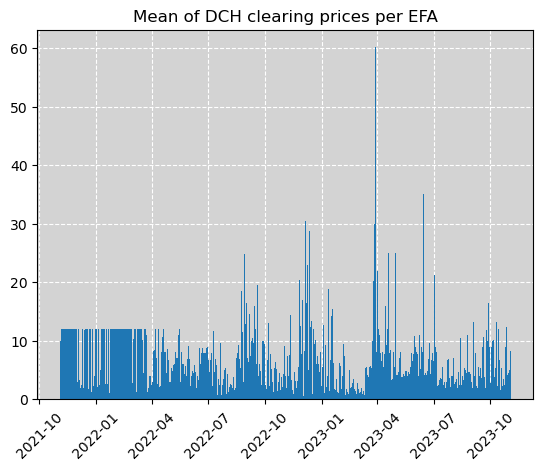

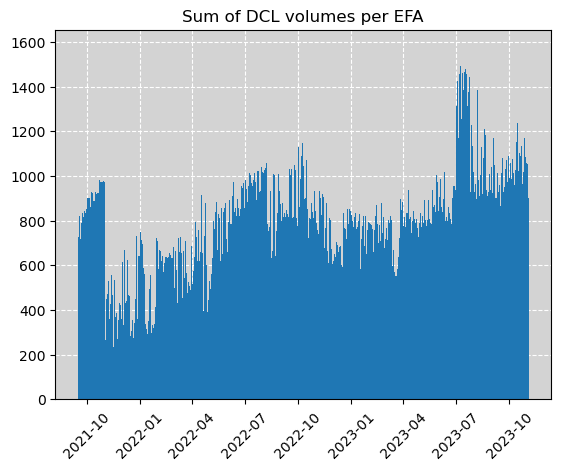

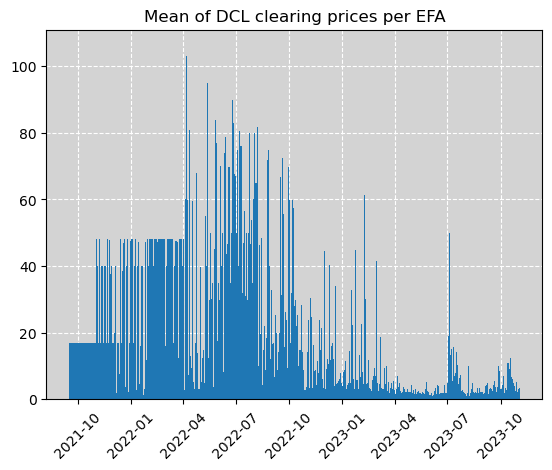

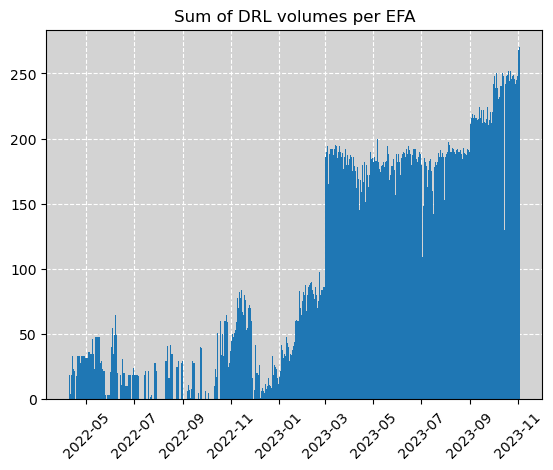

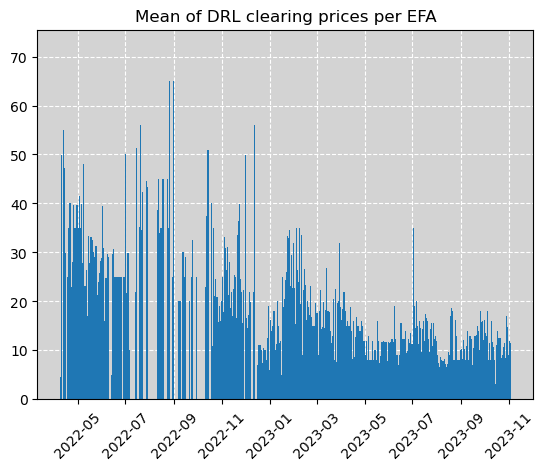

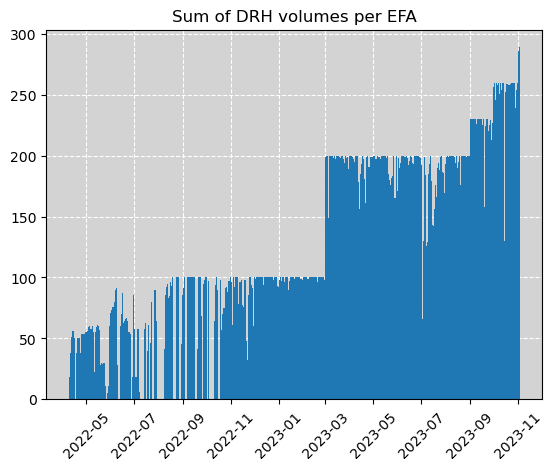

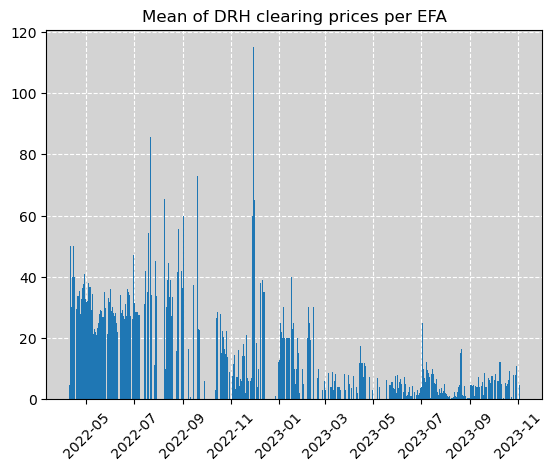

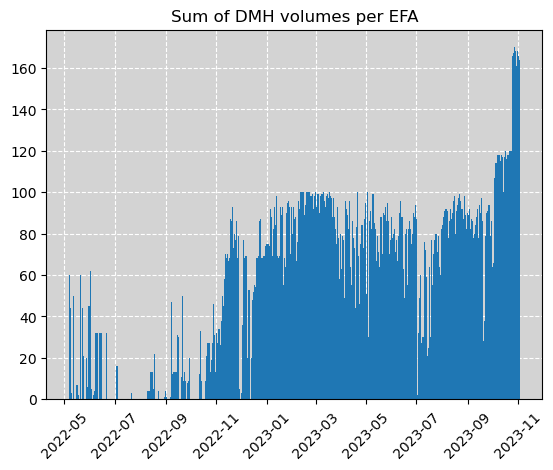

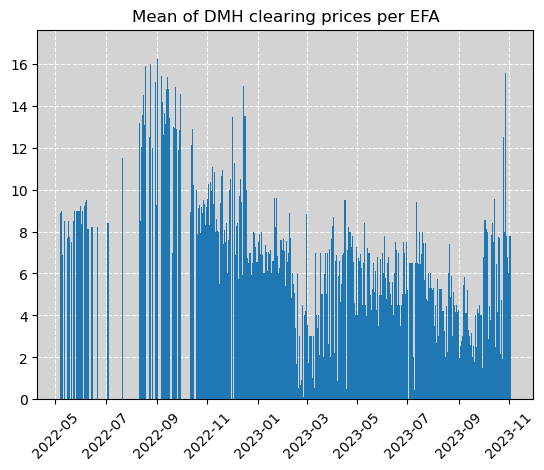

In [ ]:
for service in set(pricesNESO_tech['Service']):

    filter_service = pricesNESO_tech[pricesNESO_tech['Service'] == service]
    
    # dates = pd.date_range(filter_service['Delivery Start'].min(), filter_service['Delivery End'].max(),freq='4H')
    # dates = dates[:-1]
    
    y = filter_service['Cleared Volume'].groupby(filter_service['Delivery Start']).sum()
    x = filter_service['Cleared Volume'].groupby(filter_service['Delivery Start']).sum().index

    plt.bar(x, y)
    plt.xticks(rotation=45) 
    plt.gca().set_facecolor('lightgrey')
    plt.grid(color='white', linestyle='--', linewidth=0.8)
    plt.gca().set_axisbelow(True) 
    plt.title(f'Sum of {service} volumes per EFA')
    plt.show()
    
    y =  filter_service['Clearing Price'].groupby(filter_service['Delivery Start']).mean()

    plt.bar(x,y)
    plt.title(f'Mean of {service} clearing prices per EFA')
    plt.xticks(rotation=45) 
    plt.gca().set_facecolor('lightgrey')
    plt.grid(color='white', linestyle='--', linewidth=0.8)
    plt.gca().set_axisbelow(True) 
    plt.show()


In [ ]:
# dates = pd.date_range(pricesNESO['Delivery Start'].min(), pricesNESO['Delivery End'].max(),freq='4H')

# plt.plot(pricesNESO['Cleared Volume'].groupby(pricesNESO['Delivery Start'].dt.date).sum())
# plt.xticks(rotation=45) 
# plt.show()

# plt.plot(pricesNESO['Clearing Price'].groupby(pricesNESO['Delivery Start'].dt.date).mean())
# plt.xticks(rotation=45) 
# plt.show()

### from 2023-11 to 2025-07 (but no STOR or FFR)

In [ ]:
pricesNESO1 = pd.read_csv(path_dir / 'data/prices_and_volumes_NESO-ancillary-2023.csv', parse_dates= ['deliveryStart', 'deliveryEnd'])

# EFA stands for Electricity Forward Agreement (or Auction) periods.
# Its a way of dividing the trading day in UK electricity markets into six 4-hour blocks, which are used for trading, balancing, and sometimes for defining delivery windows in flexibility or ancillary services.

print(pricesNESO1['deliveryStart'].min(), pricesNESO1['deliveryEnd'].max())
print(pricesNESO1['auctionProduct'].unique())

pricesNESO1 = pricesNESO1[pricesNESO1['auctionProduct'].isin(['DRH', 'DML', 'DCH', 'DRL', 'DCL', 'DMH'])]
pricesNESO1

2023-11-02 23:00:00 2025-07-23 22:00:00
['DRH' 'DML' 'DCH' 'DRL' 'DCL' 'DMH' 'NQR' 'PQR']


,auctionID,auctionProduct,serviceType,deliveryStart,deliveryEnd,clearedVolume,clearingPrice,linkedServiceWindowID
0,1,DRH,Response,2023-11-02 23:00:00,2023-11-03 03:00:00,175.0,2.75,NaN
1,1,DRH,Response,2023-11-03 03:00:00,2023-11-03 07:00:00,239.0,4.04,NaN
2,1,DRH,Response,2023-11-03 07:00:00,2023-11-03 11:00:00,290.0,-3.30,NaN
3,1,DRH,Response,2023-11-03 11:00:00,2023-11-03 15:00:00,290.0,-3.53,NaN
4,1,DRH,Response,2023-11-03 15:00:00,2023-11-03 19:00:00,290.0,-5.81,NaN
...,...,...,...,...,...,...,...,...
44907,1448,DMH,Response,2025-07-23 02:00:00,2025-07-23 06:00:00,300.0,1.32,NaN
44908,1448,DMH,Response,2025-07-23 06:00:00,2025-07-23 10:00:00,320.0,-0.21,NaN
44909,1448,DMH,Response,2025-07-23 10:00:00,2025-07-23 14:00:00,300.0,2.70,NaN
44910,1448,DMH,Response,2025-07-23 14:00:00,2025-07-23 18:00:00,300.0,2.05,NaN


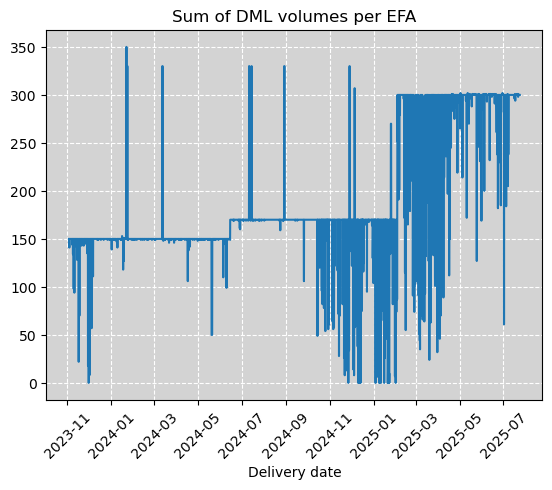

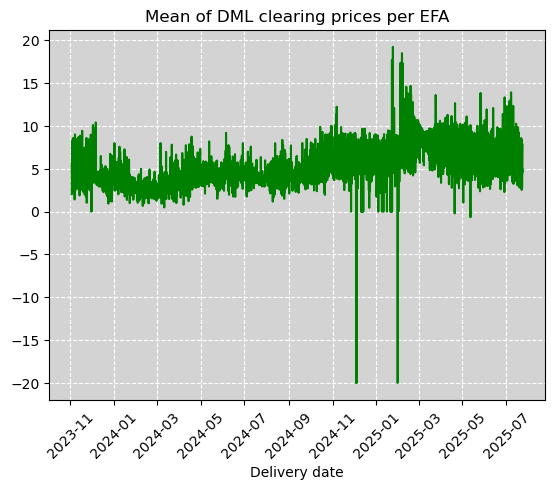

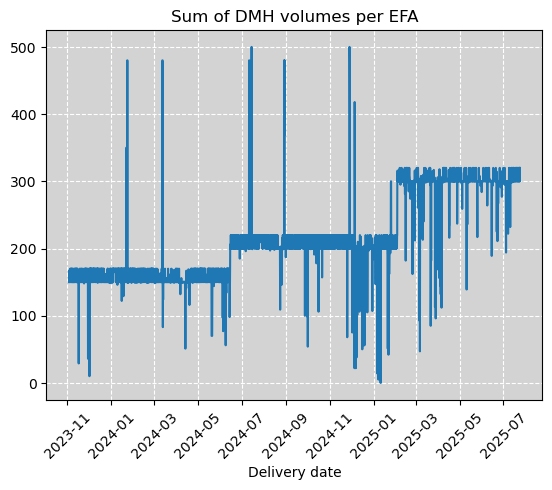

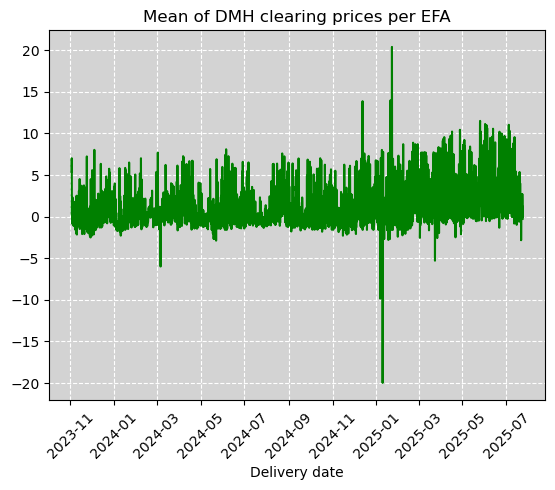

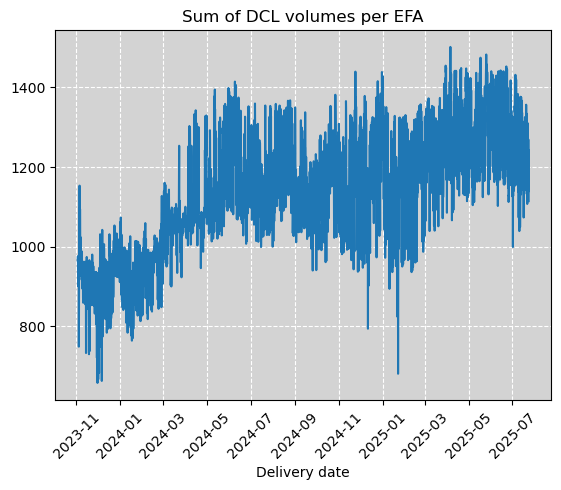

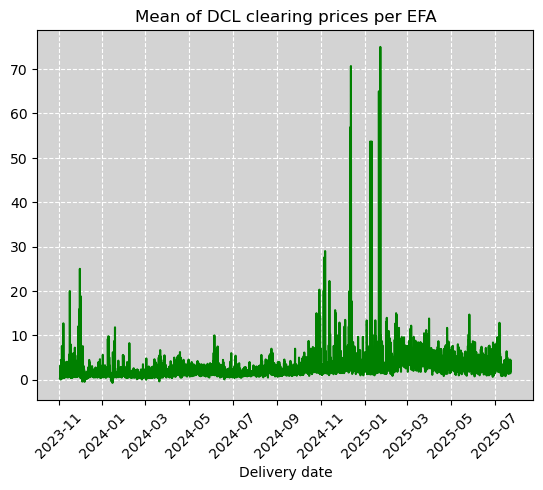

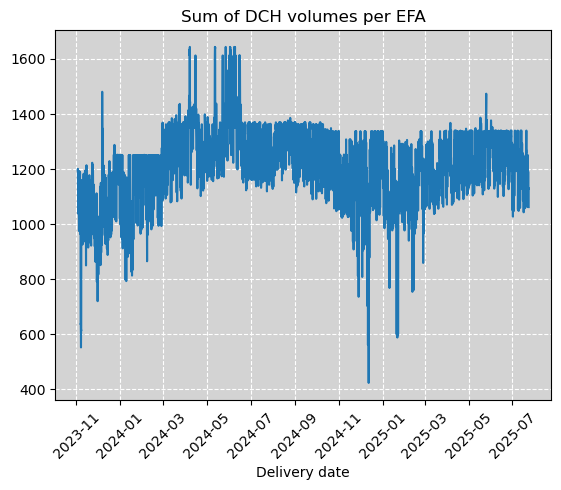

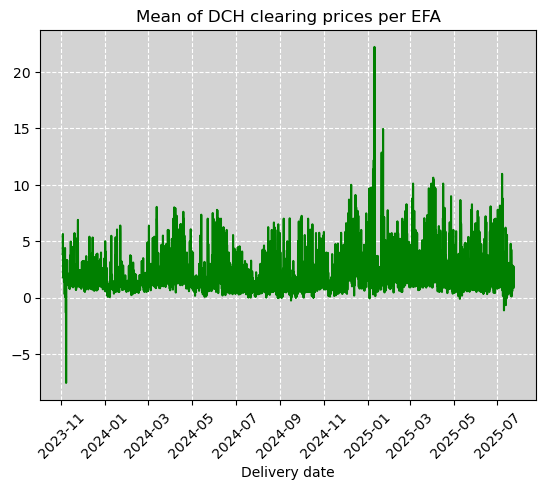

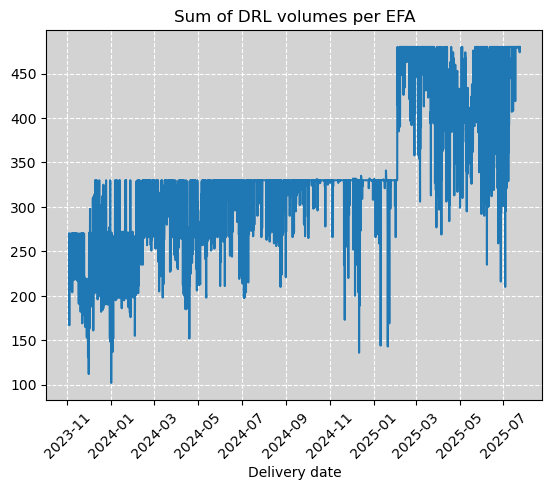

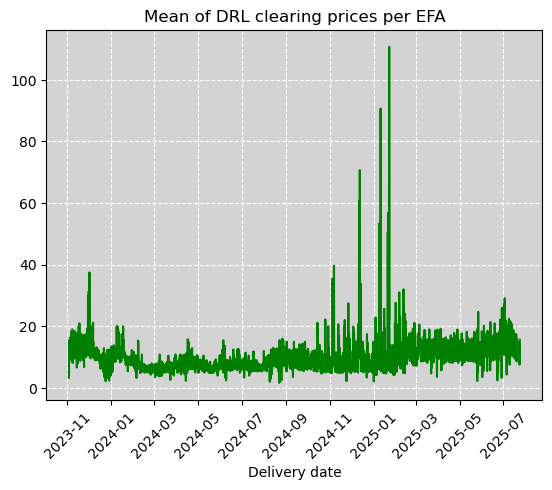

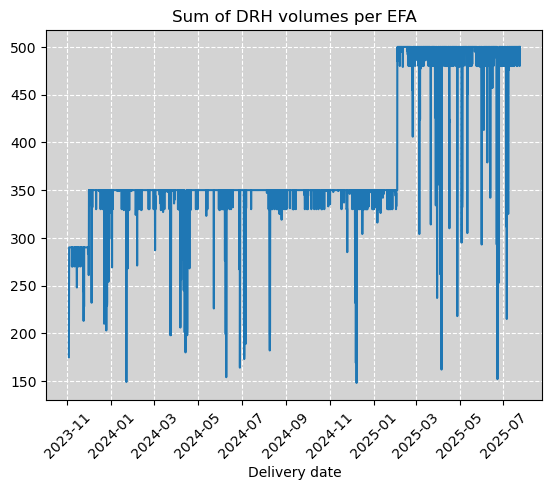

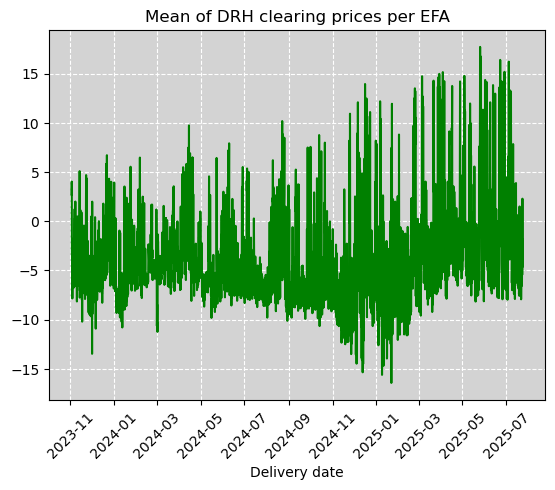

In [ ]:

for service in set(pricesNESO1['auctionProduct']):

    filter_service = pricesNESO1[pricesNESO1['auctionProduct'] == service]
    
    # dates = pd.date_range(filter_service['Delivery Start'].min(), filter_service['Delivery End'].max(),freq='4H')
    # dates = dates[:-1]
    
    y = filter_service['clearedVolume'].groupby(filter_service['deliveryStart']).sum()
    x = filter_service['clearedVolume'].groupby(filter_service['deliveryStart']).sum().index

    plt.plot(x, y)
    plt.xticks(rotation=45) 
    plt.gca().set_facecolor('lightgrey')
    plt.grid(color='white', linestyle='--', linewidth=0.8)
    plt.gca().set_axisbelow(True)
    plt.xlabel('Delivery date')
    plt.title(f'Sum of {service} volumes per EFA')
    plt.show()
    
    y =  filter_service['clearingPrice'].groupby(filter_service['deliveryStart']).mean()

    plt.plot(x,y, color='green')
    plt.title(f'Mean of {service} clearing prices per EFA')
    plt.xticks(rotation=45) 
    plt.xlabel('Delivery date')
    plt.gca().set_facecolor('lightgrey')
    plt.grid(color='white', linestyle='--', linewidth=0.8)
    plt.gca().set_axisbelow(True) 
    plt.show()


### from 2023-11 to 2025-07 (has tech~)

In [66]:
path_dir

WindowsPath('c:/Users/Duval1e/GitHub_local/masten')

In [67]:
NESO_ancillary = pd.read_csv(path_dir / 'data/prices_and_volumes_NESO-ancillary-past.csv', parse_dates= ['deliveryStart', 'deliveryEnd'])

# EFA stands for Electricity Forward Agreement (or Auction) periods.
# Its a way of dividing the trading day in UK electricity markets into six 4-hour blocks, which are used for trading, balancing, and sometimes for defining delivery windows in flexibility or ancillary services.

NESO_ancillary = NESO_ancillary[NESO_ancillary['auctionProduct'].isin(['DRH', 'DML', 'DCH', 'DRL', 'DCL', 'DMH'])]
NESO_ancillary

,registeredAuctionParticipant,auctionUnit,serviceType,auctionProduct,executedQuantity,clearingPrice,deliveryStart,deliveryEnd,technologyType,postCode,unitResultID
0,ARENKO CLEANTECH LIMITED,PNYCB-1,Response,DCH,3.0,5.64,2023-11-03 03:00:00,2023-11-03 07:00:00,NaN,NaN,1#||#137#||#DCH#||#14
1,VEST ENERGY LIMITED,VEST-1,Response,DRL,0.0,12.81,2023-11-03 19:00:00,2023-11-03 23:00:00,NaN,NaN,1#||#23#||#DRL#||#24
2,SMS ENERGY SERVICES LIMITED,BROFB-1,Response,DCH,0.0,1.78,2023-11-03 07:00:00,2023-11-03 11:00:00,NaN,NaN,1#||#112#||#DCH#||#15
3,STATKRAFT MARKETS GMBH,AG-JSTK02,Response,DCH,4.0,3.86,2023-11-02 23:00:00,2023-11-03 03:00:00,NaN,NaN,1#||#16#||#DCH#||#13
4,TESLA MOTORS LIMITED,PILLB-1,Response,DCH,49.0,1.96,2023-11-03 15:00:00,2023-11-03 19:00:00,NaN,NaN,1#||#68#||#DCH#||#17
...,...,...,...,...,...,...,...,...,...,...,...
1036328,EDF ENERGY CUSTOMERS LIMITED,WBURB-41,Response,DCL,19.0,2.00,2025-07-23 10:00:00,2025-07-23 14:00:00,CCGT,NaN,1448#||#201#||#DCL#||#92884
1036330,FLEXITRICITY LIMITED,AG-PFLX01,Response,DCL,44.0,2.51,2025-07-23 06:00:00,2025-07-23 10:00:00,Batteries,DD2 5JW,1448#||#107#||#DCL#||#92883
1036331,LIMEJUMP ENERGY LIMITED,AG-HLIM01,Response,DCH,18.0,0.97,2025-07-22 22:00:00,2025-07-23 02:00:00,Batteries,PO14 2HS,1448#||#8#||#DCH#||#92869
1036332,Arenko Cleantech Limited,CRSSB-1,Response,DCH,7.0,0.94,2025-07-23 06:00:00,2025-07-23 10:00:00,Batteries,L13 7HY,1448#||#1524#||#DCH#||#92871


#### Correlations


In [ ]:
for market in ['DRH', 'DML', 'DCH', 'DRL', 'DCL', 'DMH']:
    for corr, pval in zip(['pearson', 'spearman', 'kendall'], [pearsonr, spearmanr, kendalltau]):
    
        panel = NESO_ancillary[(NESO_ancillary['auctionProduct'] == market)]
        
        coef, pval = pval(panel['clearingPrice'], panel['executedQuantity'])
        
        print(f"For {market}, {round(coef,3)} for {corr}")


For DRH, 0.017 for pearson
For DRH, 0.003 for spearman
For DRH, 0.002 for kendall
For DML, 0.087 for pearson
For DML, 0.053 for spearman
For DML, 0.036 for kendall
For DCH, -0.036 for pearson
For DCH, -0.062 for spearman
For DCH, -0.042 for kendall
For DRL, -0.04 for pearson
For DRL, -0.059 for spearman
For DRL, -0.04 for kendall
For DCL, -0.008 for pearson
For DCL, -0.0 for spearman
For DCL, -0.0 for kendall
For DMH, -0.001 for pearson
For DMH, 0.002 for spearman
For DMH, 0.001 for kendall


In [ ]:
NESO_ancillary["Year"] = NESO_ancillary['deliveryStart'].dt.year

for service in set(NESO_ancillary['auctionProduct']):
    
    filter_service = NESO_ancillary[NESO_ancillary['auctionProduct'] == service]
    
    # mean per row grouped by season, year, technology
    stack_data = (
        filter_service
        .groupby(['season','Year','technologyType'])['executedQuantity']
        .sum()
        .reset_index()
    )

array([nan, 'Batteries', 'BM (SVA/VLP/Battery)', 'Other', 'CCGT'],
      dtype=object)

#### graphes

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_16892\2916160661.py:30: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(index=['season','Year'], columns='technologyType',


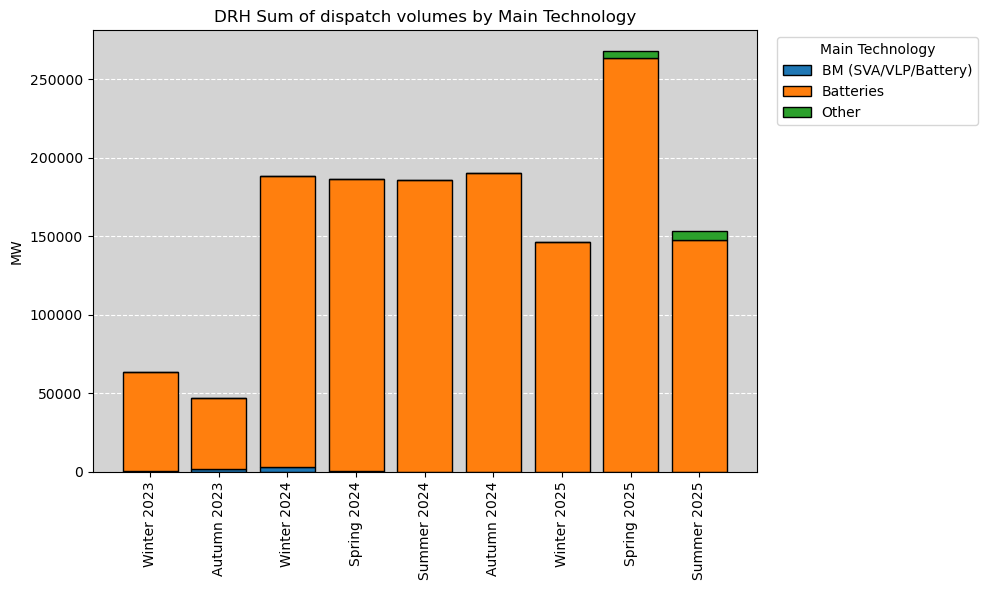

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_16892\2916160661.py:30: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(index=['season','Year'], columns='technologyType',


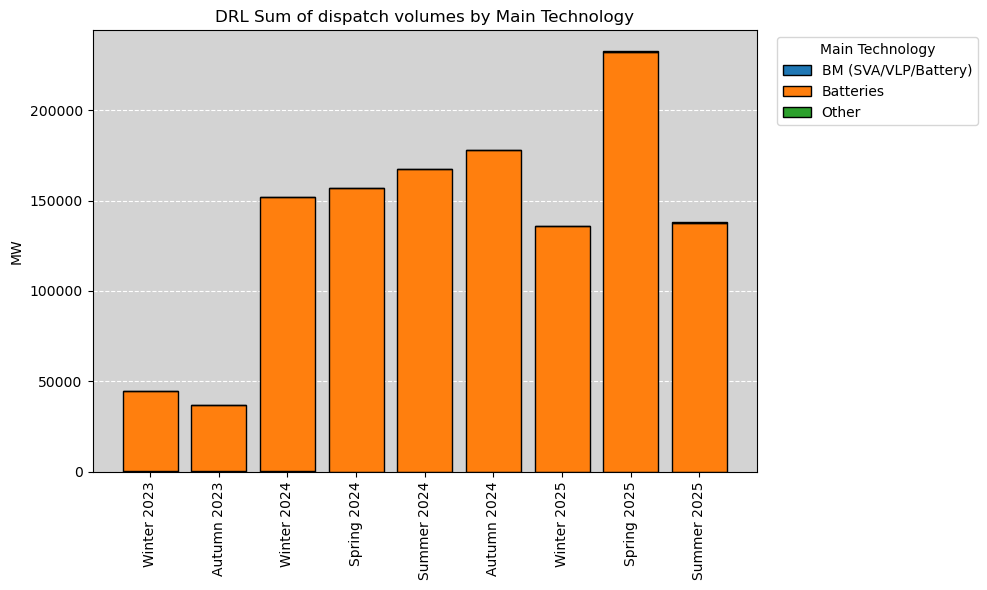

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_16892\2916160661.py:30: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(index=['season','Year'], columns='technologyType',


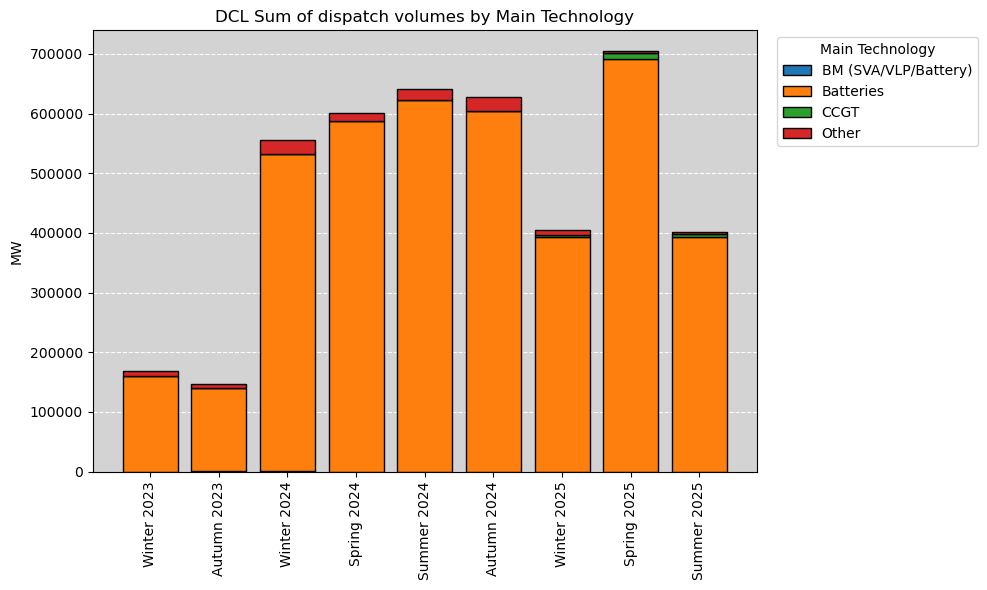

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_16892\2916160661.py:30: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(index=['season','Year'], columns='technologyType',


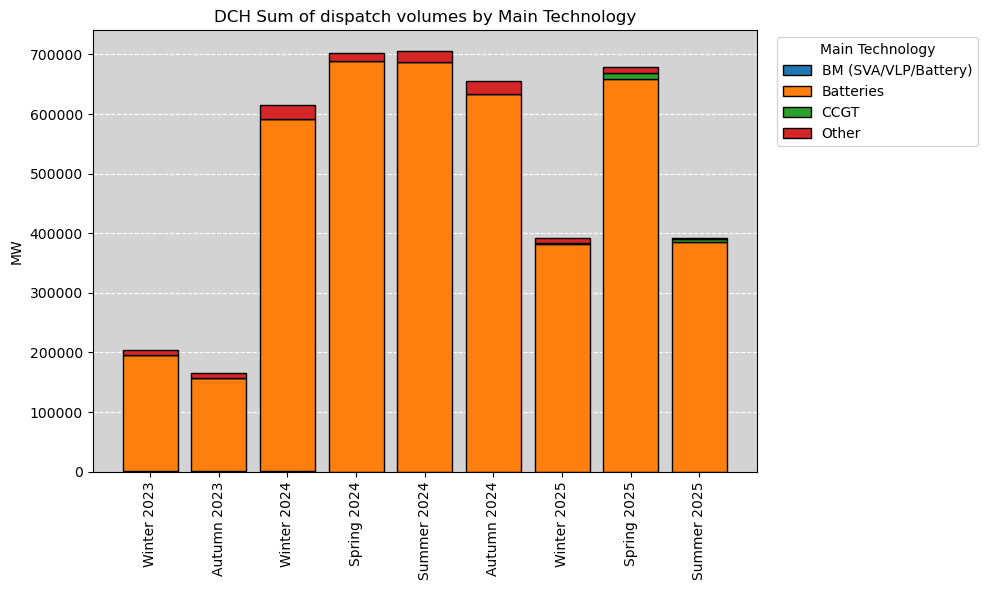

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_16892\2916160661.py:30: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(index=['season','Year'], columns='technologyType',


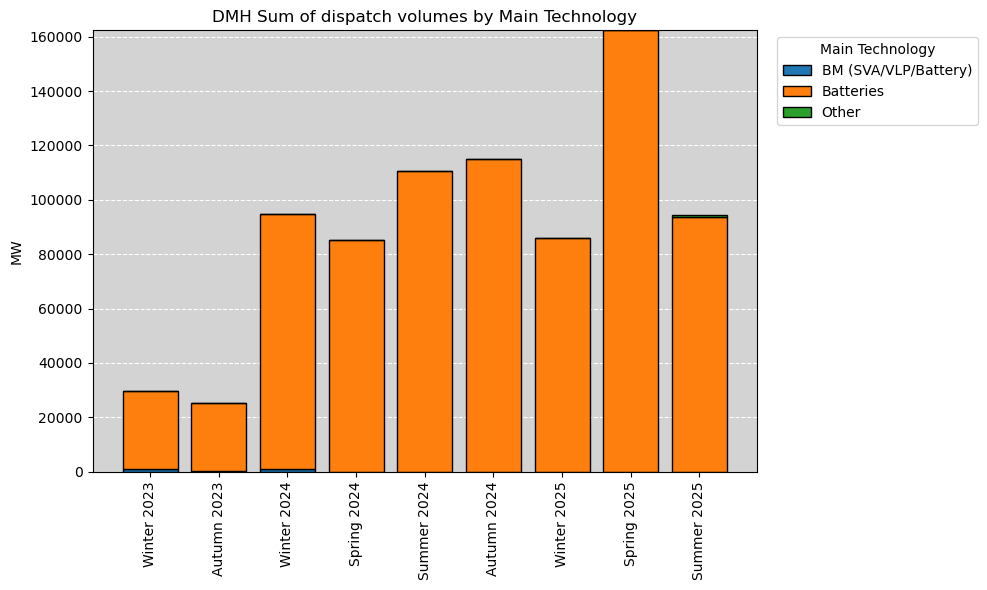

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_16892\2916160661.py:30: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(index=['season','Year'], columns='technologyType',


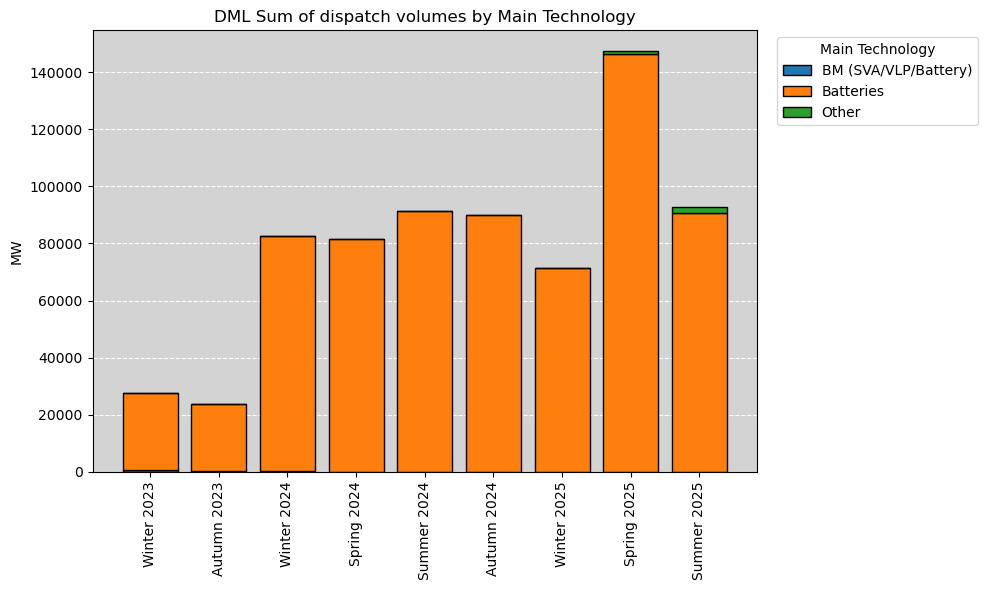

In [ ]:
NESO_ancillary["season"] = np.where(
    NESO_ancillary['deliveryStart'].dt.month.isin([12, 1, 2]), "Winter",
    np.where(NESO_ancillary['deliveryStart'].dt.month.isin([3,4,5]), "Spring",
             np.where(NESO_ancillary['deliveryStart'].dt.month.isin([6,7,8]), "Summer",
                      "Autumn"))
)

NESO_ancillary["Year"] = NESO_ancillary['deliveryStart'].dt.year


for service in set(NESO_ancillary['auctionProduct']):
    
    filter_service = NESO_ancillary[NESO_ancillary['auctionProduct'] == service]
    
    # mean per row grouped by season, year, technology
    stack_data = (
        filter_service
        .groupby(['season','Year','technologyType'])['executedQuantity']
        .sum()
        .reset_index()
    )

    # pivot so each technology is a column
    season_order = ["Winter", "Spring", "Summer", "Autumn"]
    stack_data['season'] = pd.Categorical(stack_data['season'], season_order, ordered=True)

    stack_pivot = (
        stack_data
        .sort_values(['Year','season'])
        .pivot_table(index=['season','Year'], columns='technologyType',
                    values='executedQuantity', fill_value=0).sort_index(level=['Year','season'], sort_remaining=False)
    )

    # labels like "Winter 2024"
    x_labels = [f"{s} {y}" for s, y in stack_pivot.index.to_list()]

    # median line per bar (row-based)
    # medians = (
    #     dispatches
    #       .groupby(['season','Year'])['Dispatch Volume (MWh)']
    #       .median()
    #       .reindex(stack_pivot.index)
    #       .to_numpy()
    # )

    # --- plotting ---
    fig, ax = plt.subplots(figsize=(10,6))
    bottom = np.zeros(len(stack_pivot))

    for tech in stack_pivot.columns:
        heights = stack_pivot[tech].to_numpy()
        ax.bar(x_labels, heights, bottom=bottom, edgecolor='black', label=tech)
        bottom += heights

    # add median dashed line on each bar
    # for i, m in enumerate(medians):
    #     ax.plot([i-0.4, i+0.4], [m, m], linestyle='--', color='red', linewidth=1)

    ax.set_facecolor('lightgrey')
    ax.grid(axis='y', color='white', linestyle='--', linewidth=0.8)
    ax.set_axisbelow(True)
    plt.xticks(rotation=90)
    plt.ylabel("MW")
    plt.title(f"{service} Sum of dispatch volumes by Main Technology")
    ax.legend(title="Main Technology", bbox_to_anchor=(1.02,1), loc='upper left')
    plt.tight_layout()
    plt.show()

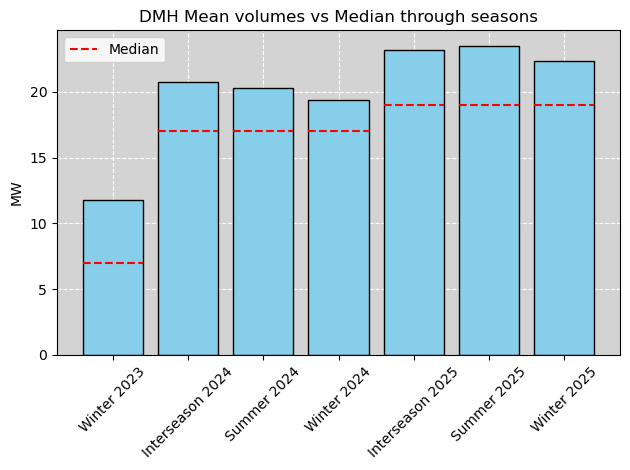

        season  Year       mean  median  min   max             label
4       Winter  2023  11.754475     7.0  0.0  49.0       Winter 2023
0  Interseason  2024  20.753470    17.0  1.0  89.0  Interseason 2024
2       Summer  2024  20.331043    17.0  1.0  50.0       Summer 2024
5       Winter  2024  19.384649    17.0  1.0  74.0       Winter 2024
1  Interseason  2025  23.203784    19.0  1.0  50.0  Interseason 2025
3       Summer  2025  23.508958    19.0  1.0  50.0       Summer 2025
6       Winter  2025  22.370419    19.0  1.0  48.0       Winter 2025


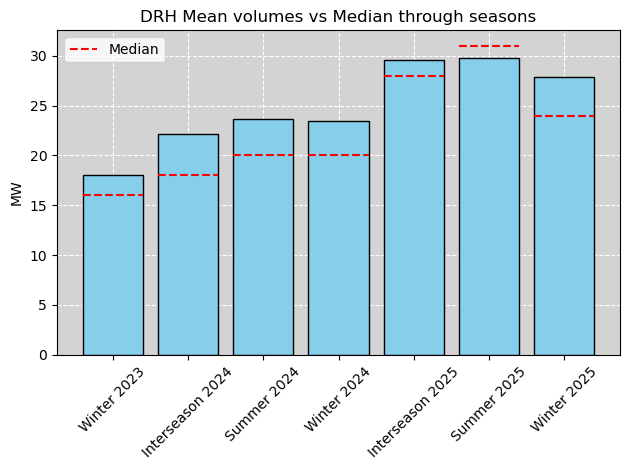

        season  Year       mean  median  min   max             label
4       Winter  2023  18.031094    16.0  0.0  50.0       Winter 2023
0  Interseason  2024  22.192599    18.0  1.0  81.0  Interseason 2024
2       Summer  2024  23.644750    20.0  1.0  50.0       Summer 2024
5       Winter  2024  23.424827    20.0  1.0  83.0       Winter 2024
1  Interseason  2025  29.553813    28.0  1.0  99.0  Interseason 2025
3       Summer  2025  29.764713    31.0  1.0  99.0       Summer 2025
6       Winter  2025  27.893893    24.0  1.0  99.0       Winter 2025


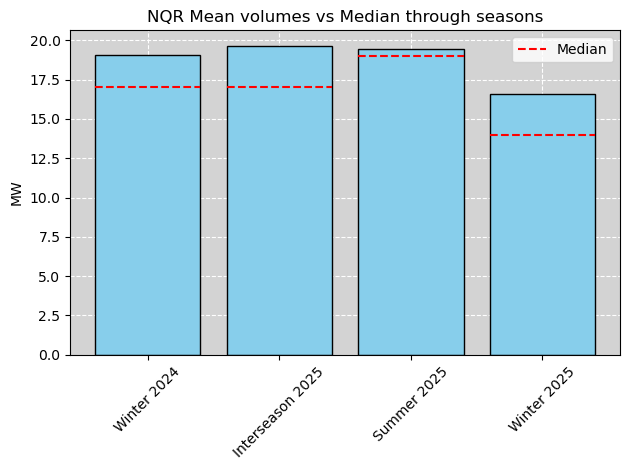

        season  Year       mean  median  min   max             label
2       Winter  2024  19.078272    17.0  1.0  91.0       Winter 2024
0  Interseason  2025  19.646576    17.0  1.0  84.0  Interseason 2025
1       Summer  2025  19.472396    19.0  1.0  89.0       Summer 2025
3       Winter  2025  16.558780    14.0  1.0  94.0       Winter 2025


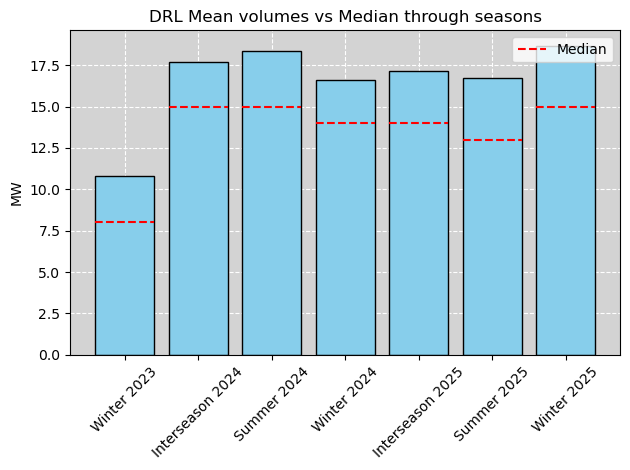

        season  Year       mean  median  min   max             label
4       Winter  2023  10.781550     8.0  0.0  50.0       Winter 2023
0  Interseason  2024  17.679481    15.0  1.0  50.0  Interseason 2024
2       Summer  2024  18.379347    15.0  1.0  50.0       Summer 2024
5       Winter  2024  16.614868    14.0  1.0  50.0       Winter 2024
1  Interseason  2025  17.178548    14.0  1.0  89.0  Interseason 2025
3       Summer  2025  16.702207    13.0  1.0  89.0       Summer 2025
6       Winter  2025  18.672354    15.0  1.0  50.0       Winter 2025


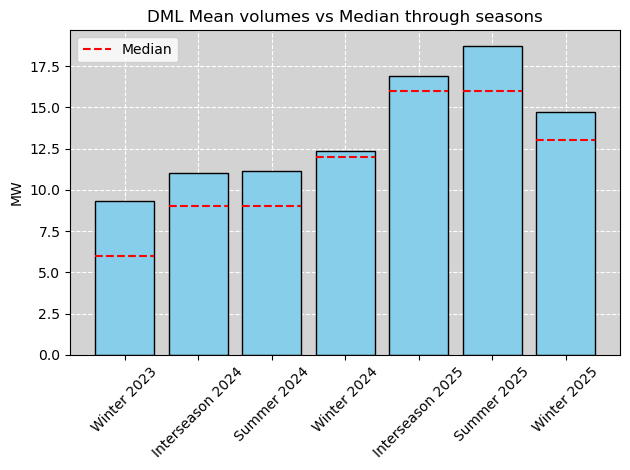

        season  Year       mean  median  min   max             label
4       Winter  2023   9.345699     6.0  0.0  49.0       Winter 2023
0  Interseason  2024  11.029941     9.0  1.0  86.0  Interseason 2024
2       Summer  2024  11.146150     9.0  1.0  50.0       Summer 2024
5       Winter  2024  12.374861    12.0  1.0  49.0       Winter 2024
1  Interseason  2025  16.918132    16.0  1.0  85.0  Interseason 2025
3       Summer  2025  18.735602    16.0  1.0  89.0       Summer 2025
6       Winter  2025  14.713932    13.0  1.0  50.0       Winter 2025


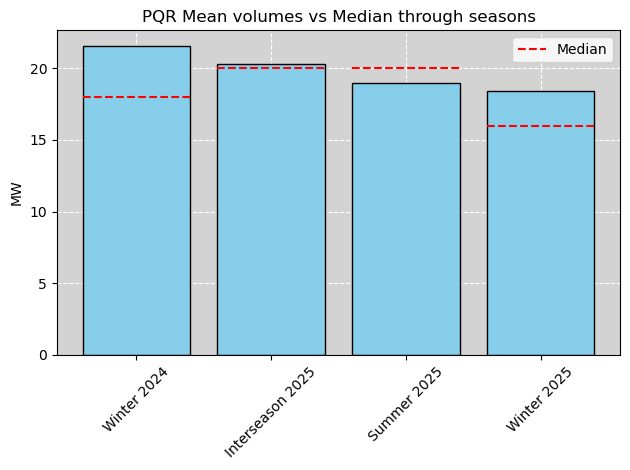

        season  Year       mean  median  min   max             label
2       Winter  2024  21.568045    18.0  1.0  85.0       Winter 2024
0  Interseason  2025  20.297551    20.0  1.0  84.0  Interseason 2025
1       Summer  2025  18.965830    20.0  1.0  89.0       Summer 2025
3       Winter  2025  18.422300    16.0  1.0  85.0       Winter 2025


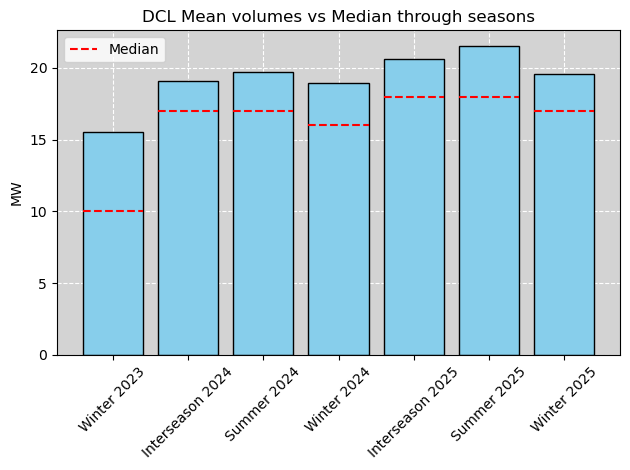

        season  Year       mean  median  min   max             label
4       Winter  2023  15.507711    10.0  0.0  50.0       Winter 2023
0  Interseason  2024  19.108087    17.0  1.0  94.0  Interseason 2024
2       Summer  2024  19.719619    17.0  1.0  94.0       Summer 2024
5       Winter  2024  18.935108    16.0  1.0  91.0       Winter 2024
1  Interseason  2025  20.625255    18.0  1.0  99.0  Interseason 2025
3       Summer  2025  21.537722    18.0  1.0  99.0       Summer 2025
6       Winter  2025  19.538320    17.0  1.0  99.0       Winter 2025


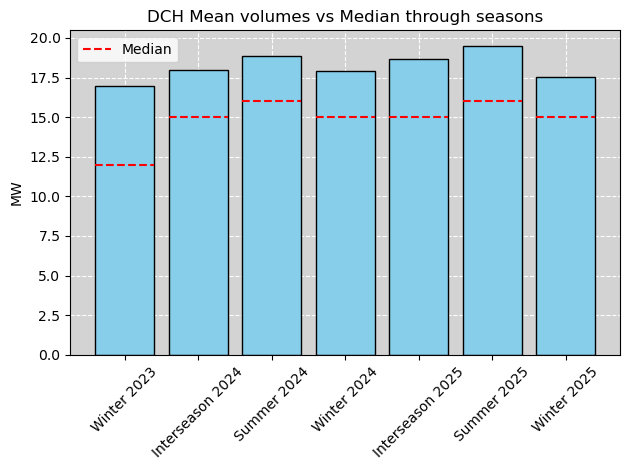

        season  Year       mean  median  min   max             label
4       Winter  2023  16.949083    12.0  0.0  49.0       Winter 2023
0  Interseason  2024  17.979541    15.0  1.0  94.0  Interseason 2024
2       Summer  2024  18.846452    16.0  1.0  91.0       Summer 2024
5       Winter  2024  17.904789    15.0  1.0  93.0       Winter 2024
1  Interseason  2025  18.658868    15.0  1.0  99.0  Interseason 2025
3       Summer  2025  19.502373    16.0  1.0  99.0       Summer 2025
6       Winter  2025  17.501271    15.0  1.0  99.0       Winter 2025


In [ ]:
NESO_ancillary["season"] = np.where(
    NESO_ancillary['deliveryStart'].dt.month.isin([11, 12, 1, 2]), "Winter",
    np.where(NESO_ancillary['deliveryStart'].dt.month.isin([5,6,7,8]), "Summer", "Interseason")
)

NESO_ancillary["Year"] = NESO_ancillary['deliveryStart'].dt.year



for service in set(NESO_ancillary['auctionProduct']):
    
    filter_service = NESO_ancillary[NESO_ancillary['auctionProduct'] == service]
    
    panel = filter_service.groupby(['season', 'Year'])['executedQuantity'].agg(["mean", "median", 'min', 'max'])
    panel = panel.reset_index()
    panel = panel.sort_values('Year')

    # Make combined label for x-axis (e.g. "Spring-2023")
    panel["label"] = panel["season"] + " " + panel["Year"].astype(str)

    # Bar plot of means
    plt.bar(panel["label"], panel["mean"], color="skyblue", edgecolor="black")


    
    # Add median line across each bar
    
    plt.hlines(panel["median"], xmin=[i - 0.4 for i in range(len(panel))],
                xmax=[i + 0.4 for i in range(len(panel))],
                colors="red", linestyles="--", label="Median")


    plt.xticks(rotation=45)
    plt.gca().set_facecolor('lightgrey')
    plt.grid(color='white', linestyle='--', linewidth=0.8)
    plt.gca().set_axisbelow(True) 
        
    plt.ylabel("MW")
    plt.title(f"{service} Mean volumes vs Median through seasons")
    plt.legend()
    plt.tight_layout()
    plt.show()
    print(panel)


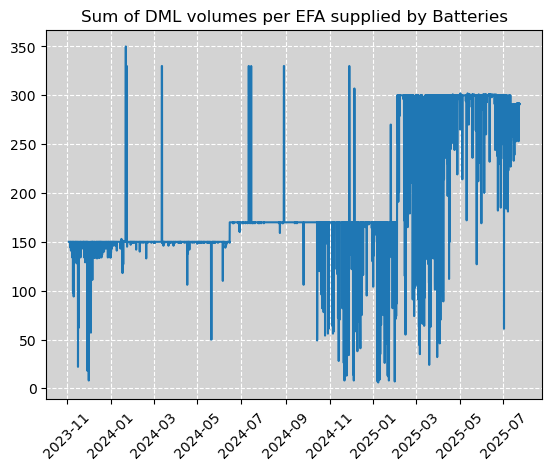

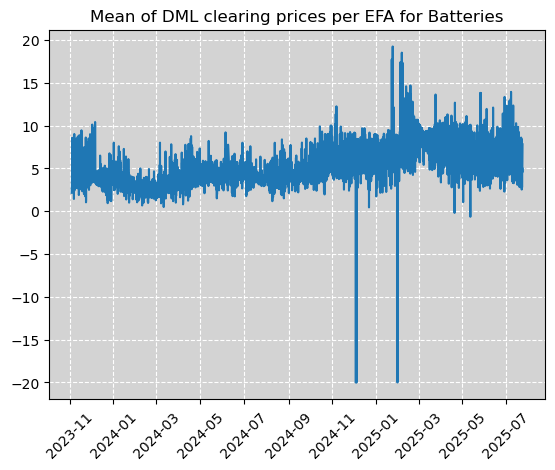

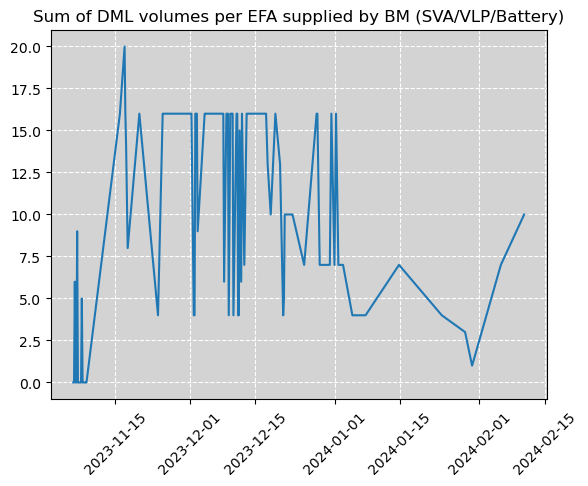

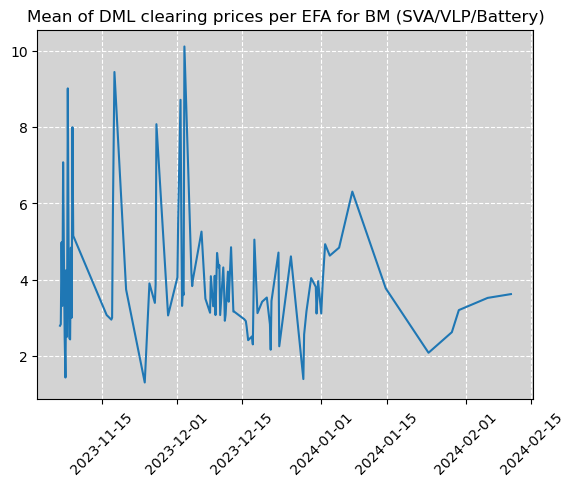

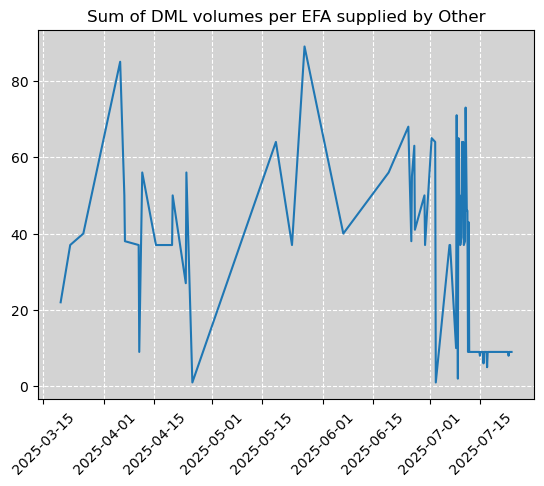

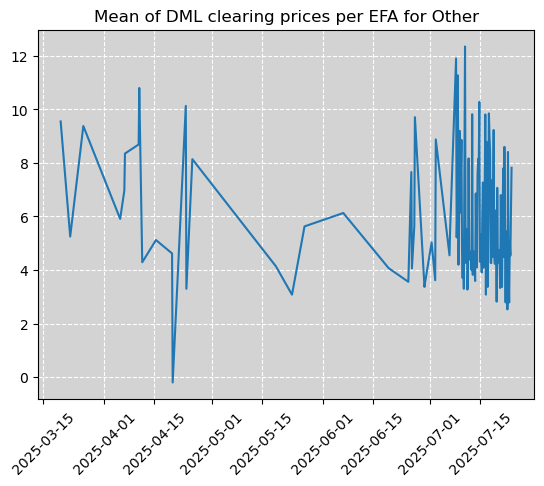

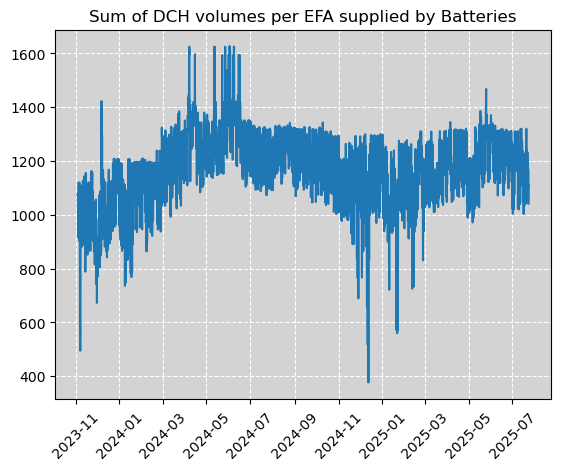

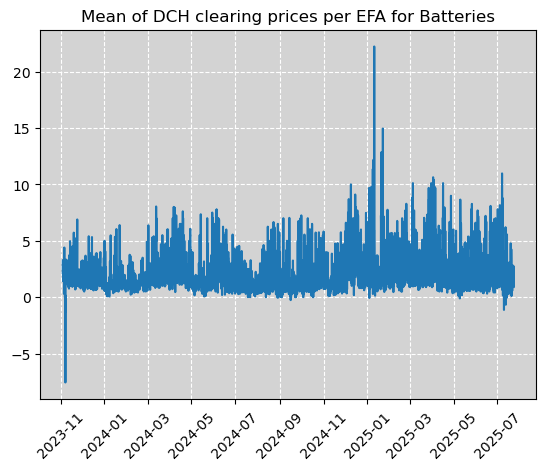

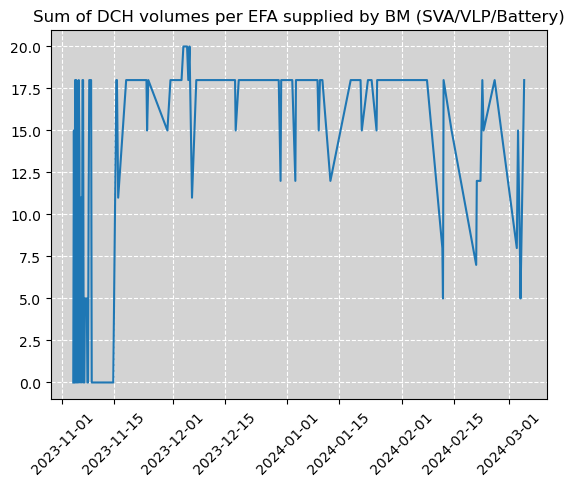

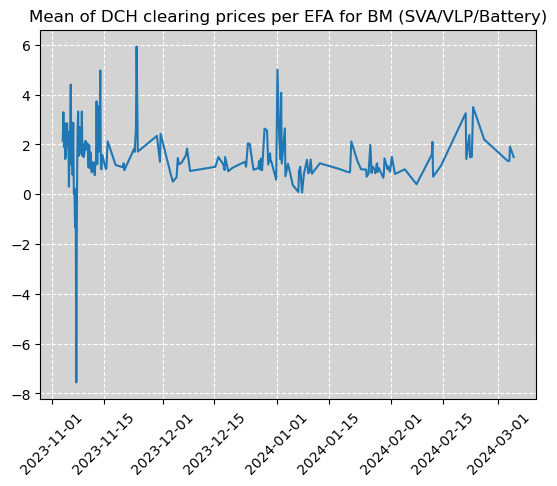

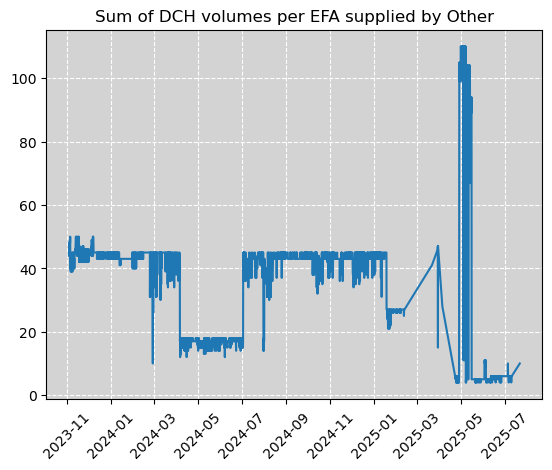

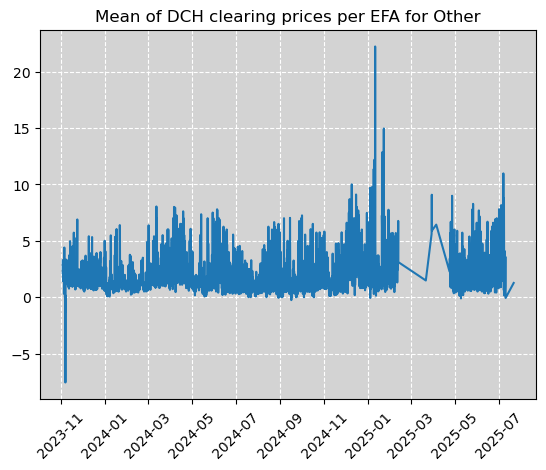

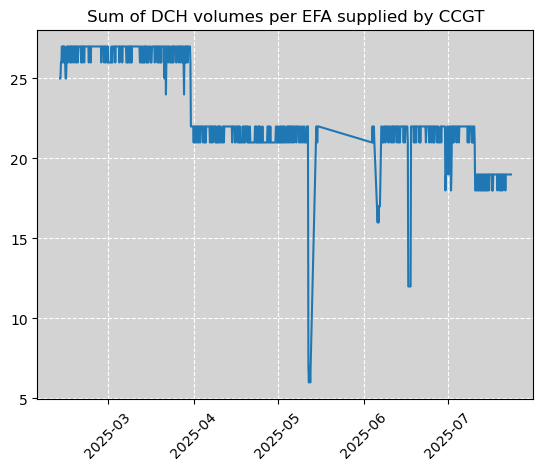

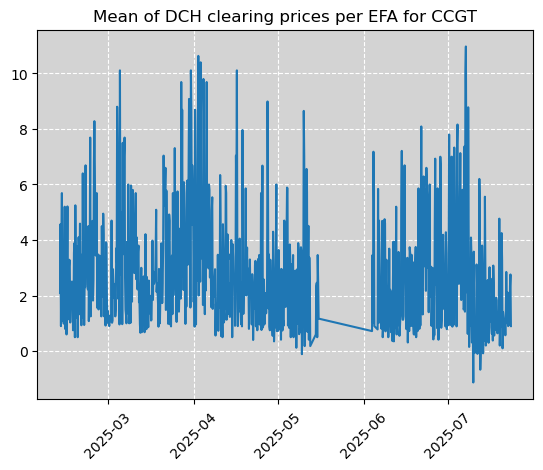

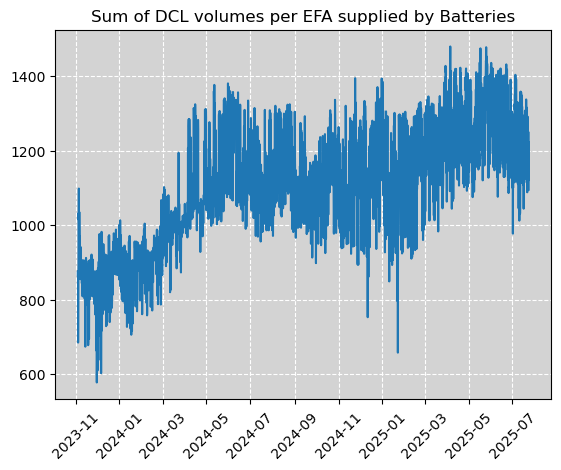

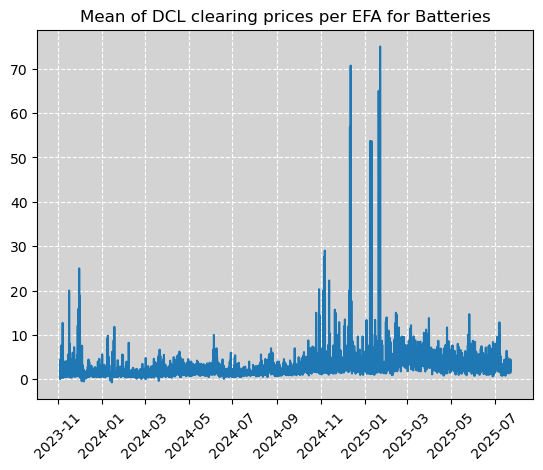

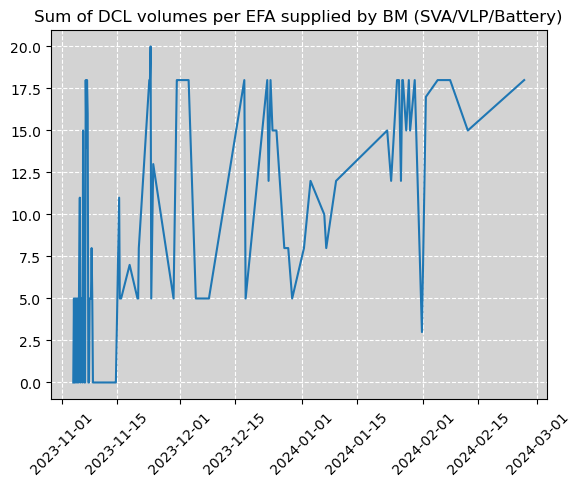

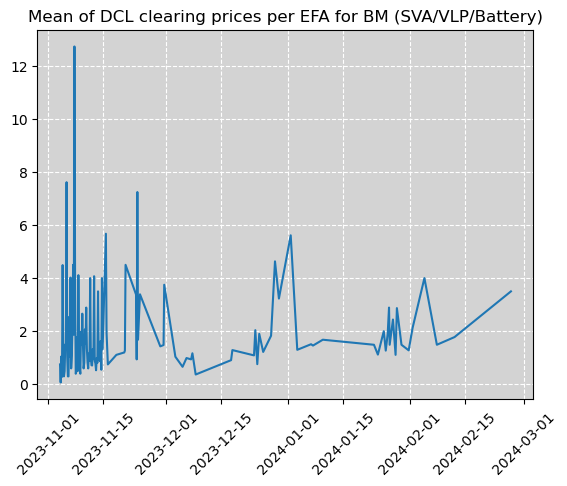

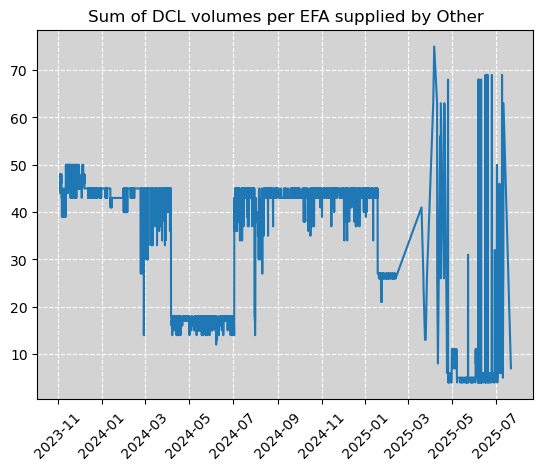

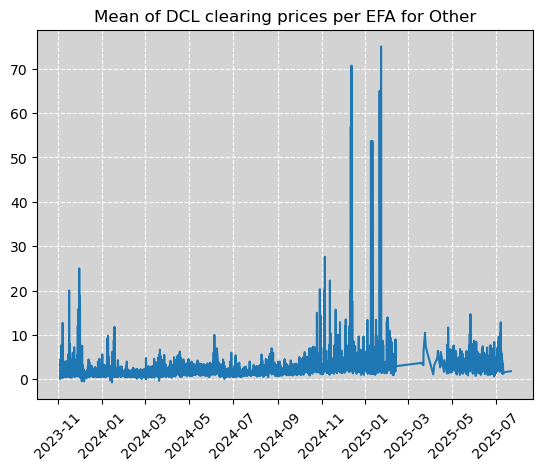

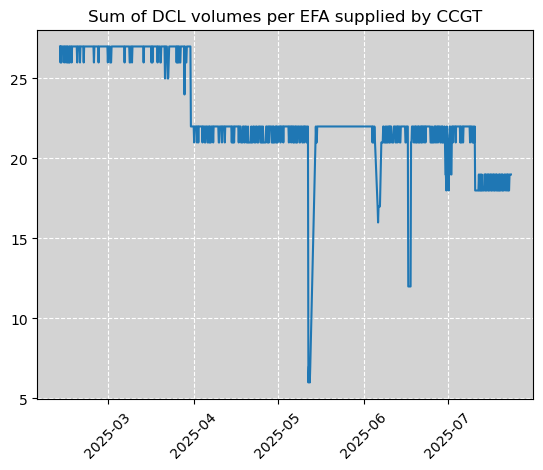

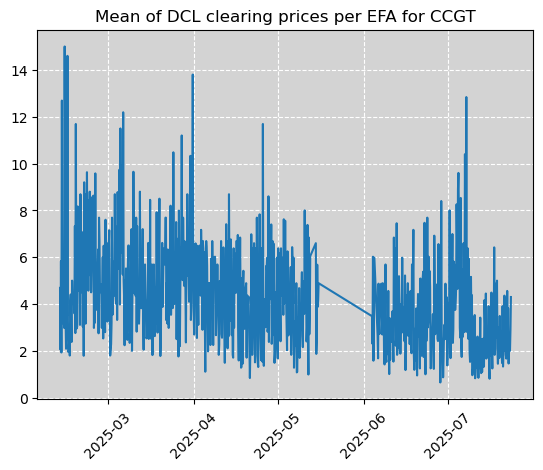

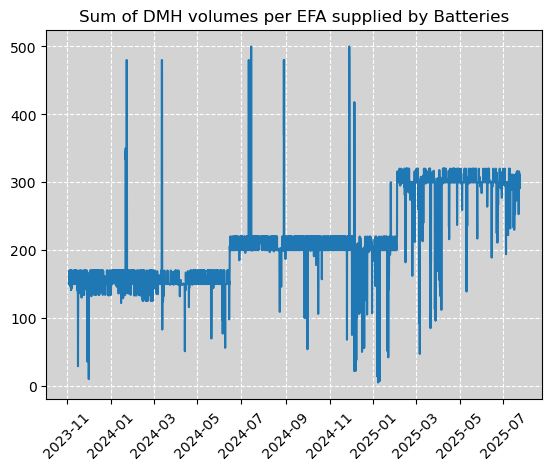

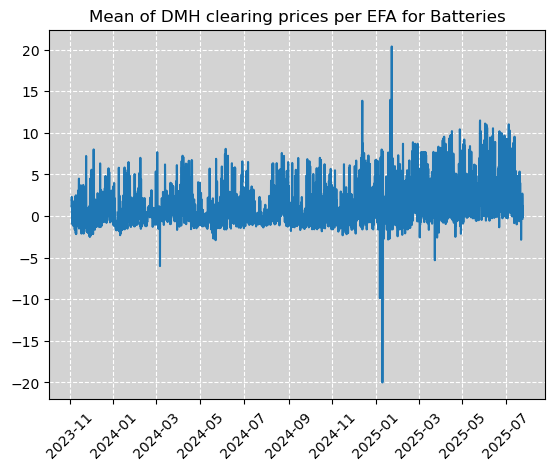

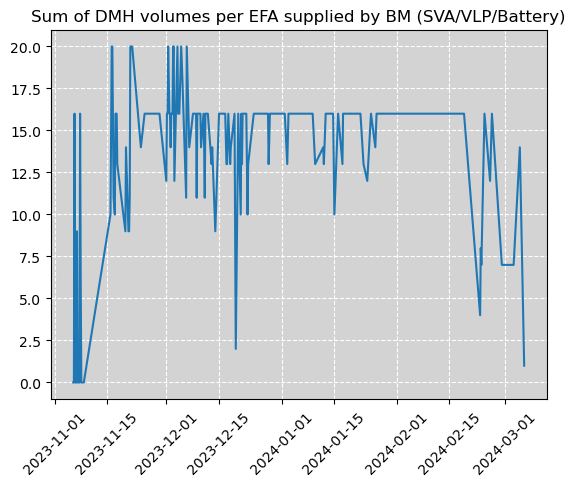

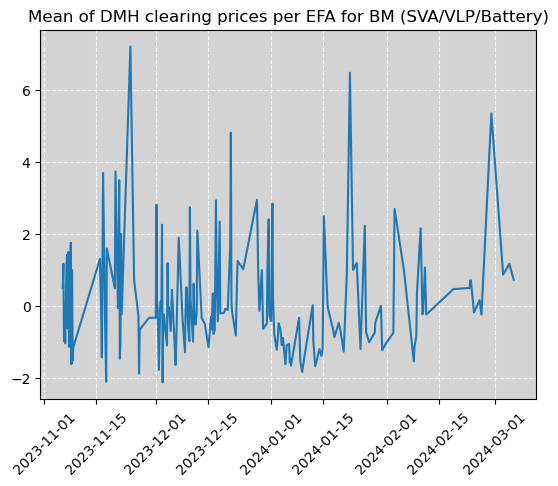

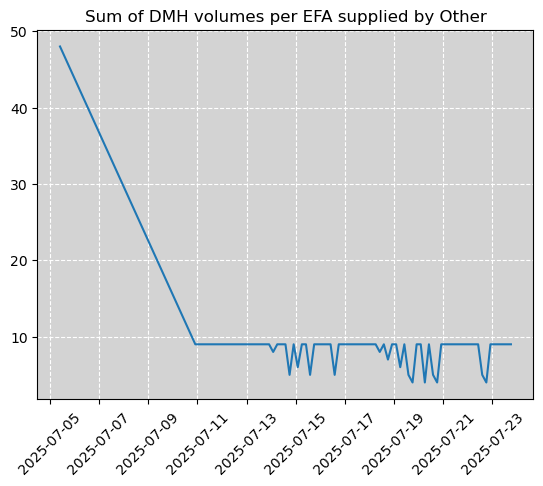

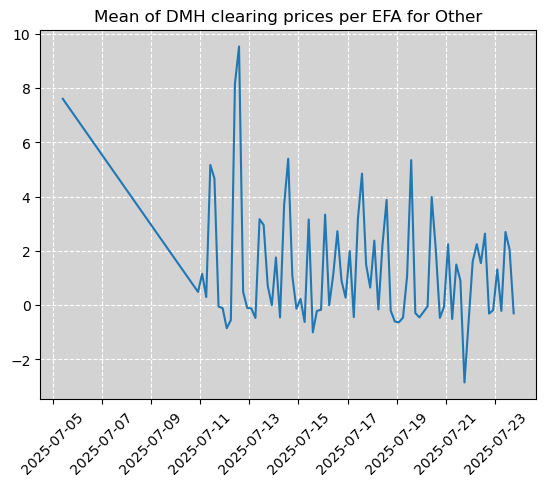

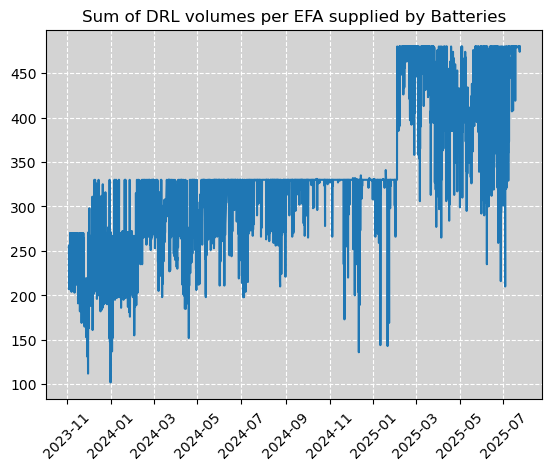

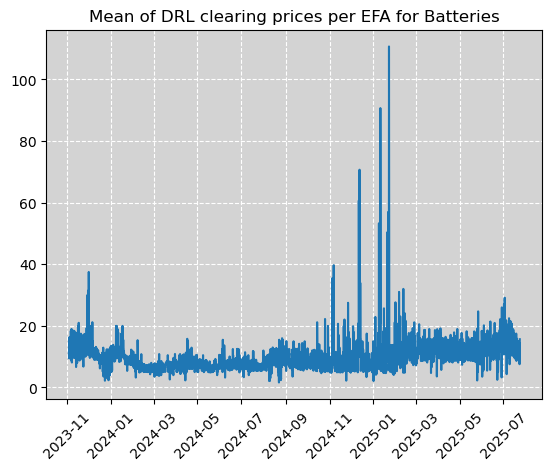

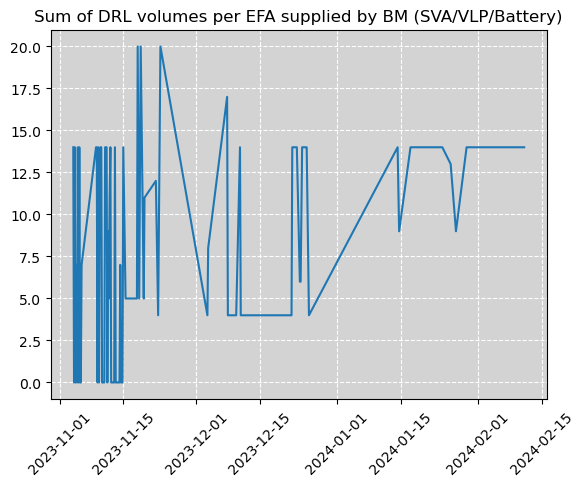

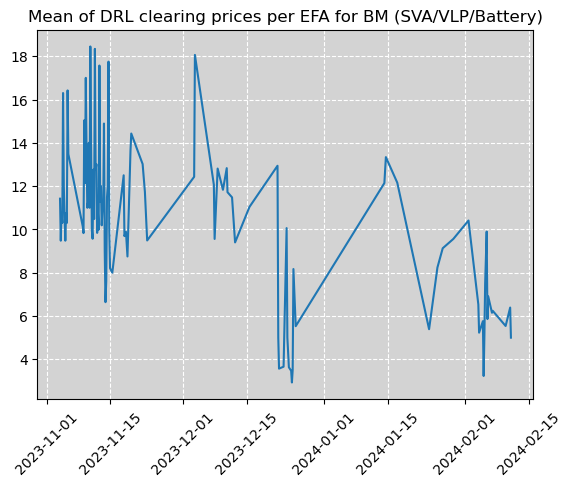

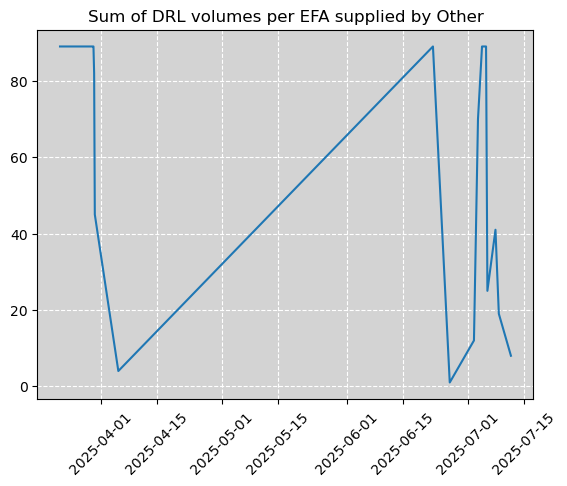

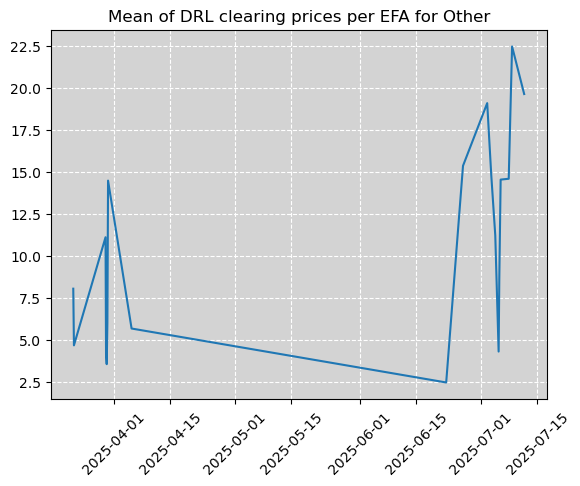

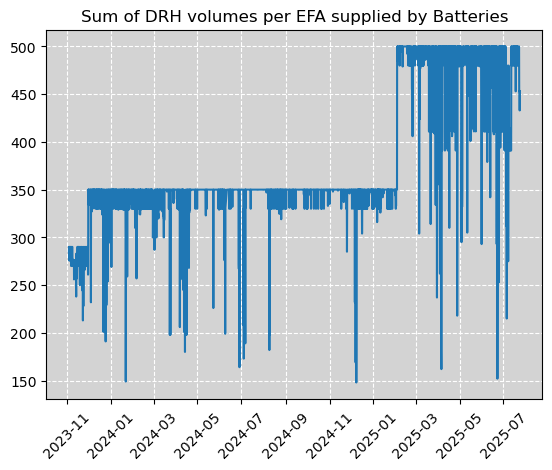

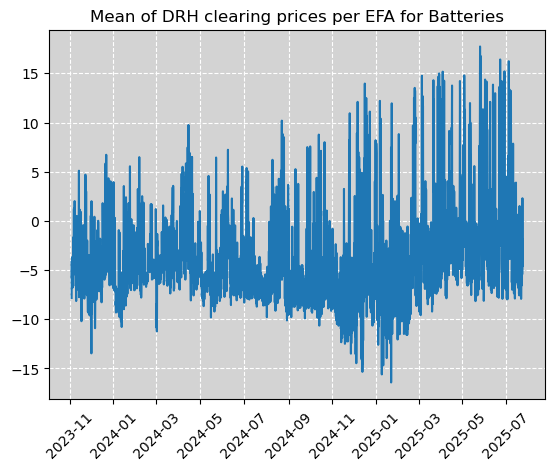

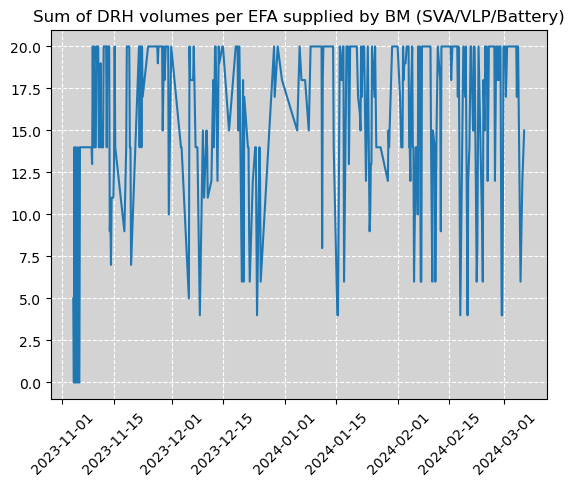

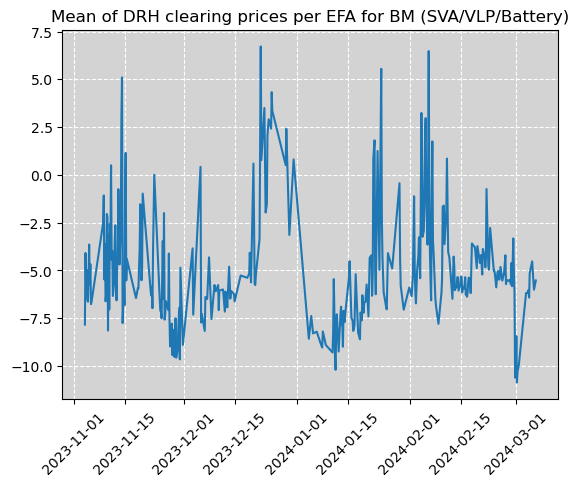

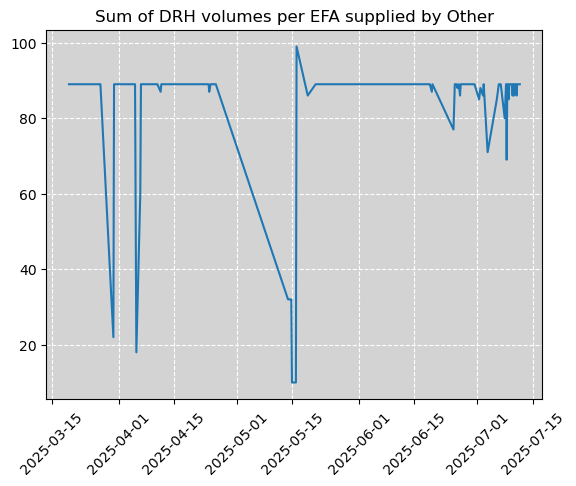

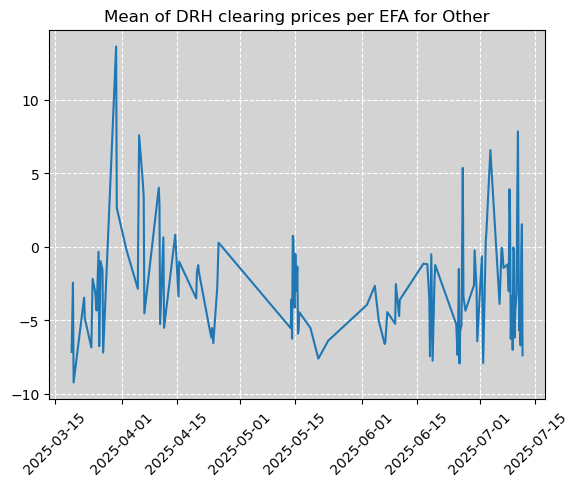

In [ ]:
for service in set(volumesENAPSYS['auctionProduct']):

    filter_service = volumesENAPSYS[volumesENAPSYS['auctionProduct'] == service]
    
    for tech in volumesENAPSYS['technologyType'].unique():
        panel = filter_service[filter_service['technologyType'] == tech]
        
        if panel.empty:
            continue

        
        y = panel['executedQuantity'].groupby(panel['deliveryStart']).sum()
        x = panel['executedQuantity'].groupby(panel['deliveryStart']).sum().index

        plt.plot(x, y)
        plt.xticks(rotation=45) 
        plt.gca().set_facecolor('lightgrey')
        plt.grid(color='white', linestyle='--', linewidth=0.8)
        plt.gca().set_axisbelow(True) 
        plt.title(f'Sum of {service} volumes per EFA supplied by {tech}')
        plt.show()
        
        y =  panel['clearingPrice'].groupby(panel['deliveryStart']).mean()

        plt.plot(x,y)
        plt.title(f'Mean of {service} clearing prices per EFA for {tech}')
        plt.xticks(rotation=45) 
        plt.gca().set_facecolor('lightgrey')
        plt.grid(color='white', linestyle='--', linewidth=0.8)
        plt.gca().set_axisbelow(True) 
        plt.show()

### SFFR and STOR (has tech~)

In [89]:
SFFR_data = pd.read_csv(path_dir /"data/static-firm-frequency-response-auction-results.csv", encoding='cp1252', parse_dates=['Delivery Start', 'Delivery End'])
# SFFR_data = SFFR_data[SFFR_data['Status'] != 'Rejected']

STOR_data = pd.read_csv(path_dir /"data/stor-da-auction-results.csv", encoding='cp1252', parse_dates=['Service Delivery From', 'Service Delivery To'])
# STOR_data = STOR_data[STOR_data['Status'] != 'Rejected']

In [96]:
SFFR_data.rename(columns={'Clearing Price':'Market Clearing Price', 'Accepted Volume' : 'Contracted MW'}, inplace=True)

In [97]:
SFFR_data

,Date,Provider,Unit,Delivery Start,Delivery End,EFA,Service,Status,Volume,Contracted MW,Price,Market Clearing Price,Technology Type,Location,Rank
0,2023-04-01,Centrica Business Solutions Uk Optimisation UK...,CBSO-2,2023-03-31 23:00:00,2023-04-01 03:00:00,1,SFFR,Accepted,7,7,0.70,4.50,Diesel,BS2 8HW,20
1,2023-04-01,Zenobe Energy Ltd,DBESSH-33,2023-03-31 23:00:00,2023-04-01 03:00:00,1,SFFR,Accepted,9,9,1.00,4.50,Batteries,BN44,5
2,2023-04-01,First Renewable Alpha Ltd,FRASFFR,2023-03-31 23:00:00,2023-04-01 03:00:00,1,SFFR,Accepted,20,20,3.50,4.50,Diesel,PL32 9SW,15
3,2023-04-01,GRIDBEYOND LIMITED,ENDSR-6,2023-03-31 23:00:00,2023-04-01 03:00:00,1,SFFR,Accepted,20,20,3.63,4.50,Load Response,AGG,1
4,2023-04-01,GRIDBEYOND LIMITED,ENDSR-4,2023-03-31 23:00:00,2023-04-01 03:00:00,1,SFFR,Accepted,3,3,3.63,4.50,Load Response,AGG,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
162134,2025-10-22,Levelise Limited,LEV-FRU04,2025-10-22 19:00:00,2025-10-22 23:00:00,6,SFFR,Accepted,1,1,3.50,7.25,Batteries,AGG,31
162135,2025-10-22,Levelise Limited,LEV-FRU09,2025-10-22 19:00:00,2025-10-22 23:00:00,6,SFFR,Accepted,1,1,3.50,7.25,Batteries,AGG,35
162136,2025-10-22,GRIDBEYOND LIMITED,ENDSR-11,2025-10-22 19:00:00,2025-10-22 23:00:00,6,SFFR,Accepted,2,2,3.96,7.25,Load Response,AGG,29
162137,2025-10-22,GRIDBEYOND LIMITED,ENDSR-12,2025-10-22 19:00:00,2025-10-22 23:00:00,6,SFFR,Accepted,3,3,4.50,7.25,Load Response,AGG,7


In [ ]:
for status in ['Rejected', 'Accepted']:
    for data in [STOR_data,SFFR_data]:
        for corr, pval in zip(['pearson', 'spearman', 'kendall'], [pearsonr, spearmanr, kendalltau]):
        
            panel = data[(data['Status'] != status)]
            
            coef, pval = pval(panel['Market Clearing Price'], panel['Contracted MW'])
            
            print(f"Without {status}, {round(coef,3)} for {corr}")
            # print(round(pval,3))
                                
 

Without Rejected, -0.033 for pearson
Without Rejected, -0.025 for spearman
Without Rejected, -0.017 for kendall
Without Rejected, -0.166 for pearson
Without Rejected, -0.197 for spearman
Without Rejected, -0.139 for kendall
Without Accepted, nan for pearson
Without Accepted, nan for spearman
Without Accepted, nan for kendall
Without Accepted, nan for pearson
Without Accepted, nan for spearman
Without Accepted, nan for kendall


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_21168\3913963573.py:7: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  coef, pval = pval(df['Market Clearing Price'], df['Contracted MW'])


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_16892\3596418244.py:25: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(index=['season','Year'], columns='Fuel Type',


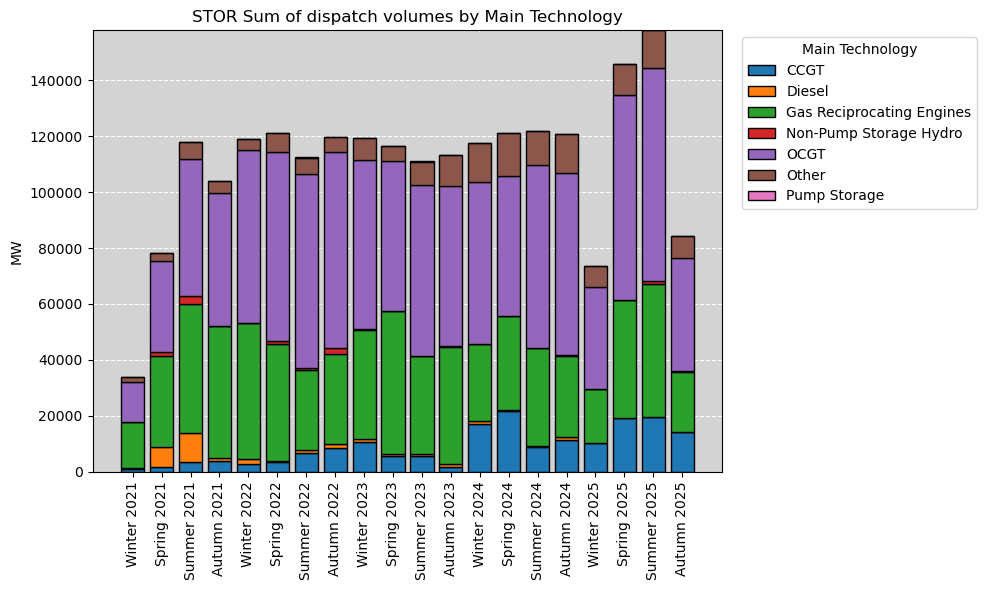

In [35]:
# --- season/year labeling
STOR_data["season"] = np.where(
    STOR_data['Service Delivery From'].dt.month.isin([12, 1, 2]), "Winter",
    np.where(STOR_data['Service Delivery From'].dt.month.isin([3, 4, 5]), "Spring",
    np.where(STOR_data['Service Delivery From'].dt.month.isin([6, 7, 8]), "Summer",
             "Autumn"))
)
STOR_data["Year"] = STOR_data['Service Delivery From'].dt.year

# mean per row grouped by season, year, technology
stack_data = (
    STOR_data
      .groupby(['season','Year','Fuel Type'])['Contracted MW']
      .sum()
      .reset_index()
)

# pivot so each technology is a column
season_order = ["Winter", "Spring", "Summer", "Autumn"]

stack_data['season'] = pd.Categorical(stack_data['season'], season_order, ordered=True)

stack_pivot = (
    stack_data
      .pivot_table(index=['season','Year'], columns='Fuel Type',
                   values='Contracted MW', fill_value=0).sort_index(level=['Year','season'], sort_remaining=False)
)


# labels like "Winter 2024"
x_labels = [f"{s} {y}" for s, y in stack_pivot.index.to_list()]


# --- plotting ---
fig, ax = plt.subplots(figsize=(10,6))
bottom = np.zeros(len(stack_pivot))

for tech in stack_pivot.columns:
    heights = stack_pivot[tech].to_numpy()
    ax.bar(x_labels, heights, bottom=bottom, edgecolor='black', label=tech)
    bottom += heights


ax.set_facecolor('lightgrey')
ax.grid(axis='y', color='white', linestyle='--', linewidth=0.8)
ax.set_axisbelow(True)
plt.xticks(rotation=90)
plt.ylabel("MW")
plt.title("STOR Sum of dispatch volumes by Main Technology")
ax.legend(title="Main Technology", bbox_to_anchor=(1.02,1), loc='upper left')
plt.tight_layout()
plt.show()

In [92]:
SFFR_data

,Date,Provider,Unit,Delivery Start,Delivery End,EFA,Service,Status,Volume,Accepted Volume,Price,Clearing Price,Technology Type,Location,Rank,season,Year
0,2023-04-01,Centrica Business Solutions Uk Optimisation UK...,CBSO-2,2023-03-31 23:00:00,2023-04-01 03:00:00,1,SFFR,Accepted,7,7,0.70,4.50,Diesel,BS2 8HW,20,Interseason,2023
1,2023-04-01,Zenobe Energy Ltd,DBESSH-33,2023-03-31 23:00:00,2023-04-01 03:00:00,1,SFFR,Accepted,9,9,1.00,4.50,Batteries,BN44,5,Interseason,2023
2,2023-04-01,First Renewable Alpha Ltd,FRASFFR,2023-03-31 23:00:00,2023-04-01 03:00:00,1,SFFR,Accepted,20,20,3.50,4.50,Diesel,PL32 9SW,15,Interseason,2023
3,2023-04-01,GRIDBEYOND LIMITED,ENDSR-6,2023-03-31 23:00:00,2023-04-01 03:00:00,1,SFFR,Accepted,20,20,3.63,4.50,Load Response,AGG,1,Interseason,2023
4,2023-04-01,GRIDBEYOND LIMITED,ENDSR-4,2023-03-31 23:00:00,2023-04-01 03:00:00,1,SFFR,Accepted,3,3,3.63,4.50,Load Response,AGG,2,Interseason,2023
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
162134,2025-10-22,Levelise Limited,LEV-FRU04,2025-10-22 19:00:00,2025-10-22 23:00:00,6,SFFR,Accepted,1,1,3.50,7.25,Batteries,AGG,31,Interseason,2025
162135,2025-10-22,Levelise Limited,LEV-FRU09,2025-10-22 19:00:00,2025-10-22 23:00:00,6,SFFR,Accepted,1,1,3.50,7.25,Batteries,AGG,35,Interseason,2025
162136,2025-10-22,GRIDBEYOND LIMITED,ENDSR-11,2025-10-22 19:00:00,2025-10-22 23:00:00,6,SFFR,Accepted,2,2,3.96,7.25,Load Response,AGG,29,Interseason,2025
162137,2025-10-22,GRIDBEYOND LIMITED,ENDSR-12,2025-10-22 19:00:00,2025-10-22 23:00:00,6,SFFR,Accepted,3,3,4.50,7.25,Load Response,AGG,7,Interseason,2025


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_16892\2955576674.py:25: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(index=['season','Year'], columns='Technology Type',


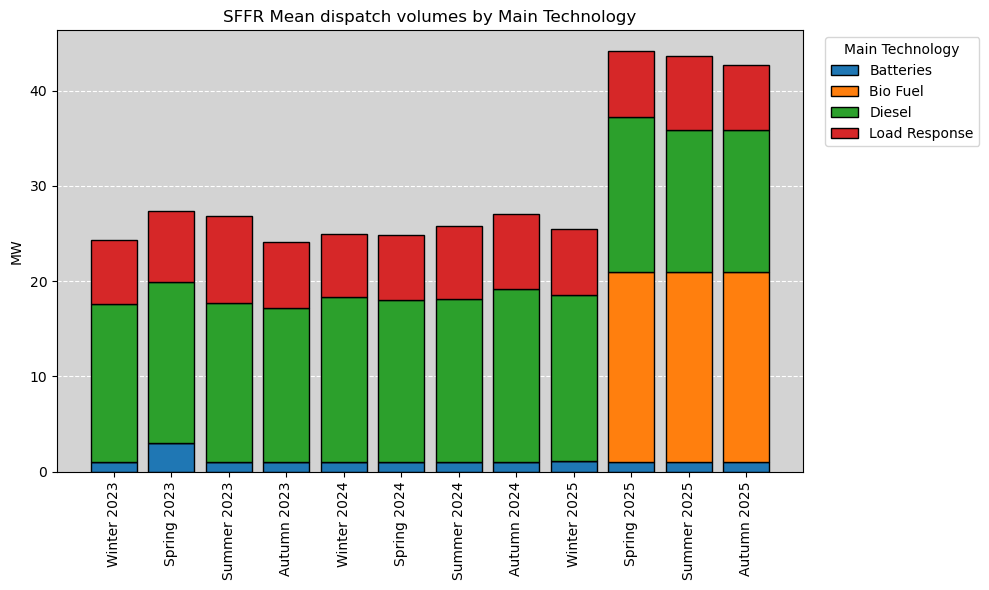

In [36]:
# --- season/year labeling
SFFR_data["season"] = np.where(SFFR_data['Delivery Start'].dt.month.isin([12, 1, 2]), "Winter",
    np.where(SFFR_data['Delivery Start'].dt.month.isin([3, 4, 5]), "Spring",
    np.where(SFFR_data['Delivery Start'].dt.month.isin([6, 7, 8]), "Summer",
             "Autumn"))
)

SFFR_data["Year"] = SFFR_data['Delivery Start'].dt.year

# mean per row grouped by season, year, technology
stack_data = (
    SFFR_data
      .groupby(['season','Year','Technology Type'])['Accepted Volume']
      .mean()
      .reset_index()
)

# pivot so each technology is a column
season_order = ["Winter", "Spring", "Summer", "Autumn"]
stack_data['season'] = pd.Categorical(stack_data['season'], season_order, ordered=True)

stack_pivot = (
    stack_data
      .sort_values(['Year','season'])
      .pivot_table(index=['season','Year'], columns='Technology Type',
                   values='Accepted Volume', fill_value=0).sort_index(level=['Year','season'], sort_remaining=False)
)

# labels like "Winter 2024"
x_labels = [f"{s} {y}" for s, y in stack_pivot.index.to_list()]


# --- plotting ---
fig, ax = plt.subplots(figsize=(10,6))
bottom = np.zeros(len(stack_pivot))

for tech in stack_pivot.columns:
    heights = stack_pivot[tech].to_numpy()
    ax.bar(x_labels, heights, bottom=bottom, edgecolor='black', label=tech)
    bottom += heights


ax.set_facecolor('lightgrey')
ax.grid(axis='y', color='white', linestyle='--', linewidth=0.8)
ax.set_axisbelow(True)
plt.xticks(rotation=90)
plt.ylabel("MW")
plt.title("SFFR Mean dispatch volumes by Main Technology")
ax.legend(title="Main Technology", bbox_to_anchor=(1.02,1), loc='upper left')
plt.tight_layout()
plt.show()


## DSO

In [100]:
NGED_dispatches = pd.concat([pd.read_csv(path_dir / "data/NGED_dispatches_2024-25.csv", encoding='cp1252'),
                             pd.read_csv(path_dir / "data/NGED_dispatches_CMZ.csv", encoding='cp1252')])

NGED_postcodes = pd.read_csv(path_dir /"data/NGED_postcode_to_CMZ.csv", encoding='cp1252')

UKPN_dispatches = pd.read_csv(path_dir /"data/UKPN_dispatches_CMZ.csv", encoding='cp1252')
UKPN_postcodes = pd.read_csv(path_dir /"data/UKPN_postcode_to_CMZ.csv", encoding='cp1252')

In [101]:
def clean_new_dispatches(df: pd.DataFrame):
    
    try: ## for nged
        assert((df['Provider Licence Area'] == df['Constraint Licence Area']).all()) ##just wanted to check
    
        df = df.iloc[:, :-2] # last two columns removed, one is notes the other one isnt even labeled
        df.rename(columns={'Constraint Licence Area': 'Licence Area',
                        "Incident Reference ": "Incident Reference"}, inplace=True)    
        
        df['constraint_window_rounded_start'] = pd.to_datetime(df['Start Date of Instruction (DD/MM/YYYY)'] + ' ' + df['Start Time of Instruction (HH:MM)'], dayfirst=True).dt.round("30min")
        df['constraint_window_rounded_end'] = pd.to_datetime(df['End Date of Instruction (DD/MM/YYYY)'] + ' ' + df['End Time of Instruction (HH:MM)'], dayfirst=True).dt.round("30min")
        
        df.drop(columns=['Provider Licence Area', 'Dispatch Capacity (MVAr)',
                        'Dispatch Volume (MVArh)', 'Start Date of Instruction (DD/MM/YYYY)',
                        'End Date of Instruction (DD/MM/YYYY)', 'Start Time of Instruction (HH:MM)',
                        'End Time of Instruction (HH:MM)', 'Tender Reference'], inplace= True) #tender ref is inconsistent
        
        df = df.sort_values("constraint_window_rounded_start").reset_index(drop=True)
        
    except KeyError: ## for ukpn
        
        df['constraint_window_rounded_start'] = pd.to_datetime(df['start_time_utc']).dt.tz_localize(None).round("30min")
        df['constraint_window_rounded_end'] = pd.to_datetime(df['end_time_utc']).dt.tz_localize(None).round("30min")
        
        df = df.iloc[:, [0, 1, 2, 3, 10, 11, 12, 13, 16, 17]] # remove unnecessary columns
        
        df.columns = ['Accepting Party', 'Flexible Unit ID', 'Constraint Management Zone Name', 'Product',
                      'Dispatch Volume (MWh)', 'Utilisation Price (£/MWh)', 'Constraint Trigger', 'Main Technology',
                      'constraint_window_rounded_start', 'constraint_window_rounded_end']
        
    return df

In [102]:
UKPN_dispatch = clean_new_dispatches(UKPN_dispatches)
UKPN_dispatch["dno"] = "ukpn"

NGED_dispatch = clean_new_dispatches(NGED_dispatches)
NGED_dispatch["dno"] = "nged"
NGED_dispatch["Constraint Trigger"] = "demand_turn_down"

common_cols = NGED_dispatch.columns.intersection(UKPN_dispatch.columns)
# dispatches = pd.concat(
#     [NGED_dispatch[common_cols], UKPN_dispatch[common_cols]], ignore_index=True
# ) ### this will have dispatches that have no postcodes to map to their CMZ
dispatches = UKPN_dispatch
dispatches.drop_duplicates(inplace=True)
dispatches.rename(columns={"Constraint Management Zone Name": "cmz_id"}, inplace=True)
dispatches = dispatches[dispatches['Dispatch Volume (MWh)'] != 0] ###remove rows with dispatch volume at 0
dispatches.loc[dispatches['Product'] == 'day_ahead','Product'] = 'day-ahead'
dispatches.loc[dispatches['Main Technology'] == 'Stored Energy (all stored energy irrespective of the original energy source)','Main Technology'] = 'Stored Energy'
############ Find start and end times to bookend timeseries 

# Take the recorded start and end times of the dispatches, round the start times to the nearest half hour before and 
# round the end times to the nearest half hour before (this is equivalent to rounding the time up and down)

dispatch_times = dispatches['constraint_window_rounded_start']
dispatch_start_minutes_rounded_down = (dispatch_times.dt.minute - dispatch_times.dt.minute % 30)

dispatch_start_rounded_datetimes = pd.to_datetime(dispatch_times.dt.date.astype('string') + ' ' + 
                                          dispatch_times.dt.hour.astype('string') + ':' + 
                                          dispatch_start_minutes_rounded_down.astype('string'))
first_dispatch_datetime = min(dispatch_start_rounded_datetimes)

dispatch_end_times = dispatches['constraint_window_rounded_end']
dispatch_end_minutes_rounded_down = (dispatch_end_times.dt.minute - dispatch_end_times.dt.minute % 30)

dispatch_end_rounded_datetimes = pd.to_datetime(dispatch_end_times.dt.date.astype('string') + ' ' + 
                                          dispatch_end_times.dt.hour.astype('string') + ':' + 
                                          dispatch_end_minutes_rounded_down.astype('string'))
last_dispatch_datetime = max(dispatch_end_rounded_datetimes)

dispatches['constraint_window_rounded_start'] = dispatch_start_rounded_datetimes
dispatches['constraint_window_rounded_end'] = dispatch_end_rounded_datetimes

dispatches = dispatches[dispatches['Main Technology'].isin(['Stored Energy','Demand', 'Solar', 'EV', 'PV'])]
# --- season/year labeling
dispatches["season"] = np.where(
    dispatches['constraint_window_rounded_start'].dt.month.isin([11, 12, 1, 2]), "Winter",
    np.where(dispatches['constraint_window_rounded_start'].dt.month.isin([3,4,5]), "Summer",
             np.where(dispatches['constraint_window_rounded_start'].dt.month.isin([6,7,8]), "Spring",
             "Autumn"))
)
dispatches["Year"] = dispatches['constraint_window_rounded_start'].dt.year

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_21168\3476996434.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  UKPN_dispatch["dno"] = "ukpn"
C:\Users\Duval1e\AppData\Local\Temp\ipykernel_21168\3476996434.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dispatches.drop_duplicates(inplace=True)
C:\Users\Duval1e\AppData\Local\Temp\ipykernel_21168\3476996434.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.ht

In [104]:
for product in dispatches['Product'].unique():
        for corr, pval in zip(['pearson', 'spearman', 'kendall'], [pearsonr, spearmanr, kendalltau]):
        
            coef, pval = pval(dispatches['Utilisation Price (£/MWh)'], dispatches['Dispatch Volume (MWh)'])
            
            print(f"For {product}, {round(coef,3)} for {corr}")


For dynamic, 0.005 for pearson
For dynamic, -0.068 for spearman
For dynamic, -0.048 for kendall
For secure, 0.005 for pearson
For secure, -0.068 for spearman
For secure, -0.048 for kendall
For day-ahead, 0.005 for pearson
For day-ahead, -0.068 for spearman
For day-ahead, -0.048 for kendall


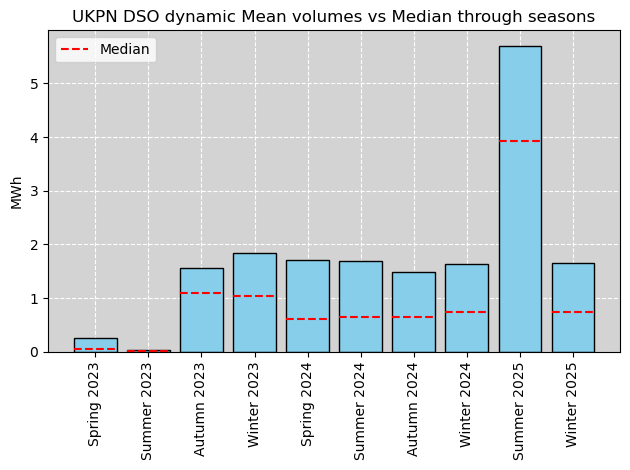

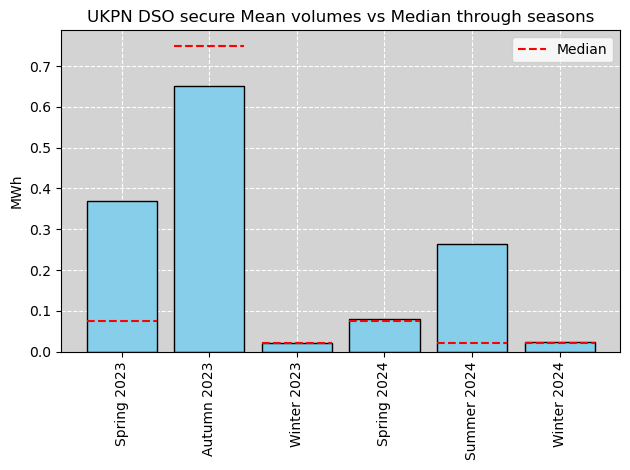

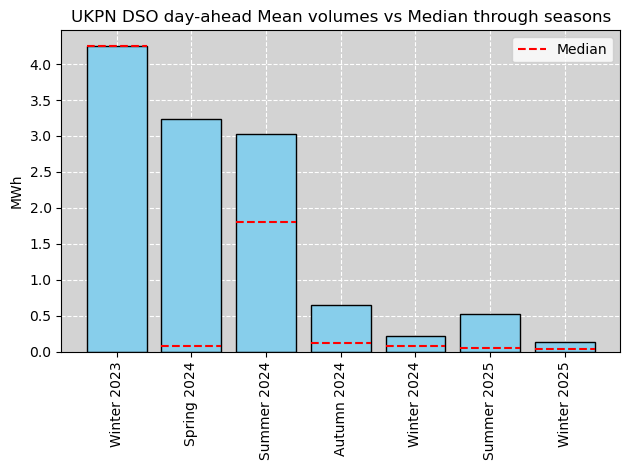

In [ ]:

for product in dispatches['Product'].unique():
    filter_product = dispatches[dispatches['Product']== product]
    
    panel = filter_product.groupby(['season', 'Year'])['Dispatch Volume (MWh)'].agg(["mean", "median", 'min', 'max']).reset_index()
    season_order = ["Spring", "Summer", "Autumn", "Winter"]
    panel["season"] = pd.Categorical(panel["season"], categories=season_order, ordered=True)

    # ✅ sort by year first, then by season (in the order above)
    panel = panel.sort_values(["Year", "season"]).reset_index(drop=True)

    # Make combined label for x-axis (e.g. "Spring-2023")
    panel["label"] = panel["season"].astype(str) + " " + panel["Year"].astype(str)


    # Bar plot of means
    plt.bar(panel["label"], panel["mean"], color="skyblue", edgecolor="black")

    # Add median line across each bar
    plt.hlines(panel["median"], xmin=[i - 0.4 for i in range(len(panel))],
                xmax=[i + 0.4 for i in range(len(panel))],
                colors="red", linestyles="--", label="Median")


    plt.xticks(rotation=90)
    plt.gca().set_facecolor('lightgrey')
    plt.grid(color='white', linestyle='--', linewidth=0.8)
    plt.gca().set_axisbelow(True) 
        
    plt.ylabel("MWh")
    plt.title(f"UKPN DSO {product} Mean volumes vs Median through seasons")
    plt.legend()
    plt.tight_layout()
    plt.show()

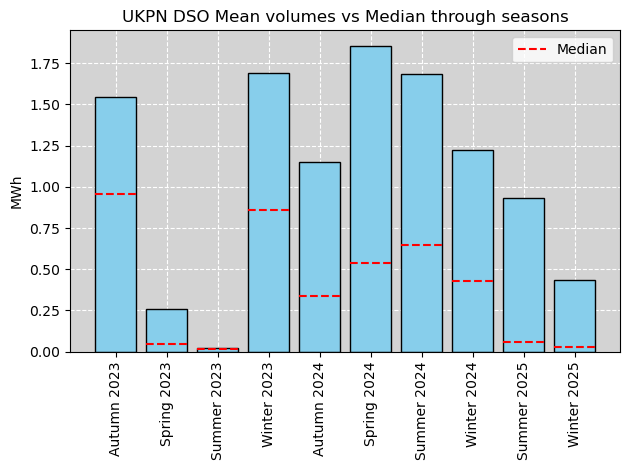

In [ ]:
dispatches = dispatches[dispatches['Main Technology'].isin(['Stored Energy (all stored energy irrespective of the original energy source)','Demand', 'Solar', 'EV', 'PV'])]
# --- season/year labeling
dispatches["season"] = np.where(
    dispatches['constraint_window_rounded_start'].dt.month.isin([11, 12, 1, 2]), "Winter",
    np.where(dispatches['constraint_window_rounded_start'].dt.month.isin([3,4,5]), "Summer",
             np.where(dispatches['constraint_window_rounded_start'].dt.month.isin([6,7,8]), "Spring",
             "Autumn"))
)
dispatches["Year"] = dispatches['constraint_window_rounded_start'].dt.year


panel = dispatches.groupby(['season', 'Year'])['Dispatch Volume (MWh)'].agg(["mean", "median", 'min', 'max'])
panel = panel.reset_index()
panel = panel.sort_values('Year')

# Make combined label for x-axis (e.g. "Spring-2023")
panel["label"] = panel["season"] + " " + panel["Year"].astype(str)

# Bar plot of means
plt.bar(panel["label"], panel["mean"], color="skyblue", edgecolor="black")

# Add median line across each bar
plt.hlines(panel["median"], xmin=[i - 0.4 for i in range(len(panel))],
            xmax=[i + 0.4 for i in range(len(panel))],
            colors="red", linestyles="--", label="Median")


plt.xticks(rotation=90)
plt.gca().set_facecolor('lightgrey')
plt.grid(color='white', linestyle='--', linewidth=0.8)
plt.gca().set_axisbelow(True) 
    
plt.ylabel("MWh")
plt.title("UKPN DSO Mean volumes vs Median through seasons")
plt.legend()
plt.tight_layout()
plt.show()


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_16892\3436289143.py:20: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(index=['season','Year'], columns='Main Technology',


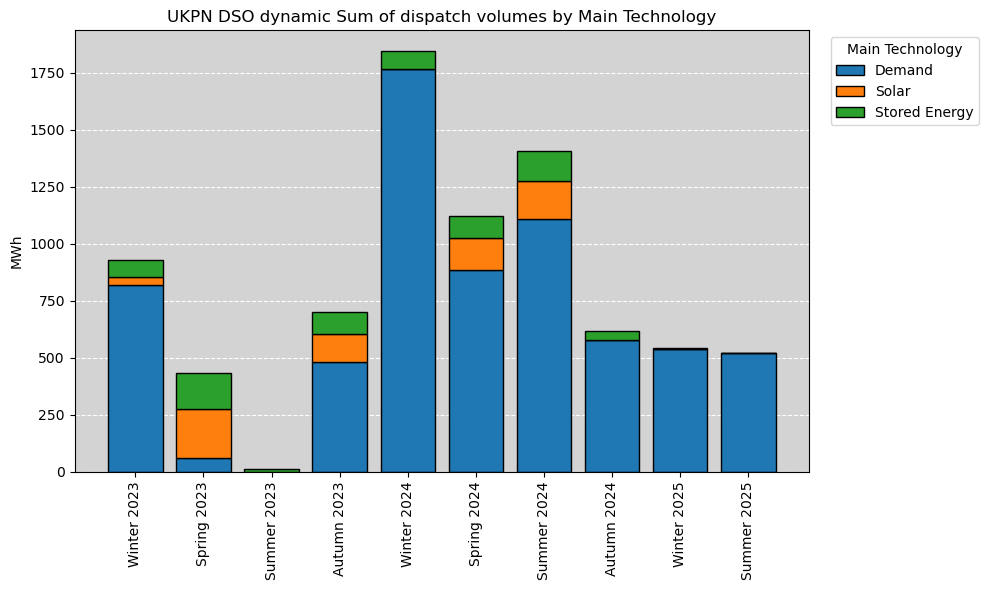

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_16892\3436289143.py:20: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(index=['season','Year'], columns='Main Technology',


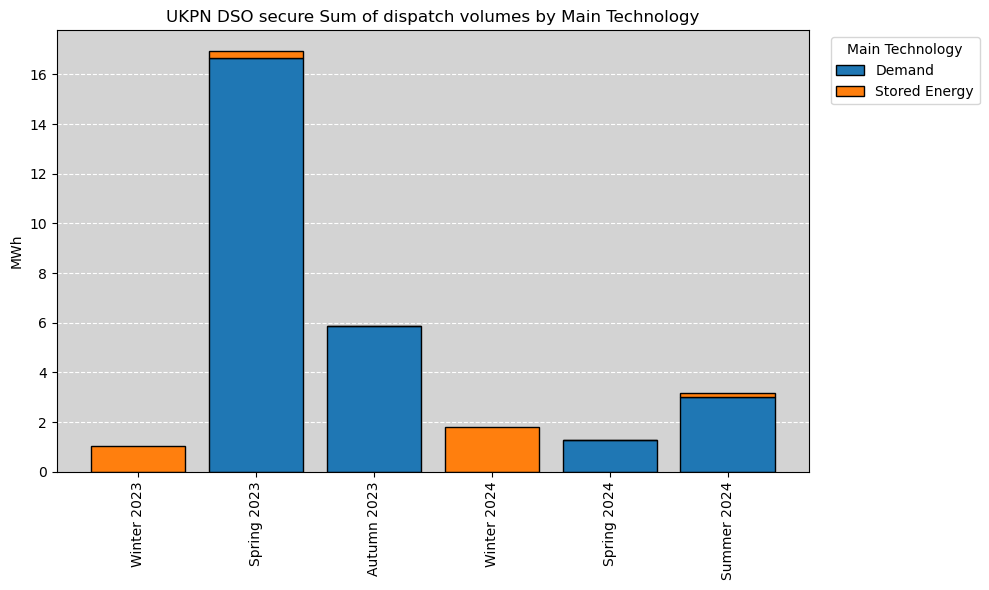

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_16892\3436289143.py:20: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(index=['season','Year'], columns='Main Technology',


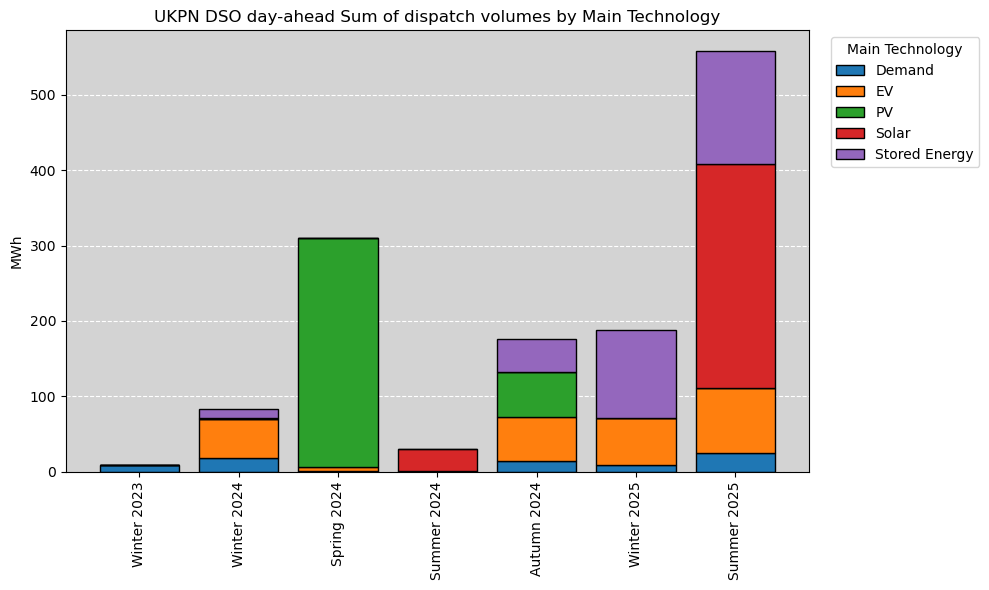

: 

In [ ]:
for product in dispatches['Product'].unique():
    filter_product = dispatches[dispatches['Product']== product]
    

    # mean per row grouped by season, year, technology
    stack_data = (
        filter_product
        .groupby(['season','Year','Main Technology'])['Dispatch Volume (MWh)']
        .sum()
        .reset_index()
    )

    # pivot so each technology is a column
    season_order = ["Winter", "Spring", "Summer", "Autumn"]
    stack_data['season'] = pd.Categorical(stack_data['season'], season_order, ordered=True)

    stack_pivot = (
        stack_data
        .sort_values(['Year','season'])
        .pivot_table(index=['season','Year'], columns='Main Technology',
                    values='Dispatch Volume (MWh)', fill_value=0).sort_index(level=['Year','season'], sort_remaining=False)
    )

    # labels like "Winter 2024"
    x_labels = [f"{s} {y}" for s, y in stack_pivot.index.to_list()]

    # --- plotting ---
    fig, ax = plt.subplots(figsize=(10,6))
    bottom = np.zeros(len(stack_pivot))

    for tech in stack_pivot.columns:
        heights = stack_pivot[tech].to_numpy()
        ax.bar(x_labels, heights, bottom=bottom, edgecolor='black', label=tech)
        bottom += heights


    ax.set_facecolor('lightgrey')
    ax.grid(axis='y', color='white', linestyle='--', linewidth=0.8)
    ax.set_axisbelow(True)
    plt.xticks(rotation=90)
    plt.ylabel("MWh")
    plt.title(f"UKPN DSO {product} Sum of dispatch volumes by Main Technology")
    ax.legend(title="Main Technology", bbox_to_anchor=(1.02,1), loc='upper left')
    plt.tight_layout()
    plt.show()


In [ ]:
dispatches

In [61]:
per_asset_avg

,season,Year,Flexible Unit ID,Main Technology,avg_volume
0,Interseason,2023,BDTf-CUBL-001,Demand,0.750000
1,Interseason,2023,BDTf-SMSE-001,Stored Energy (all stored energy irrespective ...,4.720000
2,Interseason,2023,BMAH-EVEN-001,Stored Energy (all stored energy irrespective ...,0.045000
3,Interseason,2023,Bran-CUBL-001,Demand,0.525000
4,Interseason,2023,Broa-EVEN-001,Stored Energy (all stored energy irrespective ...,0.014000
...,...,...,...,...,...
708,Winter,2025,west-letchworth-shefford-biggleswade-da-ev-por...,EV,0.216667
709,Winter,2025,worthing-grid-a-da-battery-portfolio,Demand,0.092432
710,Winter,2025,worthing-grid-a-da-ev-portfolio,EV,0.267568
711,Winter,2025,wrotham-da-battery-portfolio,Demand,0.049268


In [62]:
stack_data

,season,Year,Main Technology,avg_volume
0,Interseason,2023,Demand,32.517525
1,Interseason,2023,Fossil - Gas,40.320667
2,Interseason,2023,Solar,18.369056
3,Interseason,2023,Stored Energy (all stored energy irrespective ...,5.501800
4,Interseason,2023,Wind,49.375000
5,Interseason,2024,Demand,57.887313
6,Interseason,2024,EV,6.427225
7,Interseason,2024,Fossil - Gas,60.871101
8,Interseason,2024,PV,12.024000
9,Interseason,2024,Solar,29.473328


In [22]:
stack_pivot

Main Technology   Biofuel - Landfill gas    Demand        EV  Fossil - Gas  \
season      Year                                                             
Interseason 2023                     0.0  1.600462  0.000000      6.368783   
            2024                     0.0  1.873607  0.407057      5.051135   
            2025                     0.0  1.818226  0.124283      6.072373   
Summer      2023                     0.0  0.954925  0.000000      6.341300   
            2024                   235.6  1.971764  0.099224      5.726710   
Winter      2023                     0.0  2.326499  0.000000      5.737919   
            2024                     0.0  2.003105  0.199368      5.228600   
            2025                     0.0  1.113644  0.068639      2.557591   

Main Technology         PV      Solar  \
season      Year                        
Interseason 2023  0.000000   7.131500   
            2024  6.012000   9.486691   
            2025  0.000000   8.770779   
Summer      2023  0.000000  11.289147   
            2024  8.946397  11.278188   
Winter      2023  0.000000   4.801608   
            2024  0.000000   0.477500   
            2025  0.000000   0.000000   

Main Technology   Stored Energy (all stored energy irrespective of the original energy source)  \
season      Year                                                                                 
Interseason 2023                                           0.303360                              
            2024                                           0.461599                              
            2025                                           1.163945                              
Summer      2023                                           0.087721                              
            2024                                           0.437191                              
Winter      2023                                           0.382049                              
            2024                                           0.214705                              
            2025                                           0.448314                              

Main Technology        Wind  
season      Year             
Interseason 2023  24.687500  
            2024  81.119231  
            2025  20.719630  
Summer      2023   0.000000  
            2024  12.000000  
Winter      2023  13.118182  
            2024  13.115761  
            2025   6.419850

In [17]:
dispatches[dispatches['dno']=='nged']['Main Technology'].value_counts()

Main Technology
Demand                                                                          65909
Stored energy (all stored energy irrespective of the original energy source)     7906
Biofuel - Landfill gas                                                            158
Fossil - Gas                                                                       66
Fossil - Other                                                                     45
Data not available                                                                 13
Solar                                                                               1
Name: count, dtype: int64

In [16]:
dispatches[dispatches['dno']=='ukpn']['Main Technology'].value_counts()

Main Technology
Stored Energy (all stored energy irrespective of the original energy source)    3942
Demand                                                                          3772
EV                                                                              2073
Fossil - Gas                                                                    1293
Wind                                                                             239
Solar                                                                            112
PV                                                                                44
Biofuel - Landfill gas                                                            10
Name: count, dtype: int64

In [ ]:
# PBR : Primary Balancing Responsible;  The Balancing Responsible Party who financially responsible for balancing a specific supply/demand position
# NBR : Named Balancing Responsible;  The Balancing Responsible Party assigned for a particular meter or connection point
# DLH :  Distribution License Holder; DNO
# LFS : Local flex service; DSO
# PQR – Pre-Qualification Report ????
# NQR – Notification of Qualification Result : outcome of the DSO’s evaluation of the PQR lke are they qualified to offer service

#STOR (Day Ahead) tells you how much reserve is planned and available.
#STOR (Historic) shows what was actually used — useful for tracking system stress events, aggregator performance, and market efficiency.


# Other: Wholesale...

In [147]:
wsp = pd.read_csv(path_dir / "data/Nordpoolprices_2025-04-07.csv", parse_dates = [0,4], index_col = 0)
wsp

,PRICE,VOLUMEPURCHASEMW,VOLUMESALEMW,LOAD_TIMESTAMP
STARTDATETIME,,,,
2018-01-01 00:00:00,47.14,0.0,0.0,2025-04-07 09:31:36.711
2018-01-01 01:00:00,54.60,0.0,0.0,2025-04-07 09:31:36.711
2018-01-01 02:00:00,46.63,0.0,0.0,2025-04-07 09:31:36.711
2018-01-01 03:00:00,39.90,0.0,0.0,2025-04-07 09:31:36.711
2018-01-01 04:00:00,23.41,0.0,0.0,2025-04-07 09:31:36.711
...,...,...,...,...
2025-04-08 17:00:00,114.07,19222.8,18223.0,2025-04-07 09:31:36.711
2025-04-08 18:00:00,124.59,19740.7,18740.9,2025-04-07 09:31:36.711
2025-04-08 19:00:00,112.72,19097.6,18097.8,2025-04-07 09:31:36.711


In [157]:
wsp['PRICE'].describe()

count    61821.000000
mean        90.991828
std         81.073953
min        -54.170000
25%         45.060000
50%         68.600000
75%        105.620000
max       2500.010000
Name: PRICE, dtype: float64

In [83]:

# ------------------------------
#  ASSET PROJECTIONS (thousands)
# ------------------------------

years = [2024, 2025, 2026, 2027, 2028, 2029,
         2030, 2031, 2032, 2033, 2034, 2035]

ev_home_charge_points = [1268, 1689, 2254, 2916, 3643, 4469,
                         5385, 6323, 7269, 8207, 9136, 10052]

pv_lt_10 = [1564, 1724, 1904, 2106, 2331, 2584,
            2867, 3095, 3324, 3552, 3780, 4009]

pv_10_to_20 = [6, 8, 9, 12, 16, 19,
               21, 23, 26, 28, 29, 30]

heat_pumps = [521, 645, 817, 1173, 1517, 1801,
              2110, 2441, 2799, 3179, 3570, 3973]

bess = [183, 262, 349, 441, 536, 637,
        743, 839, 935, 1031, 1127, 1223]

assets = pd.DataFrame({
    "Year": years,
    "EV": ev_home_charge_points,
    "PV": pv_lt_10,
    "PV_10_20": pv_10_to_20,
    "HeatPumps": heat_pumps,
    "BESS": bess
})


### correlation price asset presence

In [31]:
cost_df = pd.read_csv(path_dir / 'data/cost-output_summary_resi-weekly_04-12-2025_1007.csv', parse_dates = ['Date'], usecols = [0,1,4,6,11,12])

cost_df = cost_df[cost_df['cost_metric'] == 'pwr-fwc_cost']
cost_df.drop(columns='cost_metric')

cost_df = cost_df[cost_df['Register'] == 'All']
cost_df

,FUEL,GSP_GROUP,Register,cost_metric,Date,Cost_MWH
3963,E,_A,All,pwr-fwc_cost,2025-12-01,83.545372
3997,E,_A,All,pwr-fwc_cost,2026-01-01,96.661596
4031,E,_A,All,pwr-fwc_cost,2026-02-01,94.928670
4065,E,_A,All,pwr-fwc_cost,2026-03-01,83.865978
4099,E,_A,All,pwr-fwc_cost,2026-04-01,81.137572
...,...,...,...,...,...,...
82673,E,_P,All,pwr-fwc_cost,2030-05-01,68.925683
82707,E,_P,All,pwr-fwc_cost,2030-06-01,72.128257
82741,E,_P,All,pwr-fwc_cost,2030-07-01,71.973166
82775,E,_P,All,pwr-fwc_cost,2030-08-01,70.122100


In [32]:
# ---- Monthly -> Annual panel by GSP group
cost = cost_df.copy()
cost["Date"] = pd.to_datetime(cost["Date"])
cost = cost.query('FUEL == "E" and Register == "All" and cost_metric == "pwr-fwc_cost"').copy()
cost["Year"] = cost["Date"].dt.year

# Keep only years where we have assets
cost = cost[cost["Year"].isin(assets["Year"])]

# Panel = annual mean by GSP group (so we retain cross-sectional variation)
panel = (cost
         .groupby([ "Year"], as_index=False)["Cost_MWH"]
         .mean())

panel = panel.merge(assets, on="Year", how="left")
panel.sort_values(["Year"], inplace=True)
panel

,Year,Cost_MWH,EV,PV_lt10,PV_10_20,HeatPumps,BESS
0,2025,82.566534,1689,1724,8,645,262
1,2026,83.225514,2254,1904,9,817,349
2,2027,81.239421,2916,2106,12,1173,441
3,2028,80.101970,3643,2331,16,1517,536
4,2029,79.881094,4469,2584,19,1801,637
5,2030,77.439717,5385,2867,21,2110,743


In [33]:
import statsmodels.formula.api as smf

# Time trend (centered for stability)
panel["t"] = panel["Year"] - panel["Year"].min()

# entity fixed effects via C(GSP_GROUP), add a simple time trend
formula_levels = "Cost_MWH ~ t + EV + PV_lt10 + PV_10_20 + HeatPumps + BESS + C(GSP_GROUP)"

ols_levels = smf.ols(formula=formula_levels, data=panel).fit(
    cov_type="cluster", cov_kwds={"groups": panel["GSP_GROUP"]}  # cluster SE by entity
)
print(ols_levels.summary())


PatsyError: Error evaluating factor: NameError: name 'GSP_GROUP' is not defined
    Cost_MWH ~ t + EV + PV_lt10 + PV_10_20 + HeatPumps + BESS + C(GSP_GROUP)
                                                                ^^^^^^^^^^^^

In [ ]:
for provider in panel['Registered DFS Participant'].unique():
    
    for status in ['Rejected', 'Accepted']:
        for event in ['Live', 'Test', 0]:

            for corr, pval in zip(['pearson', 'spearman', 'kendall'], [pearsonr, spearmanr, kendalltau]):
            
                panel = DFS_data[(DFS_data['Status'] == status) & (DFS_data['Service Requirement Type'] != event) & (DFS_data['Registered DFS Participant']==provider)]
                
                if panel.shape[0] < 20:
                    continue
                
                x, y = clean_xy(
                panel,
                xcol='price_wz',
                ycol='vol_wz',
                lag=0
            )
                if x is None:
                    continue
                
                print(provider)
                
                coef, pval = pval(x, y)
                if event == 0:
                    print(f"with both live and test events, {round(coef,3)} for {corr} with pval {round(pval,3)}")
                                
                else:
                    print(f"{status}, removed {event}: {round(coef,3)} for {corr} with pval {round(pval,3)}")
        
## INTERPRETATION: 
# Accepted sets: weak positive correlation (seems higher prices more flex for test events) and Rejected sets: near-zero or slight negative --> directionally sensible 
# Still, coef are too small --> no evidence that price is a leading factor or that providers are price-responsive.

# Per provider

## forecasted

In [ ]:
panel = pd.read_csv(path_dir / "data/model/forecasted_data/dx_future_requirement.csv", parse_dates = [1,0])

panel = panel[panel['Possibilities'].gt(0)]

panel["Service Type"] = panel["Service Type"].astype(str).str.replace("-", "", regex=False)

panel

,Forecast Created,Forecast Target Month,Service Type,EFA,Interval,Possibilities
5,2025-10-01,2025-10-01,DCH,1,1000-1200,1.000
14,2025-10-01,2025-10-01,DCH,2,1000-1200,1.000
22,2025-10-01,2025-10-01,DCH,3,800-1000,0.125
23,2025-10-01,2025-10-01,DCH,3,1000-1200,0.875
31,2025-10-01,2025-10-01,DCH,4,800-1000,0.375
...,...,...,...,...,...,...
4169,2025-10-01,2026-10-01,DR_L,2,400-600,1.000
4178,2025-10-01,2026-10-01,DR_L,3,400-600,1.000
4187,2025-10-01,2026-10-01,DR_L,4,400-600,1.000
4196,2025-10-01,2026-10-01,DR_L,5,400-600,1.000


In [ ]:
# all columns except Possibilities define a "duplicate group"

panel["Possibilities"] = pd.to_numeric(panel["Possibilities"], errors="coerce")
# keep the row with the max Possibilities in each group
df_best = panel.loc[panel.groupby(['Forecast Target Month', 'Service Type', 'EFA'])["Possibilities"].idxmax()]

df_best

,Forecast Created,Forecast Target Month,Service Type,EFA,Interval,Possibilities
5,2025-10-01,2025-10-01,DCH,1,1000-1200,1.000
14,2025-10-01,2025-10-01,DCH,2,1000-1200,1.000
23,2025-10-01,2025-10-01,DCH,3,1000-1200,0.875
32,2025-10-01,2025-10-01,DCH,4,1000-1200,0.625
41,2025-10-01,2025-10-01,DCH,5,1000-1200,0.625
...,...,...,...,...,...,...
4169,2025-10-01,2026-10-01,DR_L,2,400-600,1.000
4178,2025-10-01,2026-10-01,DR_L,3,400-600,1.000
4187,2025-10-01,2026-10-01,DR_L,4,400-600,1.000
4196,2025-10-01,2026-10-01,DR_L,5,400-600,1.000


In [12]:
bounds = df_best["Interval"].astype(str).str.extract(
    r"^\s*([+-]?\d+(?:\.\d+)?)\s*-\s*([+-]?\d+(?:\.\d+)?)\s*$"
)
df_best[["start","end"]] = bounds.astype(float) 

In [13]:
df_best

,Forecast Created,Forecast Target Month,Service Type,EFA,Interval,Possibilities,start,end
5,2025-10-01,2025-10-01,DCH,1,1000-1200,1.000,1000.0,1200.0
14,2025-10-01,2025-10-01,DCH,2,1000-1200,1.000,1000.0,1200.0
23,2025-10-01,2025-10-01,DCH,3,1000-1200,0.875,1000.0,1200.0
32,2025-10-01,2025-10-01,DCH,4,1000-1200,0.625,1000.0,1200.0
41,2025-10-01,2025-10-01,DCH,5,1000-1200,0.625,1000.0,1200.0
...,...,...,...,...,...,...,...,...
4169,2025-10-01,2026-10-01,DR_L,2,400-600,1.000,400.0,600.0
4178,2025-10-01,2026-10-01,DR_L,3,400-600,1.000,400.0,600.0
4187,2025-10-01,2026-10-01,DR_L,4,400-600,1.000,400.0,600.0
4196,2025-10-01,2026-10-01,DR_L,5,400-600,1.000,400.0,600.0


C:\Users\duval1e\AppData\Local\Temp\ipykernel_25464\3192277056.py:30: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


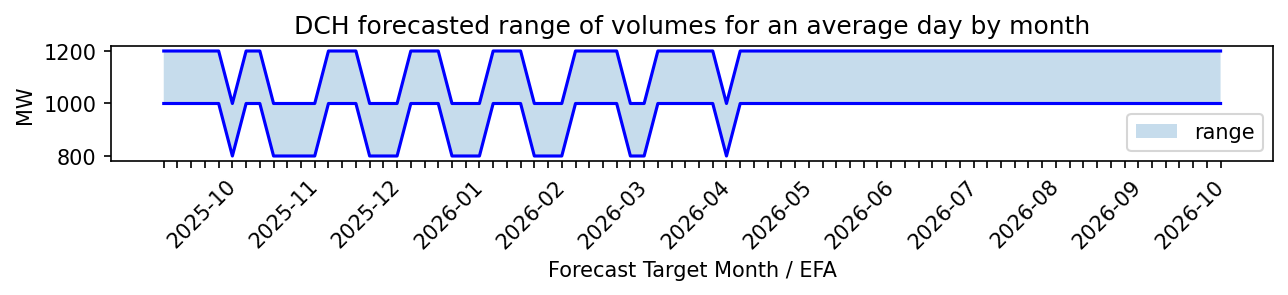

C:\Users\duval1e\AppData\Local\Temp\ipykernel_25464\3192277056.py:30: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


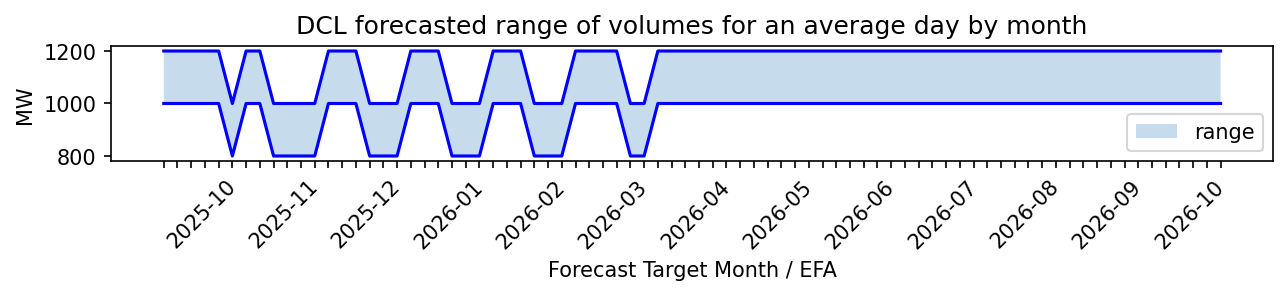

C:\Users\duval1e\AppData\Local\Temp\ipykernel_25464\3192277056.py:30: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


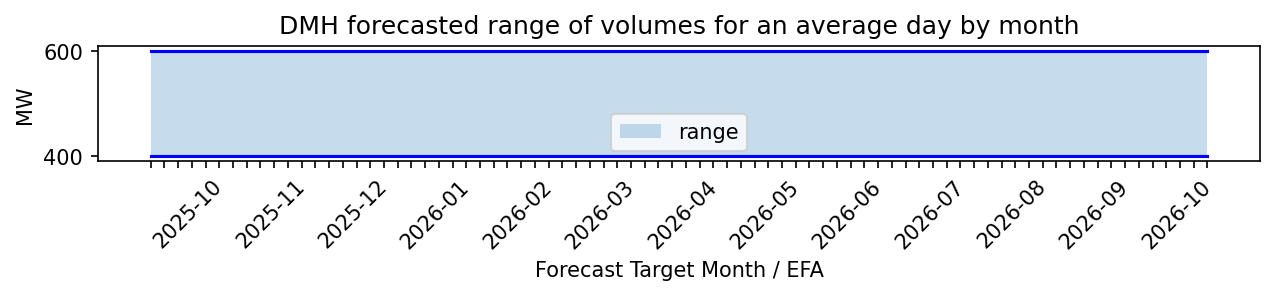

C:\Users\duval1e\AppData\Local\Temp\ipykernel_25464\3192277056.py:30: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


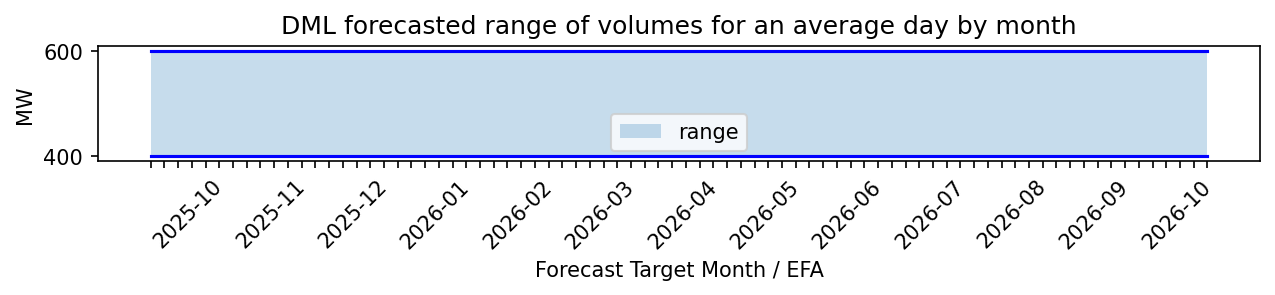

C:\Users\duval1e\AppData\Local\Temp\ipykernel_25464\3192277056.py:30: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


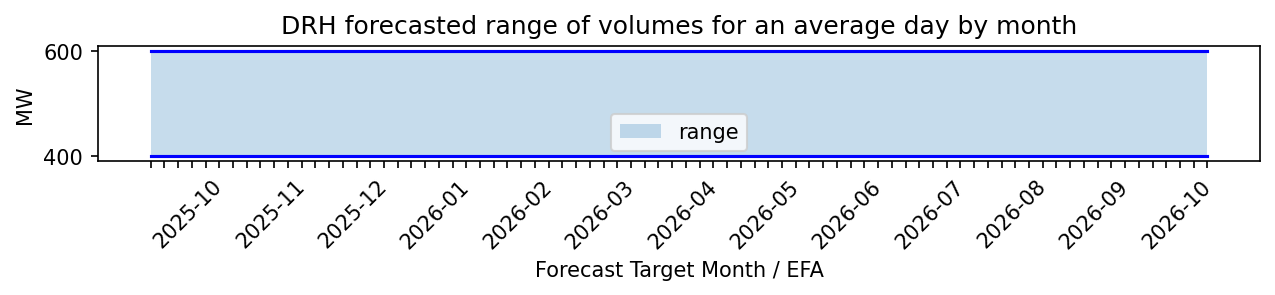

C:\Users\duval1e\AppData\Local\Temp\ipykernel_25464\3192277056.py:30: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


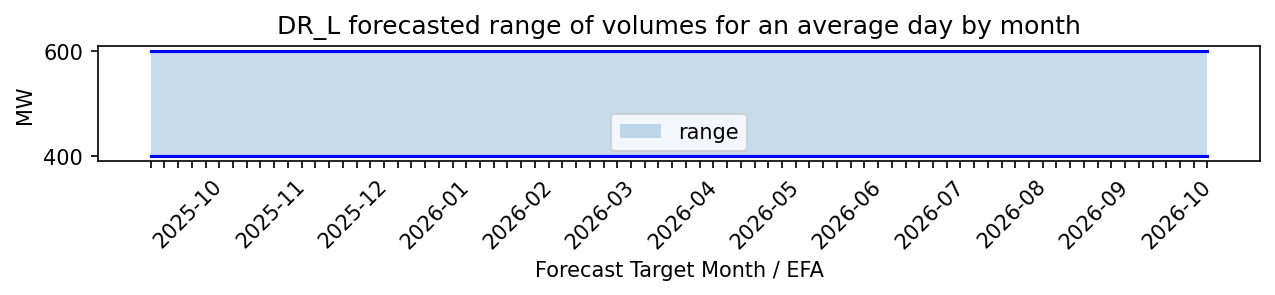

In [14]:
month_col = "Forecast Target Month"
efa_col   = "EFA"
svc_col   = "Service Type"

df_best[month_col] = pd.to_datetime(df_best[month_col])
df_best[efa_col] = df_best[efa_col].astype(str)

for svc, g in df_best.sort_values([month_col, efa_col]).groupby(svc_col, sort=False):
    x_labels = g[month_col].dt.strftime("%Y-%m") + "\n" + g[efa_col]
    x = np.arange(len(g))

    y1 = g["start"].to_numpy()
    y2 = g["end"].to_numpy()

    plt.figure(figsize=(10, 1), dpi=150)
    plt.plot(x, y1, color='blue')
    plt.plot(x, y2, color='blue')
    plt.fill_between(x, y1, y2, alpha=0.25, label="range")
    
    month_labels = g[month_col].dt.strftime("%Y-%m")
    tick_labels = month_labels.where(month_labels.ne(month_labels.shift()), "")

    plt.xticks(x, tick_labels, rotation=45, ha="left")


    plt.xlabel(f"{month_col} / {efa_col}")
    plt.ylabel("MW")
    plt.title(f'{str(svc)} forecasted range of volumes for an average day by month')
    plt.legend()
    plt.tight_layout()
    plt.show()


In [15]:
fc_df = pd.read_csv(path_dir / 'data/cost-output_summary_resi-weekly_04-12-2025_1007.csv', parse_dates = ['Date'], usecols = [0,1,4,6,11,12])

fc_df = fc_df[fc_df['cost_metric'] == 'pwr-fwc_cost']
fc_df.drop(columns='cost_metric')

fc_df = fc_df[fc_df['Register'] == 'All']
fc_df

,FUEL,GSP_GROUP,Register,cost_metric,Date,Cost_MWH
3963,E,_A,All,pwr-fwc_cost,2025-12-01,83.545372
3997,E,_A,All,pwr-fwc_cost,2026-01-01,96.661596
4031,E,_A,All,pwr-fwc_cost,2026-02-01,94.928670
4065,E,_A,All,pwr-fwc_cost,2026-03-01,83.865978
4099,E,_A,All,pwr-fwc_cost,2026-04-01,81.137572
...,...,...,...,...,...,...
82673,E,_P,All,pwr-fwc_cost,2030-05-01,68.925683
82707,E,_P,All,pwr-fwc_cost,2030-06-01,72.128257
82741,E,_P,All,pwr-fwc_cost,2030-07-01,71.973166
82775,E,_P,All,pwr-fwc_cost,2030-08-01,70.122100


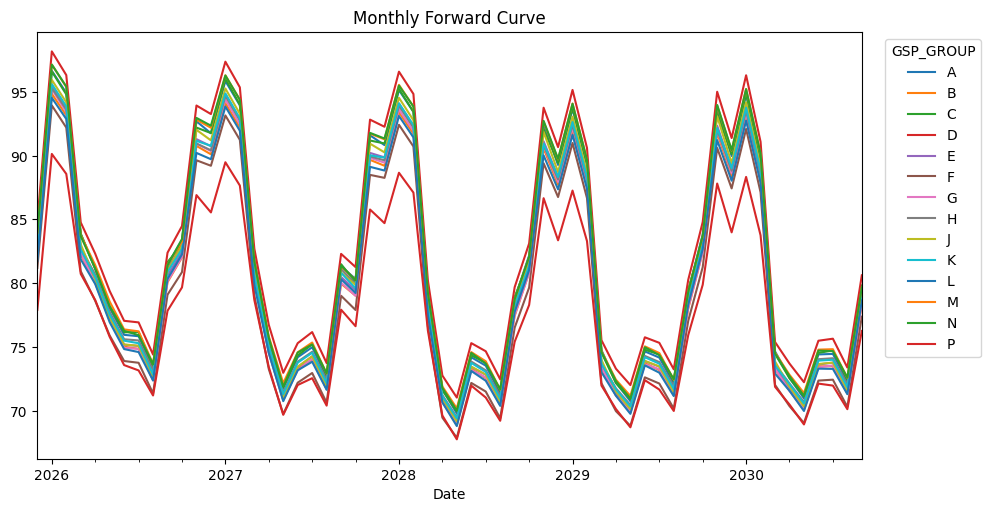

In [16]:
wide = fc_df.pivot_table(index="Date", columns="GSP_GROUP", values="Cost_MWH", aggfunc="mean").sort_index()
wide.columns = wide.columns.str.lstrip("_")

ax = wide.plot(figsize=(10,5))
ax.legend(title="GSP_GROUP", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.title('Monthly Forward Curve')
plt.show()

Date
2027-01-01    94.757816
2027-02-01    92.819791
2027-03-01    80.796196
2027-04-01    74.964580
2027-05-01    71.244750
Freq: MS, Name: Cost_MWH, dtype: float64


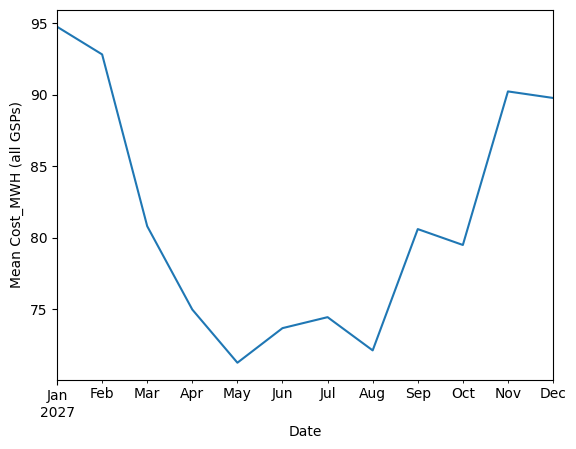

In [17]:
fc_df["Date"] = pd.to_datetime(fc_df["Date"])

monthly_mean_all_gsp = (
    fc_df
    .set_index("Date")["Cost_MWH"]
    .resample("MS")          # month start
    .mean()
)
monthly_mean_all_gsp = monthly_mean_all_gsp['2027']
print(monthly_mean_all_gsp.head())

# plot
monthly_mean_all_gsp.plot()
plt.ylabel("Mean Cost_MWH (all GSPs)")
plt.show()


## rev estimation

In [85]:
### using baseline as 0 

assets[['EV', 'PV', 'PV_10_20', 'HeatPumps', 'BESS']] *= 1000

In [86]:
assets

,Year,EV,PV,PV_10_20,HeatPumps,BESS
0,2024,1268000,1564000,6000,521000,183000
1,2025,1689000,1724000,8000,645000,262000
2,2026,2254000,1904000,9000,817000,349000
3,2027,2916000,2106000,12000,1173000,441000
4,2028,3643000,2331000,16000,1517000,536000
5,2029,4469000,2584000,19000,1801000,637000
6,2030,5385000,2867000,21000,2110000,743000
7,2031,6323000,3095000,23000,2441000,839000
8,2032,7269000,3324000,26000,2799000,935000
9,2033,8207000,3552000,28000,3179000,1031000


In [159]:
cost_df = pd.read_csv(path_dir / 'data/cost-output_summary_resi-weekly_04-12-2025_1007.csv', parse_dates = ['Date'], usecols = [0,1,4,6,11,12])

cost_df = cost_df[cost_df['cost_metric'] == 'pwr-fwc_cost']
cost_df.drop(columns='cost_metric')

cost_df = cost_df[cost_df['Register'] == 'Night']

# ---- Monthly -> Annual panel by GSP group
cost = cost_df.copy()
cost["Date"] = pd.to_datetime(cost["Date"])
cost = cost.query('FUEL == "E" and Register == "Night" and cost_metric == "pwr-fwc_cost"').copy()
cost["Year"] = cost["Date"].dt.year
cost["Month"] = cost["Date"].dt.month

# Keep only years where we have assets
cost = cost[cost["Year"].isin(assets["Year"])]

# Panel = annual mean by GSP group (so we retain cross-sectional variation) #actually no lol
panel = (cost
         .groupby(["Year", "Month"], as_index=False)["Cost_MWH"]
         .mean())

panel = panel.merge(assets, on="Year", how="left")
panel.sort_values(["Year"], inplace=True)
panel

,Year,Month,Cost_MWH,EV,PV,PV_10_20,HeatPumps,BESS
0,2025,12,60.454235,1689000,1724000,8000,645000,262000
1,2026,1,68.280320,2254000,1904000,9000,817000,349000
2,2026,2,67.558156,2254000,1904000,9000,817000,349000
3,2026,3,62.745309,2254000,1904000,9000,817000,349000
4,2026,4,67.812648,2254000,1904000,9000,817000,349000
5,2026,5,65.936469,2254000,1904000,9000,817000,349000
6,2026,6,63.915503,2254000,1904000,9000,817000,349000
7,2026,7,66.243059,2254000,1904000,9000,817000,349000
8,2026,8,63.821362,2254000,1904000,9000,817000,349000
9,2026,9,66.047308,2254000,1904000,9000,817000,349000


In [161]:
panel #345000 / 18500000 20%
#compared to zapmap lower to 30 % P483 has a but de register 345000 = allows domestic customers to actually participate in that market even if they are NOT half‑hourly settled

,Year,Cost_MWH,EV,BESS,PV,revenue_EV,revenue_BESS
0,2025,60.454235,1689000,262000,1724000,7.167926e+07,2.668556e+06
1,2026,63.654726,2254000,349000,1904000,1.007214e+08,3.742867e+06
2,2027,62.708051,2916000,441000,2106000,1.283654e+08,4.659188e+06
3,2028,61.026287,3643000,536000,2331000,1.560678e+08,5.510996e+06
4,2029,61.027642,4469000,637000,2584000,1.914582e+08,6.549594e+06
5,2030,60.683394,5385000,743000,2867000,2.293996e+08,7.596386e+06


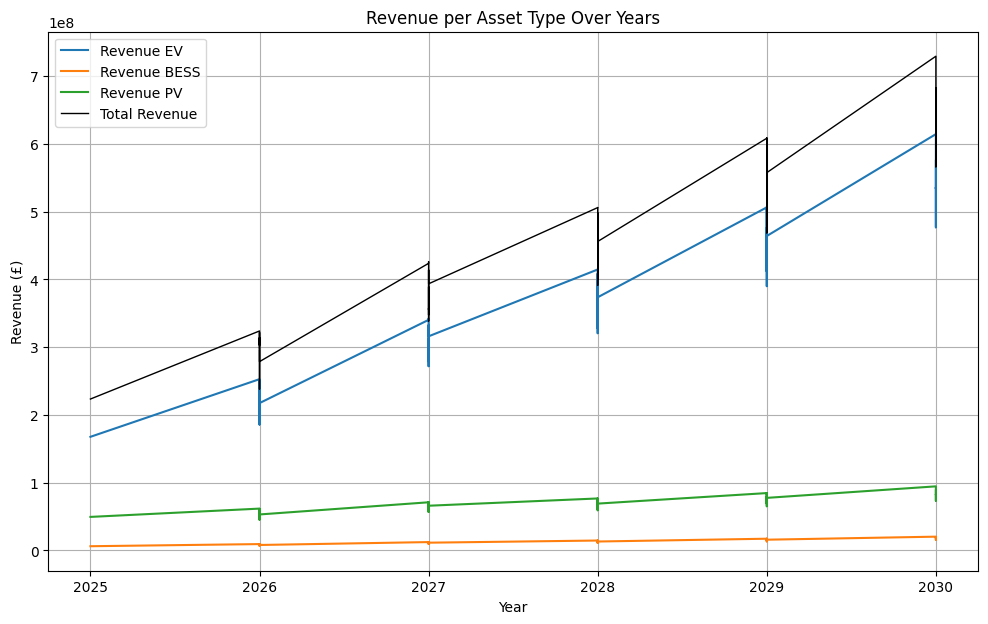

In [100]:
cost_df = pd.read_csv(path_dir / 'data/cost-output_summary_resi-weekly_04-12-2025_1007.csv', parse_dates = ['Date'], usecols = [0,1,4,6,11,12])

cost_df = cost_df[cost_df['cost_metric'] == 'pwr-fwc_cost']
cost_df.drop(columns='cost_metric')

cost_df = cost_df[cost_df['Register'] == 'Night']

# ---- Monthly -> Annual panel by GSP group
cost = cost_df.copy()
cost["Date"] = pd.to_datetime(cost["Date"])
cost = cost.query('FUEL == "E" and Register == "Night" and cost_metric == "pwr-fwc_cost"').copy()
cost["Year"] = cost["Date"].dt.year
cost["Month"] = cost["Date"].dt.month

# Keep only years where we have assets
cost = cost[cost["Year"].isin(assets["Year"])]

# Panel = annual mean by GSP group (so we retain cross-sectional variation) #actually no lol
panel = (cost
         .groupby(["Year", "Month"], as_index=False)["Cost_MWH"]
         .mean())

panel = panel.merge(assets, on="Year", how="left")
panel.sort_values(["Year"], inplace=True)

# DAILY flexible MWh (for EV, BESS, HP)
MWh_EV_daily = 0.050 * 0.40 * 0.90      # EV battery
MWh_BESS_daily = 0.012 * 0.40 * 0.90    # Home battery
MWh_HP_daily = 1.5/1000 * 0.40          # Heat pump load shifting

# Convert daily → yearly
MWh_EV_year = MWh_EV_daily * 365
MWh_BESS_year = MWh_BESS_daily * 365
MWh_HP_year = MWh_HP_daily * 365

# PV (already yearly)
MWh_PV_lt10 = 1.90     # 5 kW system
MWh_PV_10_20 = 4.56    # 12 kW system

# dictionary mapping
energy_per_asset = {
    "EV": MWh_EV_year,
    "BESS": MWh_BESS_year,
    "PV": MWh_PV_lt10,
} 

# 50% participation factor
participation = 0.25 

# Create revenue columns
for col, mwh in energy_per_asset.items():
    panel[f"revenue_{col}"] = (
        panel[col] *
        mwh *
        participation *
        panel["Cost_MWH"]
    )

# total revenue
panel["total_revenue"] = panel[[f"revenue_{c}" for c in energy_per_asset]].sum(axis=1)

# Plot revenue
plt.figure(figsize=(12,7))
for col in energy_per_asset:
    plt.plot(panel["Year"], panel[f"revenue_{col}"], label=f"Revenue {col}")

plt.plot(panel["Year"], panel["total_revenue"], 
         label="Total Revenue", linewidth=1, color="black")

plt.title("Revenue per Asset Type Over Years")
plt.xlabel("Year")
plt.ylabel("Revenue (£)")
plt.legend()
plt.grid(True)
plt.show() ###monthly ### per ev

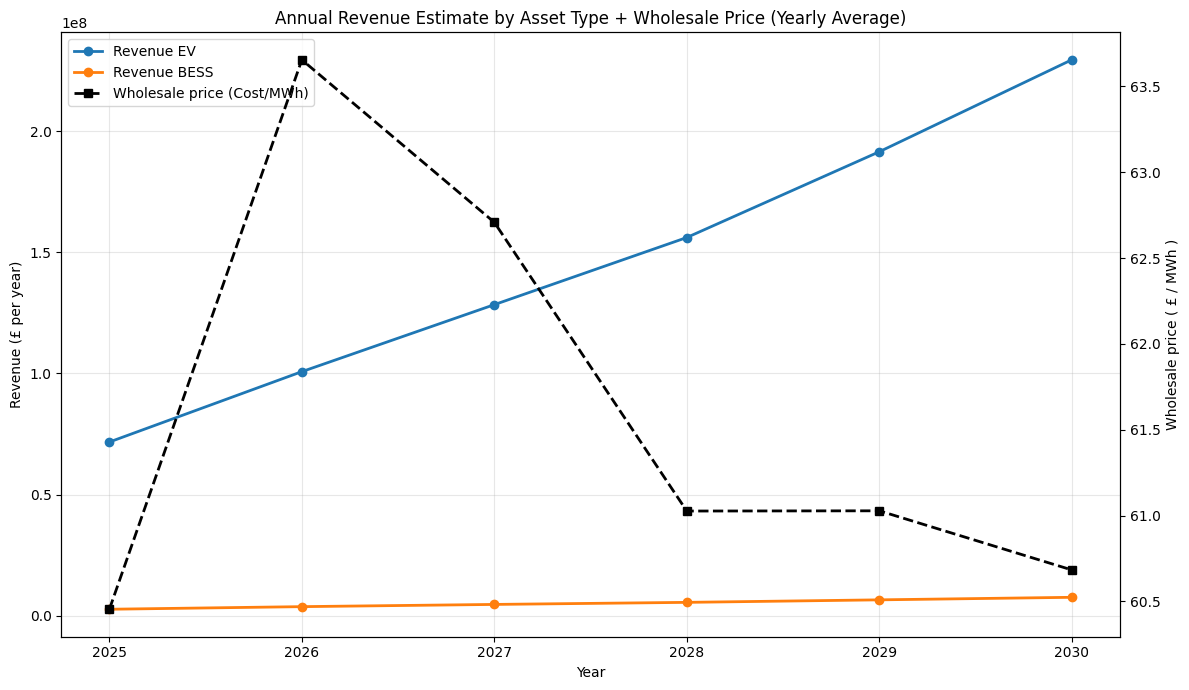

In [160]:
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------------
# 1) LOAD COST DATA
# ----------------------------------
cost_df = pd.read_csv(
    path_dir / 'data/cost-output_summary_resi-weekly_04-12-2025_1007.csv',
    parse_dates=['Date'],
    usecols=[0,1,4,6,11,12]   # as you originally had
)

# Filter to Night register + correct metric
cost_df = cost_df[cost_df['cost_metric'] == 'pwr-fwc_cost']
cost_df = cost_df[cost_df['Register'] == 'Night']
cost_df = cost_df[cost_df['FUEL'] == 'E']

# Extract Year
cost_df["Date"] = pd.to_datetime(cost_df["Date"])
cost_df["Year"] = cost_df["Date"].dt.year

# ----------------------------------
# 2) KEEP ONLY YEARS THAT EXIST IN THE ASSETS TABLE
# ----------------------------------
cost = cost_df.copy()
cost = cost[cost["Year"].isin(assets["Year"])]

# ----------------------------------
# 3) YEARLY PANEL (NO MONTH, NO SEASON)
#    Just: average Cost_MWH per Year
# ----------------------------------
panel = (
    cost
    .groupby("Year", as_index=False)["Cost_MWH"]
    .mean()
)

# ----------------------------------
# 4) MERGE ASSET PROJECTIONS
# ----------------------------------
panel = panel.merge(assets[["Year", "EV", "BESS", "PV"]], on="Year", how="left")

panel = panel.sort_values("Year")

flexible_load = 0.3
# ----------------------------------
# 5) ENERGY / PARTICIPATION ASSUMPTIONS
# ----------------------------------
# DAILY flexible MWh
MWh_EV_daily   = 0.050 * flexible_load * 0.90
MWh_BESS_daily = 0.012 * flexible_load * 0.90
MWh_HP_daily   = 1.5/1000 * flexible_load    # HP not used but left here

# Convert daily → YEARLY
MWh_EV_year   = MWh_EV_daily * 4 * 52
MWh_BESS_year = MWh_BESS_daily * 4 * 52

# PV (yearly already)
MWh_PV_lt10 = 1.90

energy_per_asset = {
    "EV":   MWh_EV_year,
    "BESS": MWh_BESS_year,
}

participation = 0.25

# ----------------------------------
# 6) REVENUE CALCULATION (YEARLY)
# ----------------------------------
for col, mwh in energy_per_asset.items():
    panel[f"revenue_{col}"] = (
        panel[col]             # asset count
        * mwh                  # MWh/year per asset
        * participation        
        * panel["Cost_MWH"]    # £/MWh
    )




# ----------------------------------
# 7) PLOT (YEARLY ONLY) with secondary axis for Cost_MWH
# ----------------------------------
fig, ax1 = plt.subplots(figsize=(12, 7))

# Left axis: revenues (EV, BESS)
colors = {
    "EV":  "#1f77b4",  # blue
    "BESS":"#ff7f0e",  # orange
}

for col in energy_per_asset:
    ax1.plot(
        panel["Year"],
        panel[f"revenue_{col}"],
        marker="o",
        lw=2,
        label=f"Revenue {col}",
        color=colors.get(col, None)
    )

ax1.set_xlabel("Year")
ax1.set_ylabel("Revenue (£ per year)")
ax1.grid(True, which="both", alpha=0.3)

# Right axis: wholesale price (Cost_MWH)
ax2 = ax1.twinx()
ax2.plot(
    panel["Year"],
    panel["Cost_MWH"],
    color="black",
    lw=2,
    ls="--",
    marker="s",
    label="Wholesale price (Cost/MWh)"
)
ax2.set_ylabel("Wholesale price ( £ / MWh )")

# Title
plt.title("Annual Revenue Estimate by Asset Type + Wholesale Price (Yearly Average)")

# Build a joint legend (lines from both axes)
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper left")

plt.tight_layout()
plt.show()

Total VTP-like revenue (period): £681,556,149
Total deviation volume (period): 11,063,291.6 MWh
Annualised £/EV tracker (latest): £180/EV/year
Implied MWh per active EV per year: 3.29 MWh/EV/year
Active EVs (to-date average): 794,799


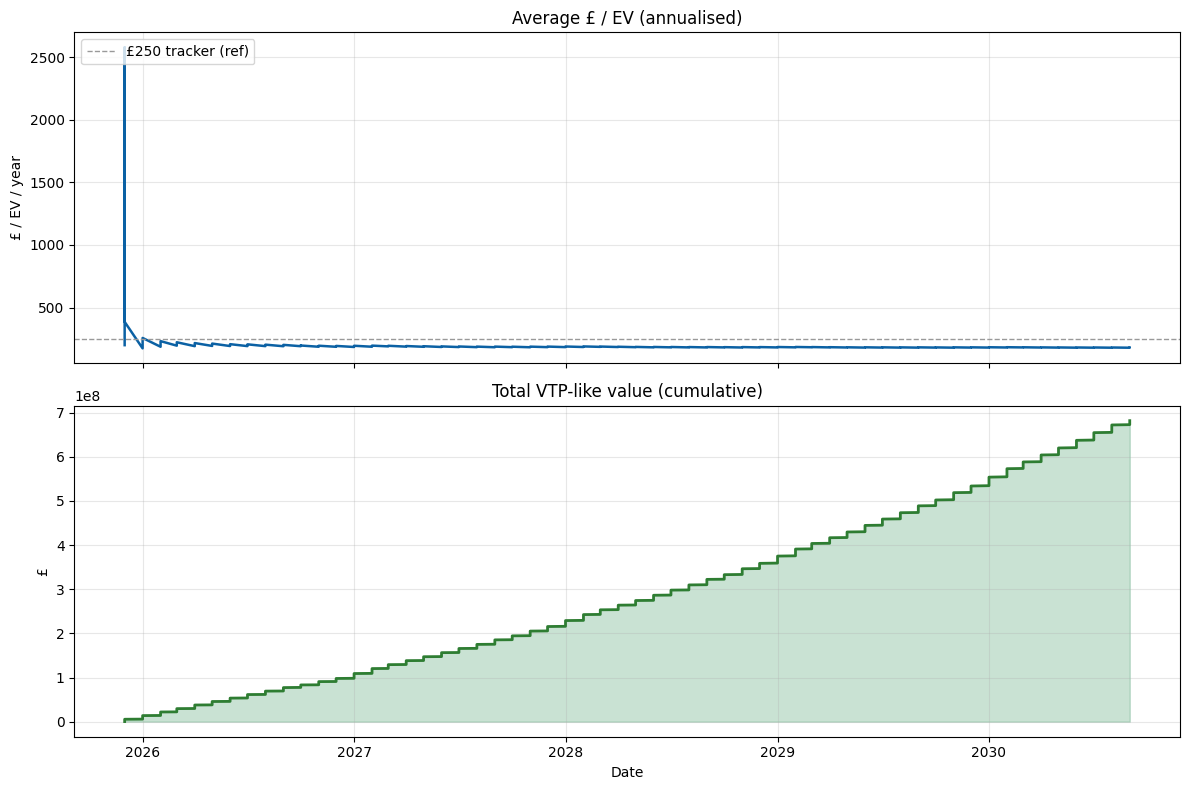

In [133]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ======================================
# 0) Inputs you can tune
# ======================================
# Share of EVs that are registered & actively participating in VTP
consent_rate = 0.22    # 22% of fleet is 'active'—tune this

# Average deviation per ACTIVE EV per day (kWh/day)
# Baseline = 0 ⇒ deviation = this many kWh/day per active EV (on average)
deviation_kwh_per_EV_day = 9.0   # ~3.285 MWh/year per active EV

# Optional: cap or floor the per-period 'days' if your Date series is irregular
cap_min_days = 1
cap_max_days = 14

# ======================================
# 1) Prepare cost data
#  - cost_df must be filtered already to Night/Electric/metric
#  - must include Date, Cost_MWH
# ======================================
cost = cost_df.copy()
cost = cost.sort_values("Date").reset_index(drop=True)

# Compute period duration in days (next_date - this_date)
# For last period, use median delta
next_date = cost["Date"].shift(-1)
days = (next_date - cost["Date"]).dt.days

if days.isna().any():
    median_days = int(days.dropna().median()) if not days.dropna().empty else 7
    days = days.fillna(median_days)

# keep days in a safe range
days = days.clip(lower=cap_min_days, upper=cap_max_days)
cost["period_days"] = days

# ======================================
# 2) Merge assets to get EV counts per year, then compute ACTIVE EVs
#    assets must have columns: Year, EV (counts, NOT thousands)
# ======================================
cost["Year"] = cost["Date"].dt.year
panel = cost.merge(assets[["Year", "EV"]], on="Year", how="left")

# Active EVs participating in VTP
panel["EV_active"] = panel["EV"] * consent_rate

# ======================================
# 3) VTP-like deviation volume and revenue (baseline = 0)
#    deviation energy in MWh per period for the active fleet:
#    EV_active * (deviation_kWh/day / 1000) * days
# ======================================
deviation_MWh_per_EV_day = deviation_kwh_per_EV_day / 1000.0
panel["Deviation_MWh_period"] = (
    panel["EV_active"] * deviation_MWh_per_EV_day * panel["period_days"]
)

# Period revenue: deviation MWh * price (£/MWh)
panel["Revenue_period"] = panel["Deviation_MWh_period"] * panel["Cost_MWH"]

# ======================================
# 4) Running KPIs:
#    - Cumulative revenue
#    - Average £/EV (annualised) tracker, like your slide
# ======================================
panel["Revenue_cum"] = panel["Revenue_period"].cumsum()

# Elapsed days since the first timestamp
panel["elapsed_days"] = (panel["Date"] - panel["Date"].iloc[0]).dt.days + panel["period_days"]

# Use the latest EV_active as a simple denominator proxy
# (Alternative: use average EV_active to date)
panel["EV_active_to_date"] = panel["EV_active"].expanding().mean()

# Annualised £/EV tracker:
# tracker_t = (Revenue_cum_to_date / EV_active_to_date) / (elapsed_days/365)
panel["Annualised_GBP_per_EV"] = (
    panel["Revenue_cum"] / panel["EV_active_to_date"] / (panel["elapsed_days"] / 365.0)
)

# ======================================
# 5) Summaries for quick sanity-check
# ======================================
total_rev = panel["Revenue_period"].sum()
total_dev = panel["Deviation_MWh_period"].sum()
last_avg_ev = panel["EV_active_to_date"].iloc[-1]
annualised_per_ev = panel["Annualised_GBP_per_EV"].iloc[-1]

print(f"Total VTP-like revenue (period): £{total_rev:,.0f}")
print(f"Total deviation volume (period): {total_dev:,.1f} MWh")
print(f"Annualised £/EV tracker (latest): £{annualised_per_ev:,.0f}/EV/year")
print(f"Implied MWh per active EV per year: {deviation_kwh_per_EV_day*365/1000:.2f} MWh/EV/year")
print(f"Active EVs (to-date average): {last_avg_ev:,.0f}")

# ======================================
# 6) Plots (like your slide)
# ======================================
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# (A) Average £/EV annualised
ax[0].plot(panel["Date"], panel["Annualised_GBP_per_EV"], color="#0B61A4", lw=1.8)
ax[0].axhline(250, color="#999999", ls="--", lw=1, label="£250 tracker (ref)")
ax[0].set_title("Average £ / EV (annualised)")
ax[0].set_ylabel("£ / EV / year")
ax[0].grid(True, alpha=0.3)
ax[0].legend(loc="upper left")

# (B) Cumulative revenue
ax[1].fill_between(panel["Date"], panel["Revenue_cum"], step="pre", alpha=0.3, color="#4C9F70")
ax[1].plot(panel["Date"], panel["Revenue_cum"], color="#2E7D32", lw=2)
ax[1].set_title("Total VTP-like value (cumulative)")
ax[1].set_ylabel("£")
ax[1].set_xlabel("Date")
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

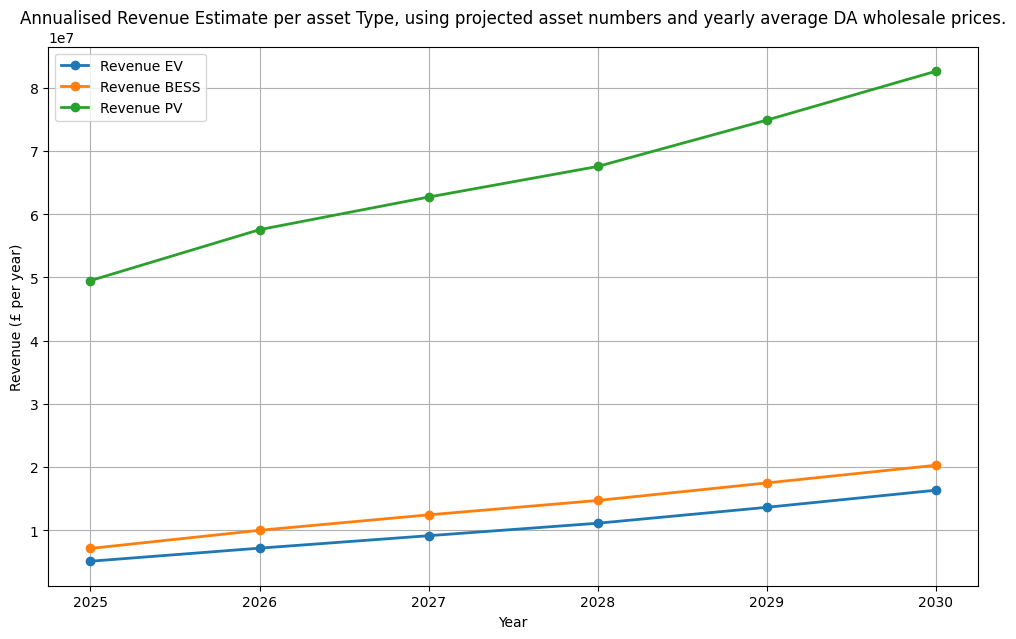

In [134]:



# ----------------------------------
# 1) LOAD COST DATA
# ----------------------------------
cost_df = pd.read_csv(
    path_dir / 'data/cost-output_summary_resi-weekly_04-12-2025_1007.csv',
    parse_dates=['Date'],
    usecols=[0,1,4,6,11,12]   # as you originally had
)

# Filter to Night register + correct metric
cost_df = cost_df[cost_df['cost_metric'] == 'pwr-fwc_cost']
cost_df = cost_df[cost_df['Register'] == 'Night']
cost_df = cost_df[cost_df['FUEL'] == 'E']

# Extract Year
cost_df["Date"] = pd.to_datetime(cost_df["Date"])
cost_df["Year"] = cost_df["Date"].dt.year

# ----------------------------------
# 2) KEEP ONLY YEARS THAT EXIST IN THE ASSETS TABLE
# ----------------------------------
cost = cost_df.copy()
cost = cost[cost["Year"].isin(assets["Year"])]

# ----------------------------------
# 3) YEARLY PANEL (NO MONTH, NO SEASON)
#    Just: average Cost_MWH per Year
# ----------------------------------
panel = (
    cost
    .groupby("Year", as_index=False)["Cost_MWH"]
    .mean()
)

# ----------------------------------
# 4) MERGE ASSET PROJECTIONS
# ----------------------------------
panel = panel.merge(assets[["Year", "EV", "BESS", "PV"]], on="Year", how="left")

panel = panel.sort_values("Year")

# ----------------------------------
# 5) ENERGY / PARTICIPATION ASSUMPTIONS
# ----------------------------------
# ----------------------------------
# 5) UPDATED REALISTIC ENERGY / PARTICIPATION ASSUMPTIONS
# ----------------------------------

# Realistic annual flexible energy per asset
# EV smart charging produces ~0.1–0.3 MWh/yr of flexible demand
MWh_EV_year   = 0.20     # 200 kWh / year

# Residential BESS typical usable cycling (~150 kWh/month)
MWh_BESS_year = 1.80     # 1.8 MWh / year

# PV flexible surplus (unchanged)
MWh_PV_lt10   = 1.90     # 1.9 MWh / year

energy_per_asset = {
    "EV":   MWh_EV_year,
    "BESS": MWh_BESS_year,
    "PV":   MWh_PV_lt10,
}

participation = 0.25
# ----------------------------------
# 6) REVENUE CALCULATION (YEARLY)
# ----------------------------------
for col, mwh in energy_per_asset.items():
    panel[f"revenue_{col}"] = (
        panel[col]             # asset count
        * mwh                  # MWh/year per asset
        * participation        
        * panel["Cost_MWH"]    # £/MWh
    )


# ----------------------------------
# 7) PLOT (YEARLY ONLY)
# ----------------------------------
plt.figure(figsize=(12,7))

for col in energy_per_asset:
    plt.plot(panel["Year"], panel[f"revenue_{col}"],
             marker="o", lw=2, label=f"Revenue {col}")



plt.title("Annualised Revenue Estimate per asset Type, using projected asset numbers and yearly average DA wholesale prices.")
plt.xlabel("Year")
plt.ylabel("Revenue (£ per year)")
plt.grid(True)
plt.legend()
plt.show()

In [125]:
panel

,Year,Cost_MWH,EV,BESS,PV,revenue_EV,revenue_BESS,revenue_PV,total_revenue
0,2025,60.454235,1689000,262000,1724000,1.677111e+08,6.243738e+06,4.950597e+07,2.234608e+08
1,2026,63.654726,2254000,349000,1904000,2.356622e+08,8.757350e+06,5.756933e+07,3.019889e+08
2,2027,62.708051,2916000,441000,2106000,3.003421e+08,1.090131e+07,6.273000e+07,3.739734e+08
3,2028,61.026287,3643000,536000,2331000,3.651586e+08,1.289432e+07,6.756983e+07,4.456227e+08
4,2029,61.027642,4469000,637000,2584000,4.479632e+08,1.532437e+07,7.490533e+07,5.381929e+08
5,2030,60.683394,5385000,743000,2867000,5.367363e+08,1.777360e+07,8.264016e+07,6.371500e+08


In [144]:
# Revenue per EV (yearly KPI)
panel["rev_per_EV"] = panel["revenue_EV"] / (panel["EV"]*participation)

# Optional: avoid tiny denominators early in timeline
panel.loc[panel["EV"] < 1_000, "rev_per_EV"] = None

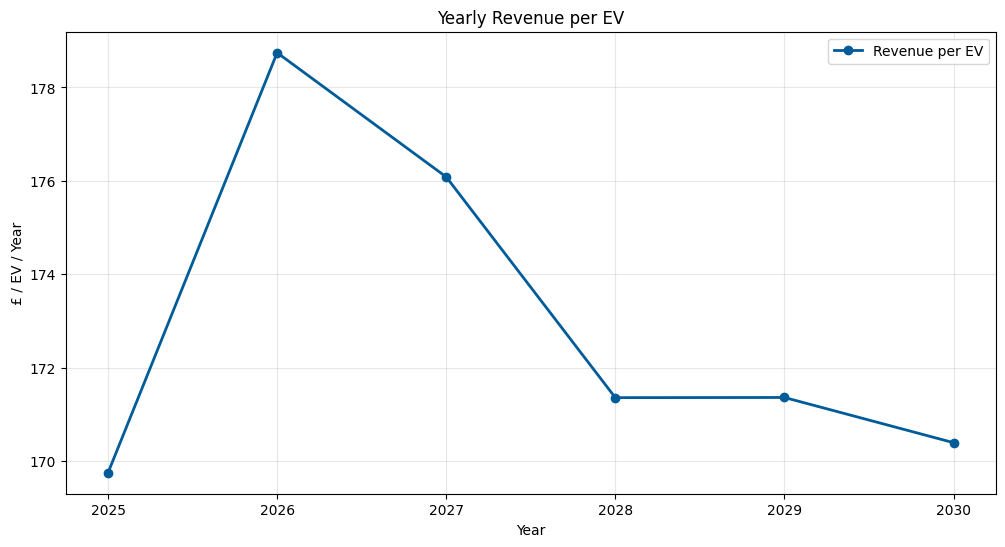

In [145]:
plt.figure(figsize=(12,6))

plt.plot(
    panel["Year"],
    panel["rev_per_EV"],
    marker="o",
    lw=2,
    color="#005c99",
    label="Revenue per EV"
)

plt.title("Yearly Revenue per EV")
plt.xlabel("Year")
plt.ylabel("£ / EV / Year")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()